## Notebook to fit PI models to growth rate data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# suppress warnings
import warnings
warnings.simplefilter('ignore')

### Load data

In [2]:
import re 

# define time resolution
timeres = '1H'
## calculate period based on 1 day
number = int(re.sub(r'\D', '', timeres)) # \D matches any non-digit character

# Read in TSD and rates data _{timeres}
tsd_path = f'/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/seaflow_tsd_project/data/all_seaflow_tsd_mixed_v1_all.pickle'
rates_path = f'/Users/Kathy/Library/CloudStorage/OneDrive-UW/Desktop/UW/seaflow/seaflow_tsd_project/data/final_rates_v1_all.pickle'

all_tsd = pd.read_pickle(tsd_path)
final_rates = pd.read_pickle(rates_path)
# only get good tsd dimensions
good_tsd = final_rates[['cruise', 'cruise_day', 'pop', 'model', 'daily_growth']].merge(all_tsd, how = 'left')

In [3]:
## load growth rate data
clean_growth = pd.read_csv('../data/clean_growth_1H.csv')
## save cruise data 
hot_cruise_clean = pd.read_csv('../data/all_smooth_diel_1H.csv')
## save smoothed mixed layer depth data
smooth_mld = pd.read_csv('../data/all_days-only_mld_1H.csv')

### Fitting cellular growth with PI mocels
- Platt model photoinhibition 
- Platt model no photoinhbition
- Mohammad's new model ([Amirian et al. 2025](https://www.nature.com/articles/s43247-025-02686-3#article-info))

In [6]:
# Platt vs Jassby curve with photoinhibition
def platt(E, Ps, alpha, beta):
    return Ps * (1 - np.exp(-alpha * E / Ps)) * np.exp(-beta * E / Ps)

# Without photoinhibition
def platt_noinhibition(E, Pmax, alpha):
    return Pmax * (1 - np.exp(-alpha * E / Pmax))

# Amirian et al. 2025 equation
def amirian(I, Pmax, alpha, beta, gamma):
    I = np.asarray(I, dtype=float)
    I_safe = np.where(I == 0, np.finfo(float).eps, I)
    return Pmax * np.tanh(alpha * I_safe / Pmax) * np.tanh((Pmax / (beta * I_safe)) ** gamma)

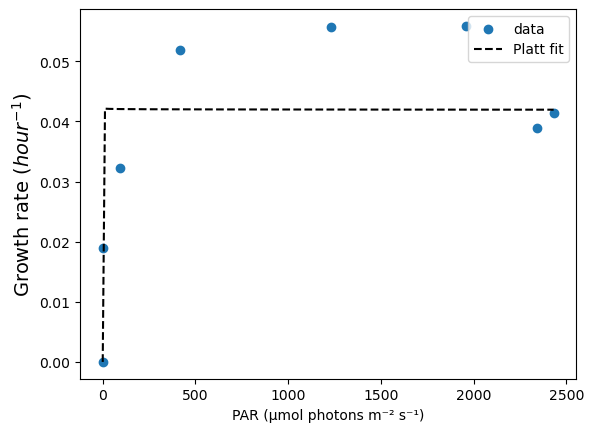

In [ ]:
from scipy.optimize import curve_fit

## loop through each day in each cruise
# just try for one cruise for now
test_df = clean_growth.loc[(clean_growth['cruise'] == 'KM1513') & 
                           (clean_growth['pop'] == 'prochloro') & 
                           (clean_growth['cruise_day'] == 6) & 
                           (clean_growth['day_half'] == 'first')]

# save PI params for each day and cruise
PI_params = {
    'Pmax': [],
    'alpha': [], 
    'beta': [],
    'Ek': []
}

# PE data
E = test_df['par_smooth'].values          # irradiance
P = test_df['slope'].values  # cellular growth 
# Fit — provide reasonable initial guesses

popt, pcov = curve_fit(
    amirian,
    E,
    P,
    p0=[0.05, 5.0, 0.01, 1.0],
    maxfev = 5000
)
Ps_fit, alpha_fit, beta_fit, gamma_fit = popt
# # save fitted params dict
# PI_params.update({'Pmax': Ps_fit,
#                     'alpha': alpha_fit,
#                     'beta': beta_fit,
#                     'Ek': Ps_fit / alpha_fit})
# Plot
E_range = np.linspace(0, E.max(), 200)
plt.scatter(E, P, label='data')
plt.plot(E_range, amirian(E_range, *popt), c = 'k', linestyle = '--', label='Platt fit')
plt.xlabel('PAR (µmol photons m⁻² s⁻¹)')
plt.ylabel('Growth rate ($hour^{-1}$)', fontsize = 14)
plt.legend()

#### trying different optimization functions to fit PI params to Platt curve

Grid search

In [11]:
from itertools import product

### helper function to optimize different Pmax, alpha, and beta parms
def best_platt_fit(E, P, maxfev=5000):
    """Try multiple p0 combinations, return best fit by residual sum of squares."""
    
    # Grid of initial guesses to try
    Ps_guesses    = [P.max(), P.max() * 0.5, P.max() * 1.5]
    # 0.002–0.015
    alpha_guesses = [0.0001, 0.001, 0.01]
    # 0–0.003
    beta_guesses  = [0.0001, 0.001, 0.01]
    # fixed gamma value
    gamma_guesses = np.tile(np.cosh(1) **2, 3)

    best_popt  = None
    best_pcov  = None
    best_rss   = np.inf
    # do a grid search over multiple params
    for p0 in product(Ps_guesses, alpha_guesses, beta_guesses, gamma_guesses):
        try:
            # update the bounds (make sure they are realistic)
            popt, pcov = curve_fit(
                amirian, E, P,
                p0=list(p0),
                bounds=([0, 0, 0], [2, 1, 0.5]),
                maxfev=maxfev
            )
            rss = np.sum((P - amirian(E, *popt))**2)
            if rss < best_rss:
                best_rss, best_popt, best_pcov = rss, popt, pcov
        except (RuntimeError, ValueError):
            continue

    return best_popt, best_pcov, best_rss

In [ ]:
# import numpy as np
# from itertools import product
# from scipy.optimize import curve_fit

# ### second attempt to minimize weird alpha values
# def best_platt_fit(E, P, maxfev=10000, beta_penalty=True):
#     """
#     Improved grid search for Platt PI curve.
#     Fixes degenerate alpha/beta fits by:
#       - log-spaced alpha/beta guesses covering realistic cellular-rate range
#       - tighter, physiologically grounded bounds
#       - AICc-based model selection between inhibition / no-inhibition fits
#       - penalizing beta != 0 unless it meaningfully improves fit
#     """

#     P_peak = np.max(P)
#     E_peak = E[np.argmax(P)]

#     # Ps guesses: bracketing observed max
#     Ps_guesses = [P_peak * f for f in [0.8, 1.0, 1.2, 1.5]]

#     # Alpha: Ek ~ E_peak, so alpha ~ Ps / E_peak
#     # Log-spaced around that estimate
#     alpha_anchor = P_peak / max(E_peak, 10)
#     alpha_guesses = np.geomspace(alpha_anchor * 0.1, alpha_anchor * 5, 6).tolist()

#     # Beta: start near zero, log-spaced up to mild inhibition only
#     beta_guesses = [0.0] + np.geomspace(1e-5, 1e-2, 4).tolist()

#     # Physiological bounds for cellular growth rate (h⁻¹ or d⁻¹ — adjust to your units)
#     # Ps: 0 to 2× observed max (don't let it explode)
#     # alpha: 0 to 0.1 (cellular carbon normalization)
#     # beta: 0 to 0.05
#     bounds_lower = [0,    0,    0    ]
#     bounds_upper = [P_peak * 2, 0.5, 0.05]

#     best_popt = None
#     best_pcov = None
#     best_score = np.inf

#     n = len(P)
#     k = 3  # number of parameters

#     for p0 in product(Ps_guesses, alpha_guesses, beta_guesses):
#         # Skip if p0 is outside bounds
#         if not all(lo <= v <= hi for v, lo, hi in zip(p0, bounds_lower, bounds_upper)):
#             continue
#         try:
#             popt, pcov = curve_fit(
#                 platt, E, P,
#                 p0=list(p0),
#                 bounds=(bounds_lower, bounds_upper),
#                 maxfev=maxfev,
#                 method='trf',       # trust region reflective — better near bounds
#                 ftol=1e-10,
#                 xtol=1e-10,
#             )
#             rss = np.sum((P - platt(E, *popt)) ** 2)

#             # AICc: penalizes extra parameters (discourages spurious beta)
#             sigma2 = rss / n
#             if sigma2 <= 0:
#                 continue
#             aic = n * np.log(sigma2) + 2 * k + (2 * k * (k + 1)) / max(n - k - 1, 1)

#             # Optional: add extra penalty if beta is nonzero but small
#             # This discourages the solver from using beta to create fake bends
#             if beta_penalty and popt[2] > 0:
#                 # penalize unless beta explains >5% RSS reduction vs beta=0 fit
#                 aic += 2.0  # soft prior against photoinhibition

#             if aic < best_score:
#                 best_score = best_rss = rss
#                 best_popt, best_pcov = popt, pcov

#         except (RuntimeError, ValueError):
#             continue

#     return best_popt, best_pcov, best_rss

Global search

In [ ]:
from scipy.optimize import differential_evolution

def best_platt_fit_global(E, P):
    """Global optimization using differential evolution."""
    
    def residuals(params):
        try:
            return np.sum((P - platt(E, *params))**2)
        except:
            return np.inf
    # try wider range of bounds 
    bounds = [
        (0, P.max() * 2),      # Ps
        (1e-6, 1.0),           # alpha
        (0, 0.1),              # beta
    ]
    
    result = differential_evolution(residuals, bounds, seed=42, maxiter=1000)
    
    if result.success:
        return result.x, result.fun   # popt, rss
    return None, np.inf

In [698]:
def is_good_platt_fit(E, P, popt, rss, min_r2=0.3, max_ek_ratio=2.0):
    """
    Decide whether a Platt fit is acceptable.

    Criteria:
      - R^2 above min_r2
      - Ek within max_ek_ratio × max observed E
      - Modeled curve shows curvature / saturation (not purely linear)
    """
    Ps_fit, alpha_fit, beta_fit = popt

    # compute modeled values at data E
    P_hat = platt(E, *popt)

    # R^2
    ss_res = np.sum((P - P_hat)**2)
    ss_tot = np.sum((P - np.nanmean(P))**2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0.0

    # Ek sanity: use Ps/alpha or Pmax/alpha (they should be similar)
    if alpha_fit != 0:
        Ek = Ps_fit / alpha_fit
    else:
        Ek = np.inf

    # reject if Ek is far beyond observed range (no saturation in data)
    if not np.isfinite(Ek) or Ek > max_ek_ratio * np.nanmax(E):
        return False, {'r2': r2, 'Ek': Ek}

    # simple curvature / saturation check:
    #   - if beta ≈ 0 and the modeled curve is nearly linear, reject
    #   - quantify by comparing slope at low vs high E
    E_low  = np.linspace(0, 0.3 * np.nanmax(E), 50)
    E_high = np.linspace(0.7 * np.nanmax(E), np.nanmax(E), 50)

    P_low  = platt(E_low, *popt)
    P_high = platt(E_high, *popt)

    # approximate slopes
    slope_low  = np.gradient(P_low, E_low).mean() if len(E_low)  > 1 else 0.0
    slope_high = np.gradient(P_high, E_high).mean() if len(E_high) > 1 else 0.0

    # if slopes are almost equal, the curve is effectively linear
    if slope_low != 0:
        slope_ratio = slope_high / slope_low
    else:
        slope_ratio = 1.0

    is_linear_like = np.isclose(slope_ratio, 1.0, atol=0.2)

    # final decision
    good = (r2 >= min_r2) and (not is_linear_like)

    return good, {'r2': r2, 'Ek': Ek, 'slope_ratio': slope_ratio}

#### lenient version
def is_good_platt_fit_lenient(E, P, popt, rss, min_r2=0.1, max_ek_ratio=5.0):
    """
    More lenient Platt fit screening.

    Hard reject only if:
      - parameters are non-finite
      - alpha <= 0
      - Ps <= 0
      - fit is extremely poor

    Soft flags:
      - Ek beyond observed light range
      - nearly linear curve
    """
    Ps_fit, alpha_fit, beta_fit = popt

    # hard reject impossible parameter values
    if not np.all(np.isfinite(popt)):
        return False, {'reason': 'nonfinite_params'}
    if Ps_fit <= 0 or alpha_fit <= 0:
        return False, {'reason': 'nonphysical_params'}

    # model prediction
    P_hat = platt(E, *popt)

    # R^2
    ss_res = np.sum((P - P_hat) ** 2)
    ss_tot = np.sum((P - np.nanmean(P)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0.0

    # Ek
    Ek = Ps_fit / alpha_fit if alpha_fit != 0 else np.inf
    ek_out_of_range = (not np.isfinite(Ek)) or (Ek > max_ek_ratio * np.nanmax(E))

    # curvature check
    E_low  = np.linspace(0, 0.3 * np.nanmax(E), 50)
    E_high = np.linspace(0.7 * np.nanmax(E), np.nanmax(E), 50)

    P_low  = platt(E_low, *popt)
    P_high = platt(E_high, *popt)

    slope_low  = np.gradient(P_low, E_low).mean() if len(E_low) > 1 else 0.0
    slope_high = np.gradient(P_high, E_high).mean() if len(E_high) > 1 else 0.0

    if slope_low != 0:
        slope_ratio = slope_high / slope_low
    else:
        slope_ratio = 1.0

    linear_like = np.isclose(slope_ratio, 1.0, atol=0.4)

    # hard reject only very poor fits
    if r2 < min_r2:
        return False, {
            'reason': 'low_r2',
            'r2': r2,
            'Ek': Ek,
            'slope_ratio': slope_ratio,
            'linear_like': linear_like,
            'ek_out_of_range': ek_out_of_range
        }

    # otherwise accept, but keep flags
    return True, {
        'r2': r2,
        'Ek': Ek,
        'slope_ratio': slope_ratio,
        'linear_like': linear_like,
        'ek_out_of_range': ek_out_of_range
    }

In [704]:
from scipy.optimize import curve_fit

# exclude bad cruises
all_growth = pd.concat(growth_dfs)
clean_growth = all_growth.loc[~all_growth['cruise'].isin(bad['cruise'].values)]
clean_growth.loc[clean_growth['slope'] < 0, 'slope'] = 0

# save PI params per day and cruise
PI_params = []

pops = ['prochloro']#, 'synecho', 'picoeuk']
colors = ['tab:blue']#, 'tab:orange', 'tab:green']
sns.set(style='whitegrid')
for pop, color in zip(pops, colors):
    pop_df = clean_growth.loc[clean_growth['pop'] == pop]

    with PdfPages(f'../figures/{pop}_platt_fit_{timeres}_all.pdf') as pdf:
        for season in season_order:
            season_df = pop_df.loc[pop_df['season'] == season]

            for cruise, cruise_df in season_df.groupby('cruise'):
                days = sorted(cruise_df['cruise_day'].unique())
                n_days = len(days)
                if n_days == 0:
                    continue

                # --- FacetGrid layout ---
                ncols = min(4, n_days)
                nrows = int(np.ceil(n_days / ncols))
                fig, axs = plt.subplots(nrows, ncols,
                                        figsize=(ncols * 3.5, nrows * 3),
                                        sharey=False)
                axs = np.array(axs).flatten()
                fig.suptitle(f'{pop} | {cruise} | {season}', fontsize=11)
                # create a facetgrid layout using matplotlib
                for j, day in enumerate(days):
                    ax = axs[j]
                    day_df = cruise_df.loc[cruise_df['cruise_day'] == day]
                    # --- Filter to hours 0–7 only ---
                    day_df = day_df.loc[day_df['day_half'] == 'first']
                    # --- Skip days with fewer than 6 points ---
                    if len(day_df) < 6:
                        ax.set_visible(False)
                        continue
                    E = day_df['par_smooth'].values
                    P = day_df['slope'].values

                    # scatter raw data
                    ax.scatter(E, P, s=15, color=color, alpha=0.7, label='data')
                    ax.set_title(str(day), fontsize=8)
                    ax.set_xlabel('PAR (µmol photons $m^{-2}$ $s^{-1}$)', fontsize=7)
                    ax.set_ylabel('Growth rate ($hour^{-1}$)', fontsize=7)
                    ax.tick_params(labelsize=6)

                    # attempt Platt fit
                    if len(E) < 4:
                        ax.set_title(f'{day}\n(too few points)', fontsize=7, color='grey')
                        continue
                    try:
                        # perform grid search over best potential PI params
                        popt, pcov, rss = best_platt_fit(E, P)

                        # check if fits failed
                        if popt is None:
                            ax.set_title(f'{day}\n(all fits failed)', fontsize=7, color='crimson')
                            continue

                        Ps_fit, alpha_fit, beta_fit = popt

                        # evaluate fit quality BEFORE plotting/saving
                        good, metrics = is_good_platt_fit_lenient(E, P, popt, rss)

                        if not good:
                            # optionally annotate panel so you can see it was rejected
                            ax.set_title(f'{day}\n(bad fit: R²={metrics["r2"]:.2f})',
                                        fontsize=7, color='grey')
                            # you may want to still show raw data but no curve
                            continue

                        # if we reach here, fit is considered good → plot & save

                        E_range = np.linspace(0, E.max(), 200)
                        P_model = platt(E_range, *popt)
                        Pmax_fit = P_model.max()

                        ax.plot(E_range, P_model,
                                color='k', linestyle='--', lw=1, label='Platt fit')

                        Ek = Pmax_fit / alpha_fit if alpha_fit != 0 else np.nan

                        PI_params.append({
                            'pop':    pop,
                            'cruise': cruise,
                            'season': season,
                            'date':   day,
                            'Pmax':   Pmax_fit,
                            'alpha':  alpha_fit,
                            'beta':   beta_fit,
                            'Ek':     Ek,
                            'mld':    np.mean(day_df['mld']),
                            'r2':     metrics['r2'],
                        })

                    except (RuntimeError, ValueError) as e:
                        ax.set_title(f'{day}\n(fit failed)', fontsize=7, color='crimson')
                    # try:
                    #     # perform grid search over best potential PI params
                    #     popt, pcov, rss = best_platt_fit(E, P)
                    #     # check if fits failed
                    #     if popt is None:
                    #         ax.set_title(f'{day}\n(all fits failed)', fontsize=7, color='crimson')
                    #         continue
                    #     # get fits
                    #     Ps_fit, alpha_fit, beta_fit = popt
                    #     # get range of values for plotting 
                    #     E_range = np.linspace(0, E.max(), 200)
                    #     P_model = platt(E_range, *popt)
                    #     # modeled maximum production over observed range
                    #     Pmax_fit = P_model.max()
                    #     ax.plot(E_range, platt(E_range, *popt),
                    #             color='k', linestyle='--', lw=1, label='Platt fit')

                    #     Ek = Pmax_fit / alpha_fit if alpha_fit != 0 else np.nan

                    #     PI_params.append({
                    #         'pop':    pop,
                    #         'cruise': cruise,
                    #         'season': season,
                    #         'date':   day,
                    #         'Pmax':   Ps_fit,
                    #         'alpha':  alpha_fit,
                    #         'beta':   beta_fit,
                    #         'Ek':     Ek,
                    #         'mld':    np.mean(day_df['mld'])
                    #     })

                    # except (RuntimeError, ValueError) as e:
                    #     ax.set_title(f'{day}\n(fit failed)', fontsize=7, color='crimson') 
                # hide unused subplots
                for k in range(j + 1, len(axs)):
                    axs[k].set_visible(False)
                visible_axs = [ax for ax in axs if ax.get_visible()]
                if visible_axs:
                    all_ylims = [ax.get_ylim() for ax in visible_axs]
                    y_min = min(yl[0] for yl in all_ylims)
                    y_max = max(yl[1] for yl in all_ylims)
                    for ax in visible_axs:
                        ax.set_ylim(y_min, y_max)
                        # Only show ytick labels on leftmost visible ax per row
                        col_idx = list(axs).index(ax) % ncols
                        if col_idx != 0:
                            ax.tick_params(labelleft=False)
                plt.tight_layout()
                pdf.savefig(fig, bbox_inches='tight')
                plt.close(fig)

# collect params into a DataFrame
PI_params_df_all = pd.DataFrame(PI_params)

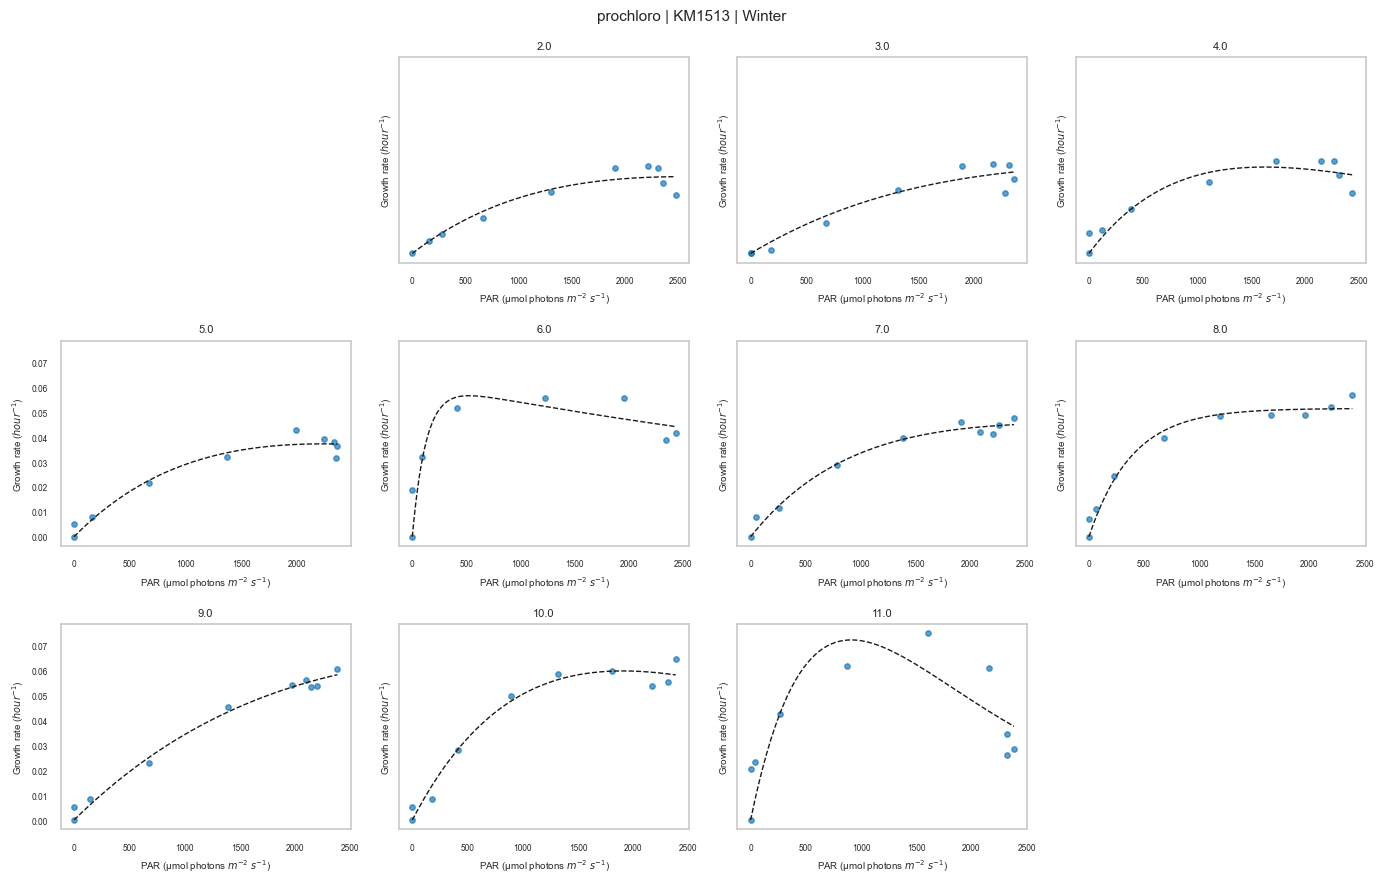

In [891]:
### just station aloha cruise

# save PI params per day and cruise
PI_params = []

pops = ['prochloro']
color = 'tab:blue'
sns.set_theme(style='whitegrid')
cruise = 'KM1513'
cruise_df = clean_growth.loc[clean_growth['cruise'] == cruise]
sns.set_theme(style = 'whitegrid')

for pop in pops:
    pop_df = cruise_df.loc[cruise_df['pop'] == pop]
    days = sorted(pop_df['cruise_day'].unique())
    n_days = len(days)

    # --- FacetGrid layout ---
    ncols = min(4, n_days)
    nrows = int(np.ceil(n_days / ncols))
    fig, axs = plt.subplots(nrows, ncols,
                            figsize=(ncols * 3.5, nrows * 3),
                            sharey=False)
    axs = np.array(axs).flatten()
    fig.suptitle(f'{pop} | {cruise} | {season}', fontsize=11)
    # create a facetgrid layout using matplotlib
    for j, day in enumerate(days):
        ax = axs[j]
        day_df = pop_df.loc[pop_df['cruise_day'] == day]
        # --- Filter to hours 0–7 only ---
        day_df = day_df.loc[day_df['day_half'] == 'first']
        # --- Skip days with fewer than 6 points ---
        if len(day_df) < 6:
            ax.set_visible(False)
            continue
        E = day_df['par_smooth'].values
        P = day_df['slope'].values

        # scatter raw data
        ax.scatter(E, P, s=15, color=color, alpha=0.7, label='data')
        ax.set_title(str(day), fontsize=8)
        ax.set_xlabel('PAR (µmol photons $m^{-2}$ $s^{-1}$)', fontsize=7)
        ax.set_ylabel('Growth rate ($hour^{-1}$)', fontsize=7)
        ax.tick_params(labelsize=6)

        # attempt Platt fit
        if len(E) < 4:
            ax.set_title(f'{day}\n(too few points)', fontsize=7, color='grey')
            continue
        try:
            # perform grid search over best potential PI params
            popt, pcov, rss = best_platt_fit(E, P)
            # check if fits failed
            if popt is None:
                ax.set_title(f'{day}\n(all fits failed)', fontsize=7, color='crimson')
                continue
            # get fits
            Ps_fit, alpha_fit, beta_fit = popt
            # get range of values for plotting 
            E_range = np.linspace(0, E.max(), 200)
            P_model = platt(E_range, *popt)
            # modeled maximum production over observed range
            Pmax_fit = P_model.max()
            ax.plot(E_range, platt(E_range, *popt),
                    color='k', linestyle='--', lw=1, label='Platt fit')
            ax.grid(False)

            Ek = Pmax_fit / alpha_fit if alpha_fit != 0 else np.nan
            # ax.set_title(f'{day}\nEk={Ek:.1f}', fontsize=7)

            PI_params.append({
                'pop':    pop,
                'cruise': cruise,
                'season': season,
                'date':   day,
                'Pmax':   Pmax_fit,
                'alpha':  alpha_fit,
                'beta':   beta_fit,
                'Ek':     Ek,
                'mld':    np.mean(day_df['mld'])
            })

        except (RuntimeError, ValueError) as e:
            ax.set_title(f'{day}\n(fit failed)', fontsize=7, color='crimson') 
    # hide unused subplots
    for k in range(j + 1, len(axs)):
        axs[k].set_visible(False)
    visible_axs = [ax for ax in axs if ax.get_visible()]
    if visible_axs:
        all_ylims = [ax.get_ylim() for ax in visible_axs]
        y_min = min(yl[0] for yl in all_ylims)
        y_max = max(yl[1] for yl in all_ylims)
        for ax in visible_axs:
            ax.set_ylim(y_min, y_max)
            # Only show ytick labels on leftmost visible ax per row
            col_idx = list(axs).index(ax) % ncols
            if col_idx != 0:
                ax.tick_params(labelleft=False)
    plt.tight_layout()

    # collect params into a DataFrame
    aloha_PI_params = pd.DataFrame(PI_params)

In [892]:
aloha_PI_params

,pop,cruise,season,date,Pmax,alpha,beta,Ek,mld
0,prochloro,KM1513,Winter,2.0,0.030835,0.000033,7.714500e-04,933.569538,31.666667
1,prochloro,KM1513,Winter,3.0,0.032708,0.000027,5.540548e-04,1207.726876,27.666667
2,prochloro,KM1513,Winter,4.0,0.034707,0.000058,1.202742e-03,597.361815,28.833333
3,prochloro,KM1513,Winter,5.0,0.037323,0.000046,8.752684e-04,819.377609,29.500000
4,prochloro,KM1513,Winter,6.0,0.056670,0.000477,8.622033e-06,118.773764,27.761905
5,prochloro,KM1513,Winter,7.0,0.045027,0.000056,3.384018e-06,809.021773,34.555556
6,prochloro,KM1513,Winter,8.0,0.051470,0.000133,4.424661e-22,387.883326,36.777778
7,prochloro,KM1513,Winter,9.0,0.058411,0.000044,4.654698e-04,1333.041207,38.041667
8,prochloro,KM1513,Winter,10.0,0.059923,0.000085,1.006870e-03,701.183476,41.714286
9,prochloro,KM1513,Winter,11.0,0.072381,0.000216,2.087169e-03,335.317725,NaN


In [477]:
good_aloha_PI = aloha_PI_params.loc[~((aloha_PI_params['pop'] == 'synecho') & 
                    (aloha_PI_params['date'] <= 7))]

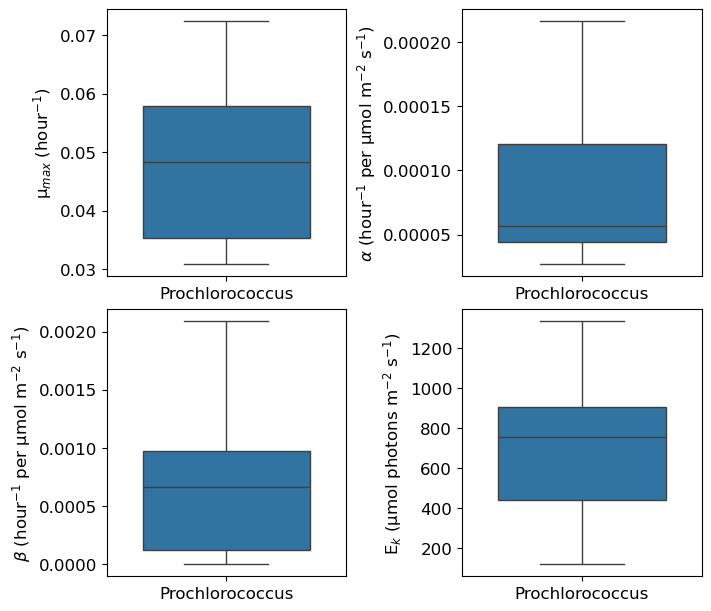

In [659]:
# Base dataframe
df = good_aloha_PI.copy()   # or PI_params_df_all

params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax':  'µ$_{max}$ (hour$^{-1}$)',
    'alpha': r'$\alpha$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'beta':  r'$\beta$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
}

# Clean and melt
df_clean = (
    df[['pop'] + params]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(how='all', subset=params)
)

df_long = df_clean.melt(
    id_vars='pop',
    value_vars=params,
    var_name='param',
    value_name='value'
).dropna(subset=['value'])

# sns.set(style='whitegrid')

pops = ['prochloro',]
palette = {
    'prochloro': 'tab:blue',
}
fig, axs = plt.subplots(2, 2, figsize=(7, 6), constrained_layout=True)
axs = axs.flatten()

for ax, param in zip(axs, params):
    sub = df_long[df_long['param'] == param]
    if sub.empty:
        ax.set_visible(False)
        continue

    sns.boxplot(
        data=sub,
        x='pop',
        y='value',
        hue='pop',
        order=pops,
        hue_order=pops,
        palette=palette,
        dodge=False,
        width=0.7,
        showfliers = False,
        ax=ax,
        legend=False,   # suppress per-axes legends
    )
    ax.set_xlabel('')
    ax.set_ylabel(param_labels[param], fontsize=12)
    ax.tick_params(labelsize=12)
    ax.set_xticklabels(['Prochlorococcus'])

# plt.tight_layout()
plt.show()

Text(0.5, 0, 'Mixed Layer Depth (m)')

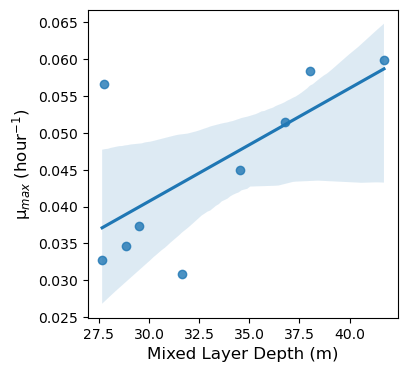

In [651]:
pro_df = df.loc[df['pop'] == 'prochloro']
fig, axs = plt.subplots(figsize=(4, 4))
g = sns.regplot(pro_df, x = 'mld', y = 'Pmax', ax = axs)
axs.set_ylabel('µ$_{max}$ (hour$^{-1}$)', fontsize = 12)
axs.set_xlabel('Mixed Layer Depth (m)', fontsize = 12)

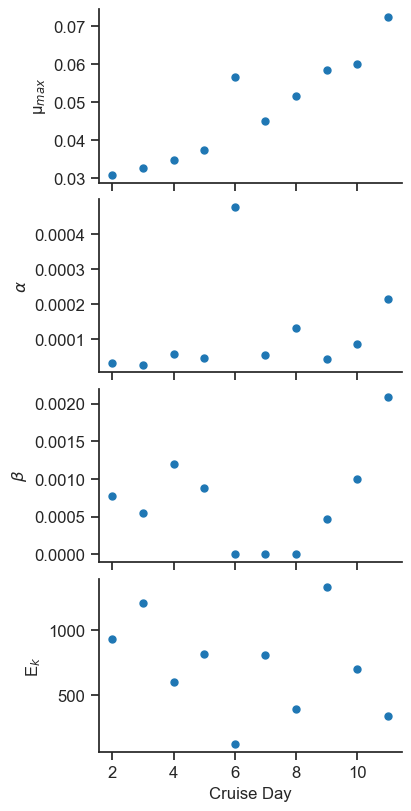

In [805]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# If date is numeric cruise_day; convert to something sortable if needed
# If you have actual datetime, ensure it's datetime64:
# aloha_PI_params['date'] = pd.to_datetime(aloha_PI_params['date'])

params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax':  'µ$_{max}$',
    'alpha': r'$\alpha$',
    'beta':  r'$\beta$',
    'Ek':    'E$_k$',
}

pops = ['prochloro']#, 'synecho', 'picoeuk']
colors = ['tab:blue']#, 'tab:orange', 'tab:green']
pop_palette = dict(zip(pops, colors))

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

# show integrated PAR Westerlies vs. Trades
df = good_aloha_PI.copy()
max_intpar = clean_growth.groupby(['cruise', 'cruise_day'])['int_par'].max().reset_index()
biomes_par = df.merge(max_intpar)


# sort by date to get nice lines
df = df.sort_values('date')

fig, axs = plt.subplots(
    nrows=len(params),
    ncols=1,
    figsize=(4, 8),
    sharex=True,
    constrained_layout=True
)

if len(params) == 1:
    axs = [axs]

for ax, param in zip(axs, params):
    # drop infinities/nans
    df_param = df[['date', 'pop', param]].replace([np.inf, -np.inf], np.nan).dropna()
    if df_param.empty:
        ax.set_visible(False)
        continue

    for pop in pops:
        sub = df_param[df_param['pop'] == pop]
        if sub.empty:
            continue

        ax.plot(
            sub['date'],
            sub[param],
            marker='o',
            linewidth=1,
            linestyle ='',
            markersize=5,
            color=pop_palette[pop],
            label=pop
        )

    ax.set_ylabel(param_labels[param], fontsize=12)
    ax.tick_params(labelsize=12)

# x-axis label on bottom panel only
axs[-1].set_xlabel('Cruise Day', fontsize=12)


plt.show()

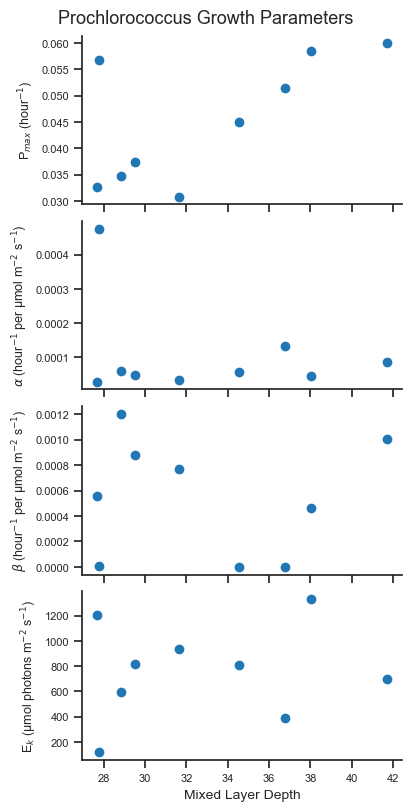

In [506]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# If date is numeric cruise_day; convert to something sortable if needed
# If you have actual datetime, ensure it's datetime64:
# aloha_PI_params['date'] = pd.to_datetime(aloha_PI_params['date'])

params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax':  'P$_{max}$ (hour$^{-1}$)',
    'alpha': r'$\alpha$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'beta':  r'$\beta$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
}

pops = ['prochloro']
colors = ['tab:blue']
pop_palette = dict(zip(pops, colors))

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

df = good_aloha_PI.loc[good_aloha_PI['pop'] == 'prochloro']

# sort by date to get nice lines
df = df.sort_values('date')

fig, axs = plt.subplots(
    nrows=len(params),
    ncols=1,
    figsize=(4, 8),
    sharex=True,
    constrained_layout=True
)

if len(params) == 1:
    axs = [axs]

fig.suptitle('Prochlorococcus Growth Parameters', fontsize=13)

for ax, param in zip(axs, params):
    # drop infinities/nans
    df_param = df[['mld', 'pop', param]].replace([np.inf, -np.inf], np.nan).dropna()
    if df_param.empty:
        ax.set_visible(False)
        continue

    for pop in pops:
        sub = df_param[df_param['pop'] == pop]
        if sub.empty:
            continue

        ax.plot(
            sub['mld'],
            sub[param],
            marker='o',
            linestyle='',
            markersize=6,
            color=pop_palette[pop],
            label=pop
        )

    ax.set_ylabel(param_labels[param], fontsize=9)
    ax.tick_params(labelsize=8)

# x-axis label on bottom panel only
axs[-1].set_xlabel('Mixed Layer Depth', fontsize=10)


plt.show()

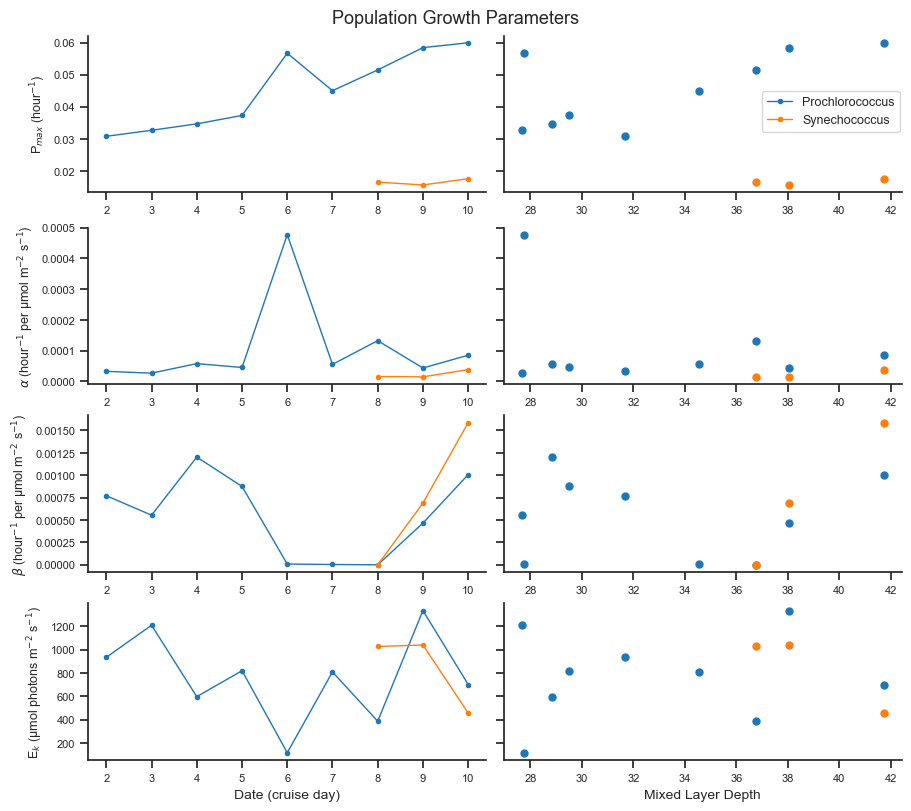

In [519]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax':  'P$_{max}$ (hour$^{-1}$)',
    'alpha': r'$\alpha$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'beta':  r'$\beta$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
}

pops = ['prochloro', 'synecho', 'picoeuk']
colors = ['tab:blue', 'tab:orange', 'tab:green']
pop_palette = dict(zip(pops, colors))

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

df = good_aloha_PI.copy()

# sort for cleaner lines in time series
df = df.sort_values('date')

fig, axs = plt.subplots(
    nrows=len(params),
    ncols=2,
    figsize=(9, 8),
    sharey='row',   # share y-axis within each row
    constrained_layout=True
)

fig.suptitle('Population Growth Parameters', fontsize=13)

for i, param in enumerate(params):
    ax_time = axs[i, 0]
    ax_mld  = axs[i, 1]

    # clean subset for this parameter
    df_param = df[['date', 'mld', 'pop', param]].replace([np.inf, -np.inf], np.nan).dropna()

    if df_param.empty:
        ax_time.set_visible(False)
        ax_mld.set_visible(False)
        continue

    # --- left column: time series ---
    for pop in pops:
        sub = df_param[df_param['pop'] == pop].sort_values('date')
        if sub.empty:
            continue

        ax_time.plot(
            sub['date'],
            sub[param],
            marker='o',
            linestyle='-',
            linewidth=1,
            markersize=3,
            color=pop_palette[pop],
            label=pop
        )

    ax_time.set_ylabel(param_labels[param], fontsize=9)
    ax_time.tick_params(labelsize=8)

    # --- right column: vs mixed layer depth ---
    for pop in pops:
        sub = df_param[df_param['pop'] == pop]
        if sub.empty:
            continue

        ax_mld.plot(
            sub['mld'],
            sub[param],
            marker='o',
            linestyle='',
            markersize=5,
            color=pop_palette[pop],
            label=pop
        )

    ax_mld.tick_params(labelsize=8)

# column labels on bottom row only
axs[-1, 0].set_xlabel('Date (cruise day)', fontsize=10)
axs[-1, 1].set_xlabel('Mixed Layer Depth', fontsize=10)

# optional small titles for top row
# axs[0, 0].set_title('Time series', fontsize=11)
# axs[0, 1].set_title('Mixed layer depth', fontsize=11)

# only keep y tick labels on left column if you want cleaner look
for i in range(len(params)):
    axs[i, 1].tick_params(labelleft=False)

# one shared legend
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    ['Prochlorococcus', 'Synechococcus'],
    loc='upper right',
    bbox_to_anchor=(1, 0.9),
    fontsize=9,
    framealpha=0.8
)

plt.show()

### Plot distributions of PI params

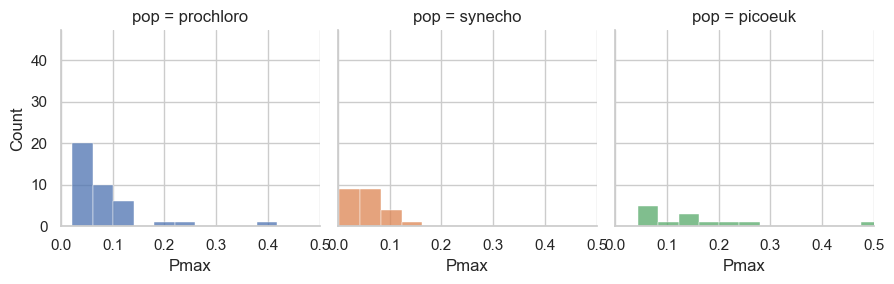

In [288]:
## Pmax only
g = sns.FacetGrid(PI_params_df, col = 'pop', hue = 'pop')
g.map(sns.histplot, 'Pmax', bins = 50)
g.set(xlim=(0, 0.5))

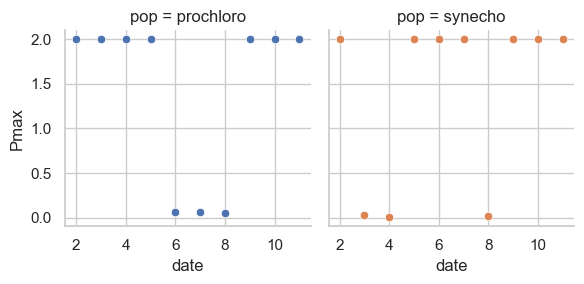

In [294]:
## Pmax only
diel_pi = PI_params_df.loc[PI_params_df['cruise'] == 'KM1513']
g = sns.FacetGrid(diel_pi, col = 'pop', hue = 'pop')
g.map(sns.scatterplot, 'date',  'Pmax')
# g.set(xlim=(0, 0.5))

### Bring in Longhurst information

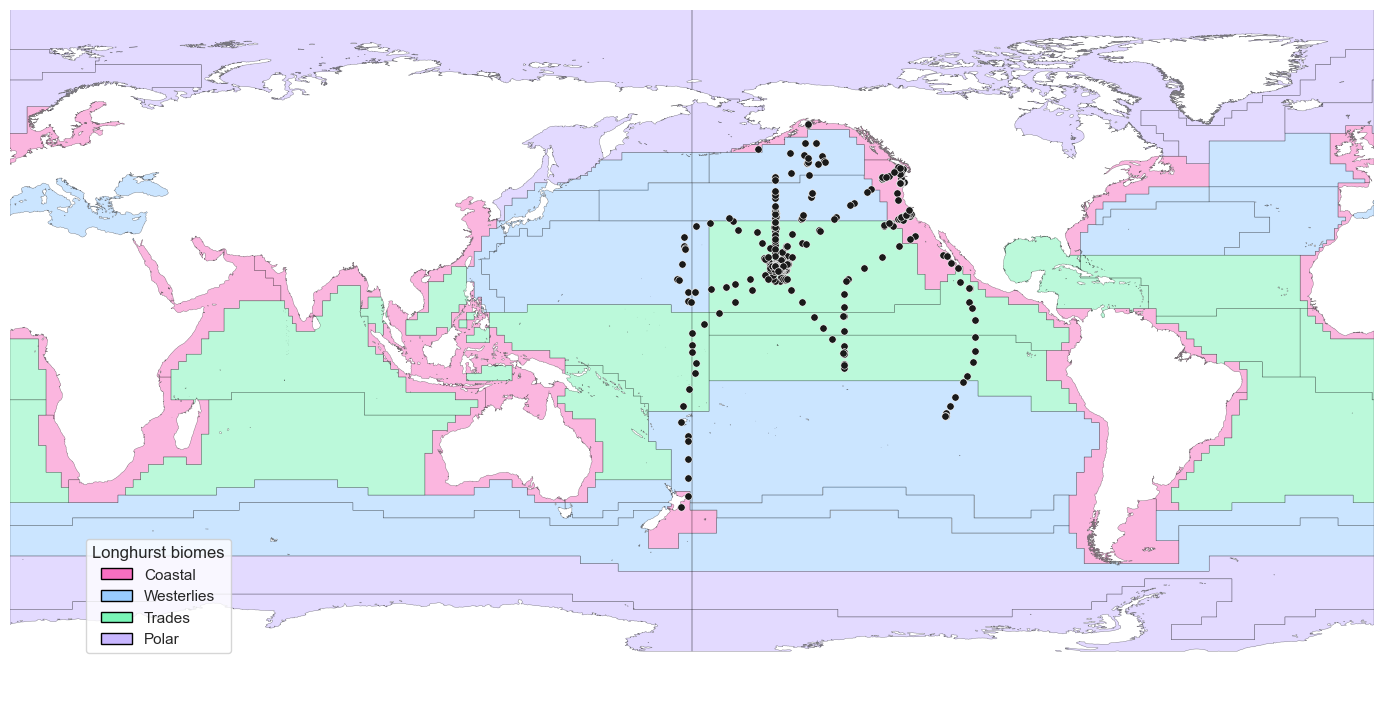

In [919]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from shapely.geometry import Point
from matplotlib.patches import Patch
import cartopy.crs as ccrs


# Keep longitudes in 0–360 if that is how your cruise data are stored.
# If your input is already in -180..180, convert to 0..360 for consistency


hot_cruise_clean['lon_180'] = np.where(
    hot_cruise_clean['lon'] < 0,
    hot_cruise_clean['lon'] + 360,
    hot_cruise_clean['lon']
)

lh_shapefile = '../../../seaflow/seaflow_tsd_project/data/shapefiles/Longhurst_world_v4_2010/Longhurst_world_v4_2010.shp'
gfinal_rates = gpd.read_file(lh_shapefile)
gfinal_rates['biome'] = gfinal_rates['ProvDescr'].str.split().str[0]


# GeoDataFrame for spatial join
hot_cruise_clean['geometry'] = gpd.points_from_xy(
    hot_cruise_clean['lon_180'],
    hot_cruise_clean['lat']
)
final_rates_geo = gpd.GeoDataFrame(
    hot_cruise_clean,
    geometry='geometry',
    crs=gfinal_rates.crs
)

# Spatial join
final_rates_geo = gpd.sjoin(
    final_rates_geo,
    gfinal_rates[['geometry', 'ProvCode', 'biome']],
    how='left',
    predicate='within'
)

final_rates_geo.rename(columns={'ProvCode': 'region'}, inplace=True)
final_rates_geo.loc[final_rates_geo['region'].isna(), 'region'] = 'CCAL'
final_rates_geo.drop(columns=['geometry', 'index_right'], inplace=True)


# Palette
biome_colors = {
    'Coastal': "#F86FC1",
    'Westerlies': "#99CCFF",
    'Trades': "#79F5B7",
    'Polar': "#C8B6FF"
}

plot_gdf = gfinal_rates[gfinal_rates['biome'].isin(biome_colors)].copy()


# --- one scatter point per day with data in bio_PI_all['slope'] ---
# Assumes bio_PI_all has either a DatetimeIndex or a datetime column called 'time'

bio_tmp = hot_cruise_clean.copy()

if isinstance(bio_tmp.index, pd.DatetimeIndex):
    bio_tmp = bio_tmp.reset_index().rename(columns={'index': 'time'})
elif 'time' not in bio_tmp.columns:
    raise ValueError("bio_PI_all must have a DatetimeIndex or a 'time' column.")

bio_tmp['time'] = pd.to_datetime(bio_tmp['time'])
bio_tmp = bio_tmp.loc[bio_tmp['diel'].notna()].copy()
bio_tmp['day'] = bio_tmp['time'].dt.floor('D')

# one point per day; choose first available lat/lon for that day
daily_pts = (
    bio_tmp.groupby('day')
    .first()
    .reset_index()
)

if 'lon_180' not in daily_pts.columns:
    daily_pts['lon_180'] = np.where(daily_pts['lon'] < 0, daily_pts['lon'] + 360, daily_pts['lon'])


# --- Plot with Pacific-centered projection ---
proj = ccrs.PlateCarree(central_longitude=180)
data_crs = ccrs.PlateCarree()

fig, ax = plt.subplots(figsize=(14, 8), subplot_kw={'projection': proj})
# ax = plt.axes(figsize = (14, 8), projection=ccrs.PlateCarree(central_longitude=180))
# ax.set_extent([110, 350, -50, 70], crs=ccrs.PlateCarree())
for biome, color in biome_colors.items():
    subset = plot_gdf[plot_gdf['biome'] == biome]
    if not subset.empty:
        subset.plot(
            ax=ax,
            transform=data_crs,
            color=color,
            alpha=0.5,
            edgecolor='black',
            linewidth=0.3
        )

# Scatter one point per day with slope data
ax.scatter(
    daily_pts['lon_180'],
    daily_pts['lat'],
    transform=data_crs,
    s=28,
    color='k',
    edgecolor='white',
    linewidth=0.4,
    zorder=5
)

handles = [
    Patch(facecolor=color, edgecolor='black', label=biome)
    for biome, color in biome_colors.items()
]

ax.legend(
    handles=handles,
    title='Longhurst biomes',
    loc='lower left',
    bbox_to_anchor=(0.05, 0.05),
    frameon=True
)
ax.set_extent([110, 350, -50, 70], crs=ccrs.PlateCarree())
ax.set_global()
ax.set_axis_off()
plt.tight_layout()
plt.show()

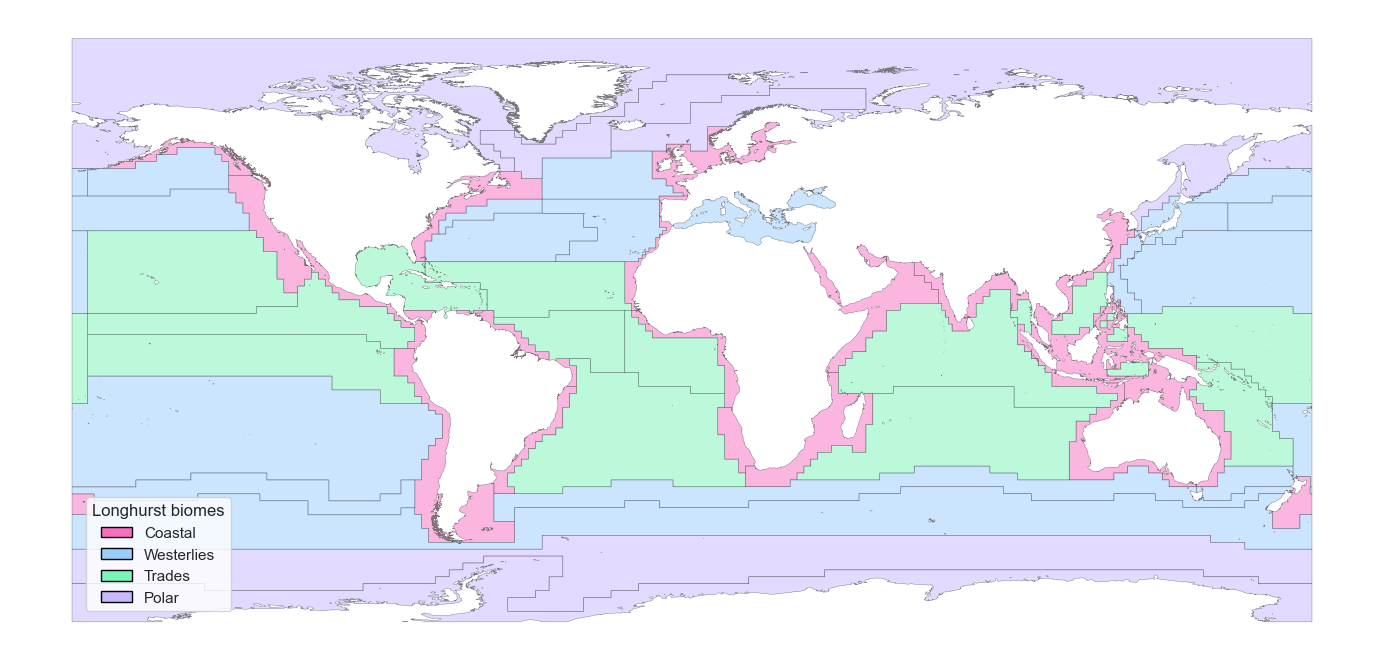

In [ ]:
import geopandas as gpd
from shapely.geometry import Point, MultiPolygon
from shapely.geometry import shape
from matplotlib.patches import Patch

hot_cruise_clean['lon'] = np.where(hot_cruise_clean['lon']>180, hot_cruise_clean['lon']-360, hot_cruise_clean['lon'])

lh_shapefile = '../../../seaflow/seaflow_tsd_project/data/shapefiles/Longhurst_world_v4_2010/Longhurst_world_v4_2010.shp'
gfinal_rates = gpd.read_file(lh_shapefile)
gfinal_rates['biome'] = gfinal_rates['ProvDescr'].str.split().str[0]

# Convert dataframe to a GeoDataFrame
hot_cruise_clean['geometry'] = hot_cruise_clean.apply(lambda row: Point(row['lon'], row['lat']), axis=1)
final_rates_geo = gpd.GeoDataFrame(hot_cruise_clean, geometry='geometry', crs=gfinal_rates.crs)

# Perform spatial join to get region information
final_rates_geo = gpd.sjoin(final_rates_geo, gfinal_rates[['geometry', 'ProvCode', 'biome']], how='left', predicate='within')

final_rates_geo.rename(columns={'ProvCode': 'region'}, inplace=True)
# columns with nan are in the sound (ccal)
final_rates_geo.loc[final_rates_geo['region'].isna(), 'region'] = 'CCAL'

# Save the updated dataframe
final_rates_geo.drop(columns=['geometry', 'index_right'], inplace=True)
# Palette
biome_colors = {
    'Coastal': "#F86FC1",
    'Westerlies': "#99CCFF",
    'Trades': "#79F5B7",
    'Polar': "#C8B6FF"
}

# Keep only biomes included in the palette
plot_gdf = gfinal_rates[gfinal_rates['biome'].isin(biome_colors)].copy()

# Plot
fig, ax = plt.subplots(figsize=(14, 8))

for biome, color in biome_colors.items():
    subset = plot_gdf[plot_gdf['biome'] == biome]
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=color,
            alpha = 0.5,
            edgecolor='black',
            linewidth=0.3
        )

# Legend
handles = [
    Patch(facecolor=color, edgecolor='black', label=biome)
    for biome, color in biome_colors.items()
]

ax.legend(
    handles=handles,
    title='Longhurst biomes',
    loc='lower left',
    bbox_to_anchor = (0.05, 0.05),
    frameon=True
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

In [ ]:
# save regions
regions = pd.unique(final_rates_geo['region'])

# helper function to draw pie chart on map
def plot_pie_direct(dataframe_pie,ilat_pie,ilon_pie,pop_colors,axis_main,
                    width_local,alpha_local,make_legend=False):
    # make wedges and text
    wedges,texts= ax_main.pie(dataframe_pie,colors=pop_colors,radius=width_local)
    # check if make legend
    if make_legend:
        labels=['Small Eukaryotes', 'Prochlorococcus', 'Synechococcus']
        l1 = plt.legend(wedges, labels, loc="best", title='Populations')
        ax_main.add_artist(l1)
    # adjust each wedge
    for w in wedges:
        w.set_linewidth(0.02)  ## Reduce linewidth to near-zero
        w.transform=ccrs.PlateCarree(central_longitude=180)
        # offset by 180
        w.set_center((ilon_pie-180,ilat_pie))
        w.set_zorder(0)
        w.set_alpha(alpha_local)

# make color map by population
cmap={'prochloro':'#1f77b4', 'synecho':'#ff7f0e', 'picoeuk':'#2ca02c', 
             'failed':'tab:gray'}
fig= plt.figure(figsize=(12,20))
# Define both CRS objects explicitly
data_crs = ccrs.PlateCarree()  # standard geographic CRS (central_longitude=0)
map_proj = ccrs.PlateCarree(central_longitude=180)

# After creating the axes and setting extent:
ax_main = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
ax_main.set_extent([110, 350, -50, 70], crs=ccrs.PlateCarree())
# Turn off autoscaling so pie wedges don't expand the view
ax_main.set_autoscale_on(False)

# remove gridlines
gl=ax_main.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.xlines=None
gl.ylines=None

ax_main.coastlines(zorder=3)
# Plot selected Longhurst provinces
gdf = gfinal_rates.loc[gfinal_rates['ProvCode'].isin(regions)]
prov = gdf.plot(ax=ax_main, column='ProvCode', cmap='tab20c', alpha=0.25, legend=True, 
         transform =ccrs.PlateCarree())
# add region name to each province
# Add province labels at the centroid of each polygon
for idx, row in gdf.iterrows():
    # check if multipolygon first
    if isinstance(row.geometry, MultiPolygon):
        # Better for MultiPolygon
        centroid = row.geometry.representative_point()
    else:
        centroid = row.geometry.centroid
    # manually shift if ALSK to prevent label from being obscured
    if row['ProvCode']=='ALSK':
        ax_main.text(centroid.x+15, centroid.y+2, row['ProvCode'], fontsize=10, ha='center', 
                 transform=ccrs.PlateCarree())
    else:
        ax_main.text(centroid.x, centroid.y, row['ProvCode'], fontsize=10, ha='center', 
                 transform=ccrs.PlateCarree())

## remove days with any failed pops (productivity map) and adjust for too large vals
combined_rates.loc[combined_rates['productivity']>20,'productivity']=np.nan
### for productivity map
combined_group=combined_rates[['cruise','cruise_day','pop',
                               'round_lat', 'round_lon', 'productivity']].groupby(['cruise','cruise_day','pop']).mean()

# get rid of rows with a cruise day that has failed population type
sub_dfs=[]
for cruise, new_df in combined_group.groupby(level=[0,1]):
    # check if failed population is present in a cruise day OR if productivity is nan
    if ('failed' not in (list(pd.unique(new_df.reset_index()['pop']))))&(~new_df['productivity'].isna().any()):
        # if not present AND no nulls, append
        sub_dfs.append(new_df)
# save final df
final_groups=pd.concat(sub_dfs).reset_index()
# group by lat/lon
combined_final=final_groups.groupby(['round_lat','round_lon','pop']).agg(({
    'productivity':'mean'
}))
# calculate percent
combined_final['percent']=combined_final.groupby(level=[0,1]).apply(
     lambda x: x/ x.sum())['productivity'].values
# calculate scaling
obs_list=combined_final.groupby(level=[0,1]).sum()['productivity'].values
# rescale from 1.5-6
interval_min = 2
interval_max = 5
# scale observations from custom list
scaled_obs=((((obs_list-np.min(obs_list))/(np.max(obs_list)-np.min(obs_list)))*
 (interval_max-interval_min))+interval_min)


# loop thru each df and plot
counter=0
legend=False
for i, df in combined_final.groupby(level=[0,1]):
    # get data needed to make piechart
    lat, lon=i
    percents=df.percent.values
    # get colors
    pops=df.index.get_level_values(2).values
    colors=[cmap[key] for key in pops]
    # get scaled number for width
    obs=scaled_obs[counter]
    # make legend once
    if (len(pops)==3)&(legend==False):
        plot_pie_direct(percents, lat, lon, colors,ax_main, obs, 0.9, make_legend=True)
        legend=True
    # make piechart
    else:
        plot_pie_direct(percents, lat, lon, colors,ax_main, obs, 0.9)
    counter+=1


# PP values to include in legend
pp_values = [1, 4, 12]
# Scale PP values using the SAME scaling as your pie chart radii
obs_min = np.min(obs_list)
obs_max = np.max(obs_list)
interval_min = 2
interval_max = 5
# scale custom radii
scaled_legend = [((( (pp - obs_min) / (obs_max - obs_min)) *
                   (interval_max - interval_min)) + interval_min) for pp in pp_values]
# Normalize to a reasonable legend icon size (scale down for the handlebox)
max_scaled = max(scaled_legend)
legend_circles = []
for pp, sc in zip(pp_values, scaled_legend):
    # Scale radius relative to handlebox (~5-12 pts)
    r = (sc / max_scaled) * 10
    c = Circle((0, 0), radius=r, facecolor='k', edgecolor='black',
               linewidth=0.5, alpha=0.6)
    legend_circles.append(c)
# create legend labels
legend_labels = [str(pp) for pp in pp_values]
# Create the size legend
leg2 = ax_main.legend(
    legend_circles, legend_labels,
    handler_map={Circle: HandlerCircle()},
    title='PP (µg C L$^{-1}$ d$^{-1})$',
    loc='upper right',
    bbox_to_anchor=(0.81, 1.0),   # adjust to place LEFT of the population legend
    frameon=True,
    labelspacing=1,             # vertical spacing between entries
    handletextpad=0.75,
    borderpad=0.75,               # more padding between entries and legend border edge
    borderaxespad=0.5
)
# Add it back so it doesn't replace the first (population) legend
ax_main.add_artist(leg2)

# add features
ax_main.coastlines(zorder=3)
ax_main.add_feature(cfeature.COASTLINE)
ax_main.add_feature(cfeature.LAND)
ax_main.add_feature(cfeature.BORDERS)
# set map extent 
ax_main.set_extent([110, 350, -50, 70], crs=ccrs.PlateCarree())

plt.show()

In [705]:
biogeo_df = final_rates_geo[['cruise', 'cruise_day', 'biome', 'region']].reset_index(drop=True)
biogeo_df = biogeo_df.drop_duplicates().reset_index(drop = True,)
bio_PI_all = PI_params_df_all.rename(columns = {'date': 'cruise_day'}).merge(biogeo_df)

<Axes: xlabel='int_par', ylabel='Count'>

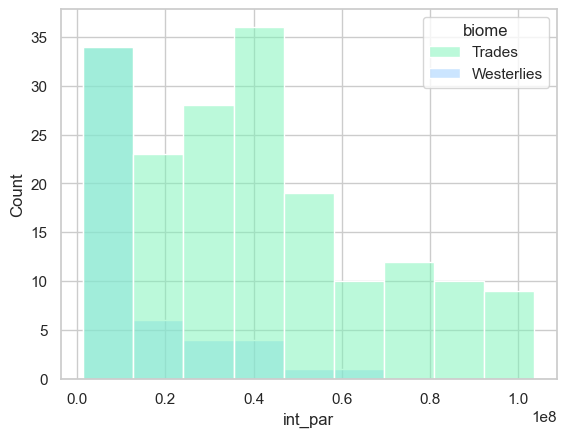

In [763]:
# show integrated PAR Westerlies vs. Trades
max_intpar = clean_growth.groupby(['cruise', 'cruise_day'])['int_par'].max().reset_index()
biomes_par = max_intpar.merge(biogeo_df.loc[biogeo_df['biome'] != 'Coastal'])
# plot histogram of integrated par
fig, axs = plt.subplots()
sns.histplot(biomes_par, x = 'int_par', hue = 'biome', palette = palette)

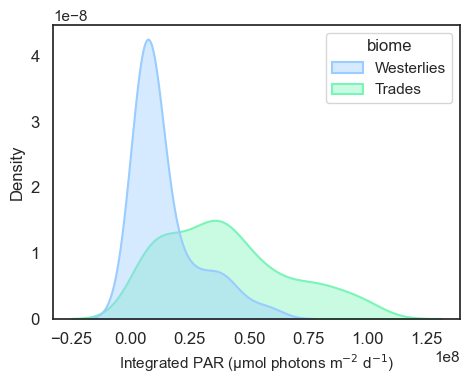

In [775]:
sns.set_theme(style='white')

fig, ax = plt.subplots(figsize=(5, 4))

sns.kdeplot(
    data=biomes_par,
    x='int_par',
    hue='biome',
    common_norm=False,     # keep each biome’s density normalized separately
    fill=True,
    alpha=0.4,
    linewidth=1.5,
    palette=palette,
    ax=ax
)

ax.set_xlabel('Integrated PAR (µmol photons m$^{-2}$ d$^{-1}$)', fontsize=11)
ax.set_ylabel('Density', fontsize=12)
ax.tick_params(labelsize=12)
# ax.legend(title='Biome')

plt.tight_layout()
plt.show()

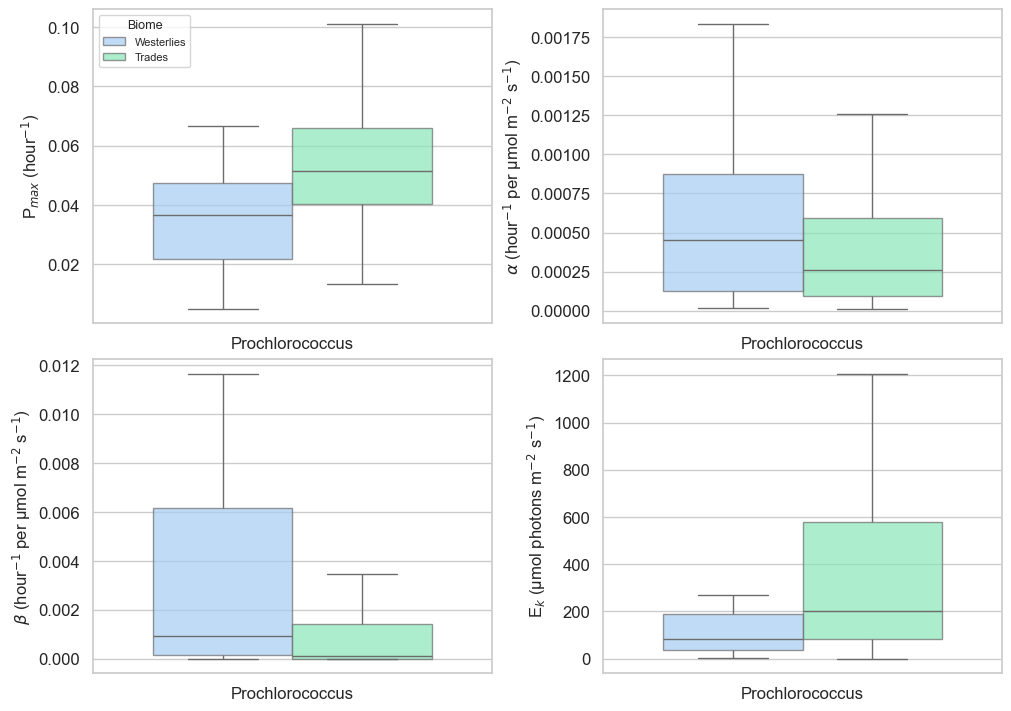

In [707]:
params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax':  'P$_{max}$ (hour$^{-1}$)',
    'alpha': r'$\alpha$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'beta':  r'$\beta$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
}

sns.set(style='whitegrid')

pops = ['prochloro']#, 'synecho', 'picoeuk']

# # get biome categories present in the dataframe
# biomes = sorted(bio_PI_all['biome'].dropna().unique())

# # make a color palette for biome
# biome_colors = sns.color_palette('Set2', n_colors=len(biomes))
palette = {
    'Coastal': "#F86FC1",
    'Westerlies': '#99CCFF',
    'Trades': "#79F5B7"
}
# palette = dict(zip(biomes, biome_colors))

fig, axs = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
axs = axs.flatten()

for ax, param in zip(axs, params):
    df_param = (
        bio_PI_all[['pop', 'biome', param]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if df_param.empty:
        ax.set_visible(False)
        continue

    sns.boxplot(
        data=df_param,
        x='pop',
        y=param,
        hue='biome',
        order=pops,
        hue_order=biomes,
        boxprops=dict(alpha=0.7),
        palette=palette,
        dodge=True,      # separate biome boxes within each population
        width=0.7,
        showfliers = False,
        ax=ax
    )

    ax.set_xlabel('')
    ax.set_ylabel(param_labels[param], fontsize=12)
    ax.tick_params(labelsize=12)
    ax.set_xticklabels(['Prochlorococcus', 'Synechococcus', 'Picoeukaryotes'])
    # ax.set_title(f'{param}: n={len(df_param)}', fontsize=9)

# keep legend only on the first subplot, remove from others
for i, ax in enumerate(axs):
    if ax.get_legend() is not None:
        if i == 0:
            ax.legend(title='Biome', fontsize=8, title_fontsize=9)
        else:
            ax.get_legend().remove()

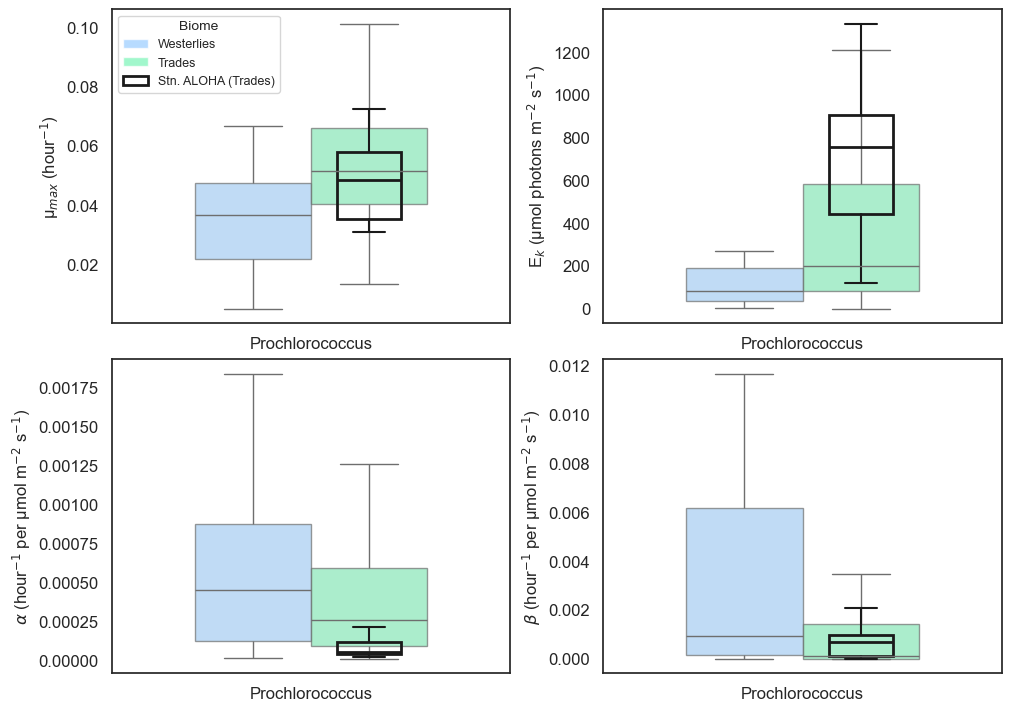

In [920]:
import matplotlib.patches as mpatches

params = ['Pmax', 'Ek', 'alpha', 'beta']
param_labels = {
    'Pmax':  'µ$_{max}$ (hour$^{-1}$)',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
    'alpha': r'$\alpha$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'beta':  r'$\beta$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
}

sns.set(style='white')

pops   = ['prochloro']
biomes = ['Westerlies', 'Trades']

palette = {
    'Westerlies': '#99CCFF',
    'Trades':     '#79F5B7',
}

aloha_color  = '#1a1a1a'
aloha_cruise = 'KM1513'   # change if needed

fig, axs = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
axs = axs.flatten()

total_width = 0.7
n_biomes = len(biomes)
box_width = total_width / n_biomes

# for 2 biomes, these become [-0.175, +0.175] when total_width=0.7
offsets = np.linspace(
    -total_width/2 + box_width/2,
     total_width/2 - box_width/2,
     n_biomes
)

for ax, param in zip(axs, params):
    df_param = (
        bio_PI_all[['pop', 'biome', 'cruise', param]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    # keep only requested pop + biomes
    df_param = df_param[
        df_param['pop'].isin(pops) &
        df_param['biome'].isin(biomes)
    ]

    if df_param.empty:
        ax.set_visible(False)
        continue

    # ── main biome boxplots ─────────────────────────────────────
    sns.boxplot(
        data=df_param,
        x='pop',
        y=param,
        hue='biome',
        order=pops,
        hue_order=biomes,
        palette=palette,
        boxprops=dict(alpha=0.7),
        dodge=True,
        width=total_width,
        showfliers=False,
        ax=ax,
    )

    # ── ALOHA overlay on Trades box ─────────────────────────────
    df_aloha = df_param[
        (df_param['cruise'] == aloha_cruise) &
        (df_param['biome'] == 'Trades')
    ]

    if not df_aloha.empty:
        trades_idx = biomes.index('Trades')
        pop_x = 0  # only one pop category
        trades_x = pop_x + offsets[trades_idx]

        ax.boxplot(
            df_aloha[param].dropna(),
            positions=[trades_x],
            widths=box_width * 0.55,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(facecolor='none', edgecolor=aloha_color, linewidth=2),
            medianprops=dict(color=aloha_color, linewidth=2),
            whiskerprops=dict(color=aloha_color, linewidth=1.5),
            capprops=dict(color=aloha_color, linewidth=1.5),
        )

    ax.set_xlabel('')
    ax.set_ylabel(param_labels[param], fontsize=12)
    ax.tick_params(labelsize=12)
    ax.set_xticks([0])
    ax.set_xticklabels(['Prochlorococcus'])

    # force the single category to appear visually centered
    ax.set_xlim(-0.6, 0.6)

# ── legend ──────────────────────────────────────────────────────
for ax in axs:
    if ax.get_legend() is not None:
        ax.get_legend().remove()

aloha_patch = mpatches.Patch(
    facecolor='none',
    edgecolor=aloha_color,
    linewidth=2,
    label='Stn. ALOHA (Trades)'
)

biome_patches = [
    mpatches.Patch(facecolor=palette[b], alpha=0.7, label=b)
    for b in biomes
]

axs[0].legend(
    handles=biome_patches + [aloha_patch],
    title='Biome',
    fontsize=9,
    title_fontsize=10
)

plt.show()

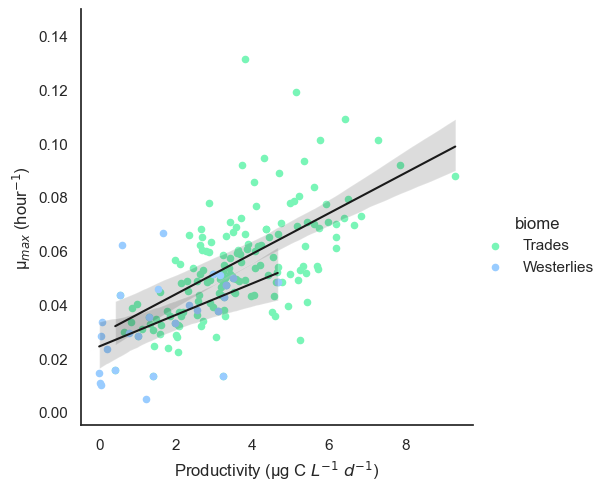

In [740]:
# merge productivity and growth parameters
productivity_PI_df = bio_PI_all.merge(final_rates)
productivity_PI_df = productivity_PI_df.loc[productivity_PI_df['biome'] != 'Coastal']

sns.set_theme(style = 'white')
params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax':  'µ$_{max}$ (hour$^{-1}$)',
    'alpha': r'$\alpha$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'beta':  r'$\beta$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
}
palette = {
    'Westerlies': '#99CCFF',
    'Trades':     '#79F5B7',
}
sns.lmplot(
    data=productivity_PI_df,
    x='productivity',
    hue = 'biome',
    y='Pmax',
    palette=palette,
    scatter_kws={'s': 20, 'alpha': 1},
    line_kws={'color': 'k', 'linewidth': 1.5},
    ci=95   # or ci=None if you don’t want the confidence band
)

plt.xlabel('Productivity (µg C $L^{-1}$ $d^{-1}$)', fontsize=12)
plt.ylabel('µ$_{max}$ (hour$^{-1}$)', fontsize=12)
ax.tick_params(labelsize=9)
plt.ylim(-0.005, 0.15)

plt.show()

Text(63.07242838541667, 0.5, 'Productivity (µg C $L^{-1}$ $d^{-1}$)')

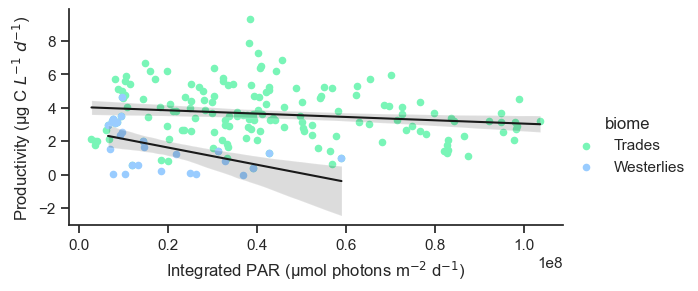

In [834]:
# show integrated PAR Westerlies vs. Trades
max_intpar = clean_growth.groupby(['cruise', 'cruise_day'])['int_par'].max().reset_index()
par_productivity_PI = max_intpar.merge(productivity_PI_df)

palette = {
    'Westerlies': '#99CCFF',
    'Trades':     '#79F5B7',
}
sns.lmplot(
    data=par_productivity_PI,
    x='int_par',
    hue = 'biome',
    y='productivity',
    palette=palette,
    scatter_kws={'s': 20, 'alpha': 1},
    line_kws={'color': 'k', 'linewidth': 1.5},
    ci=95,   # or ci=None if you don’t want the confidence band, 
    height=3, 
    aspect=2
)

plt.xlabel('Integrated PAR (µmol photons m$^{-2}$ d$^{-1}$)', fontsize=12)
# plt.ylabel('µ$_{max}$ (hour$^{-1}$)', fontsize=12)
ax.tick_params(labelsize=9)
# plt.ylim(-0.005, 0.15)
plt.ylabel('Productivity (µg C $L^{-1}$ $d^{-1}$)', fontsize=12)
# Productivity (µg C $L^{-1}$ $d^{-1}$)

In [838]:
from scipy.stats import linregress

sub_df = par_productivity_PI.loc[par_productivity_PI['biome'] == 'Westerlies']
x = sub_df['int_par'].values
y = sub_df['Pmax'].values

res = linregress(x, y)

print(f"slope = {res.slope:.4f}")
print(f"intercept = {res.intercept:.4f}")
print(f"R² = {res.rvalue**2:.3f}")
print(f"p-value (slope ≠ 0) = {res.pvalue:.4e}")

alpha = 0.05
if res.pvalue < alpha:
    print("The linear relationship is statistically significant.")
else:
    print("No statistically significant linear relationship at α = 0.05.")

slope = -0.0000
intercept = 0.0430
R² = 0.151
p-value (slope ≠ 0) = 4.1357e-02
The linear relationship is statistically significant.


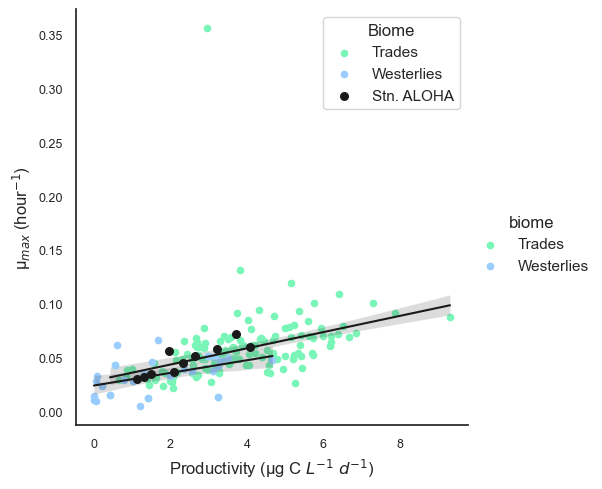

In [749]:
# merge productivity and growth parameters
productivity_PI_df = bio_PI_all.merge(final_rates)
productivity_PI_df = productivity_PI_df.loc[productivity_PI_df['biome'] != 'Coastal']

sns.set_theme(style='white')

palette = {
    'Westerlies': '#99CCFF',
    'Trades':     '#79F5B7',
}

# Base regression + colored points by biome
g = sns.lmplot(
    data=productivity_PI_df,
    x='productivity',
    y='Pmax',
    hue='biome',
    palette=palette,
    scatter_kws={'s': 20, 'alpha': 1},
    line_kws={'color': 'k', 'linewidth': 1.5},
    ci=95
)

ax = g.axes[0, 0]

# Overlay Station ALOHA (KM1513) as black points
aloha = productivity_PI_df[productivity_PI_df['cruise'] == 'KM1513']

ax.scatter(
    aloha['productivity'],
    aloha['Pmax'],
    s=30,
    color='k',
    edgecolor='k',
    zorder=5,
    label='Stn. ALOHA'
)

# Optional: add ALOHA to legend
handles, labels = ax.get_legend_handles_labels()
if 'Stn. ALOHA' not in labels:
    handles.append(plt.Line2D([0], [0], marker='o', color='k', linestyle='',
                              markersize=5, label='Stn. ALOHA'))
    labels.append('Stn. ALOHA')
ax.legend(handles, labels, title='Biome')

ax.set_xlabel('Productivity (µg C $L^{-1}$ $d^{-1}$)', fontsize=12)
ax.set_ylabel('µ$_{max}$ (hour$^{-1}$)', fontsize=12)
ax.tick_params(labelsize=9)
# ax.set_ylim(-0.005, 0.15)

plt.show()

In [776]:
len(bio_PI_all['cruise'].unique())

40

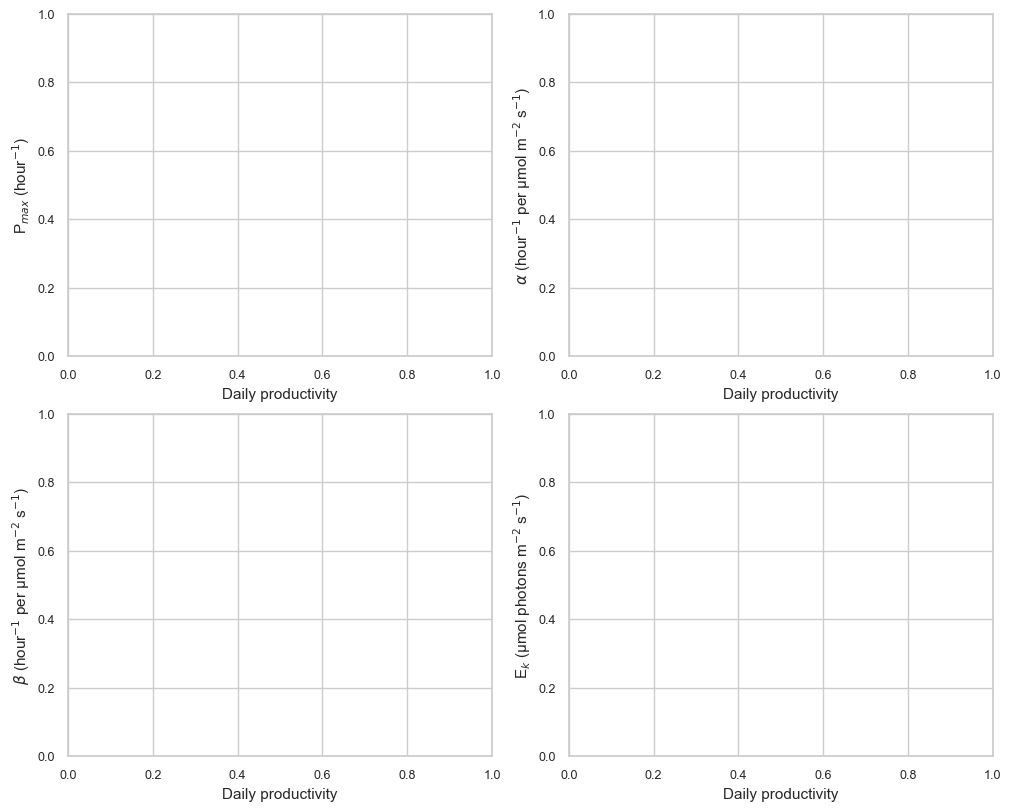

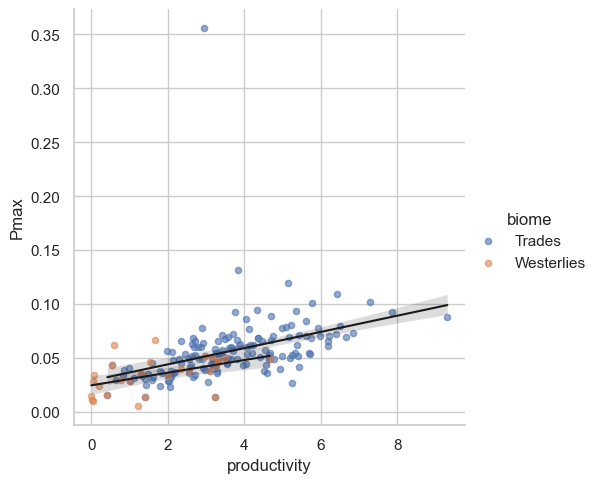

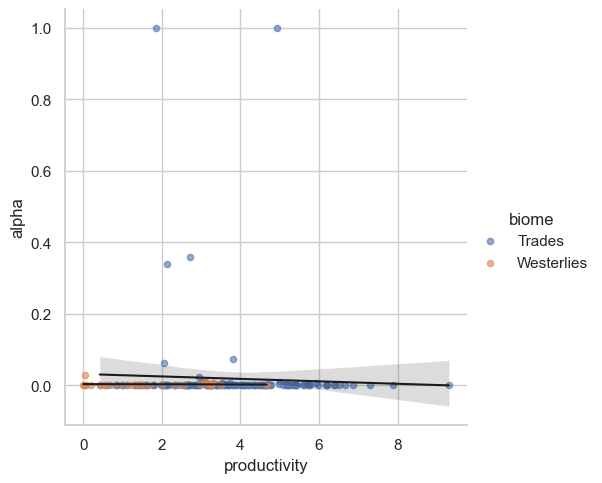

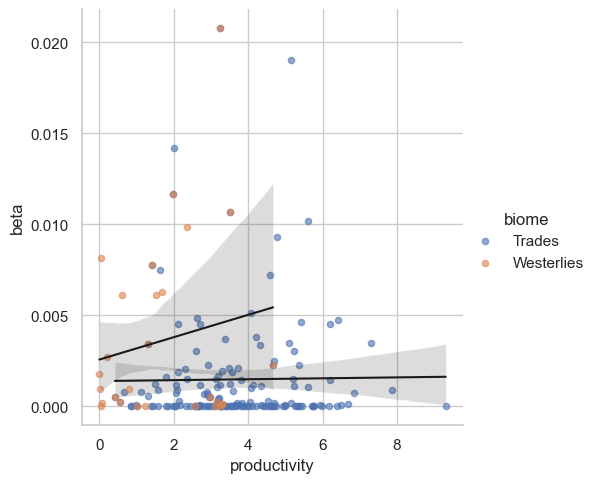

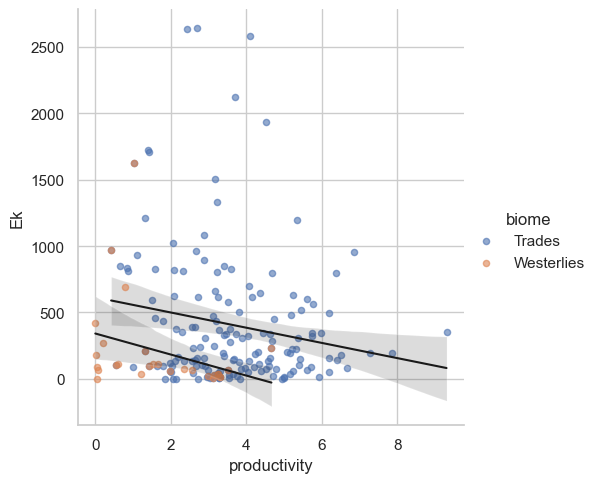

In [751]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set(style='whitegrid')

params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax':  'P$_{max}$ (hour$^{-1}$)',
    'alpha': r'$\alpha$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'beta':  r'$\beta$ (hour$^{-1}$ per µmol m$^{-2}$ s$^{-1}$)',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
}

# Optionally drop inf/nan
df = productivity_PI_df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['productivity'] + params
)

fig, axs = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
axs = axs.flatten()

for ax, param in zip(axs, params):
    sns.lmplot(
        data=df,
        x='productivity',
        y=param,
        hue = 'biome',
        scatter_kws={'s': 20, 'alpha': 0.6},
        line_kws={'color': 'k', 'linewidth': 1.5},
        ci=95   # or ci=None if you don’t want the confidence band
    )

    ax.set_xlabel('Daily productivity', fontsize=11)
    ax.set_ylabel(param_labels[param], fontsize=11)
    ax.tick_params(labelsize=9)

# If you have only 3 params, hide the last empty axis:
for i in range(len(params), len(axs)):
    axs[i].set_visible(False)

plt.show()

In [741]:
from scipy.stats import linregress

x = productivity_PI_df['productivity'].values
y = productivity_PI_df['Pmax'].values

res = linregress(x, y)

print(f"slope = {res.slope:.4f}")
print(f"intercept = {res.intercept:.4f}")
print(f"R² = {res.rvalue**2:.3f}")
print(f"p-value (slope ≠ 0) = {res.pvalue:.4e}")

alpha = 0.05
if res.pvalue < alpha:
    print("The linear relationship is statistically significant.")
else:
    print("No statistically significant linear relationship at α = 0.05.")

slope = 0.0079
intercept = 0.0261
R² = 0.196
p-value (slope ≠ 0) = 1.3695e-10
The linear relationship is statistically significant.


In [675]:
from itertools import combinations
from scipy.stats import mannwhitneyu

# Parameters and biomes to test
params = ['Pmax', 'alpha', 'beta', 'Ek']
biomes = ['Trades', 'Westerlies', 'Coastal']  # or sorted(bio_PI_all['biome'].dropna().unique())

# Optional: function to drop inf/nan
def clean_series(s):
    return s.replace([np.inf, -np.inf], np.nan).dropna()

results = []

for param in params:
    print(f"\n{'='*50}")
    print(f"Parameter: {param}")
    print(f"{'='*50}")

    # Subset to rows where this parameter and biome are defined
    df_p = bio_PI_all[['biome', param]].copy()
    df_p[param] = clean_series(df_p[param])
    df_p = df_p.dropna(subset=['biome', param])

    # All biome pairs
    pairs = list(combinations(biomes, 2))
    m = len(pairs)
    alpha_bonf = 0.05 / m

    for b1, b2 in pairs:
        g1 = df_p.loc[df_p['biome'] == b1, param].values
        g2 = df_p.loc[df_p['biome'] == b2, param].values

        # Require at least a few samples in each group
        if len(g1) < 3 or len(g2) < 3:
            print(f"{param}: {b1} vs {b2} – not enough data (n1={len(g1)}, n2={len(g2)})")
            continue

        # Two-sided Mann–Whitney U-test
        U, p = mannwhitneyu(g1, g2, alternative='two-sided')

        # Bonferroni-corrected p
        p_corr = p * m
        sig = 'ns'
        if p < 0.05:
            sig = '*'
        if p < 0.01:
            sig = '**'
        if p < 0.001:
            sig = '***'

        sig_bonf = ' (Bonferroni sig)' if p_corr < 0.05 else ''

        print(
            f"{b1} vs {b2}: "
            f"U={U:.1f}, p={p:.4g}, p_corr={p_corr:.4g}, "
            f"n1={len(g1)}, n2={len(g2)}, {sig}{sig_bonf}"
        )

        results.append({
            'param': param,
            'biome_1': b1,
            'biome_2': b2,
            'n1': len(g1),
            'n2': len(g2),
            'U': U,
            'p_raw': p,
            'p_bonf': p_corr,
            'significant_raw': p < 0.05,
            'significant_bonf': p_corr < 0.05,
            'median_1': np.median(g1),
            'median_2': np.median(g2),
        })

# Optional: collect into a DataFrame for export or plotting
results_df = pd.DataFrame(results)
# results_df.to_csv('../results/biome_mannwhitney_PI_params.csv', index=False)


Parameter: Pmax
Trades vs Westerlies: U=1383828.0, p=8.401e-14, p_corr=2.52e-13, n1=4593, n2=501, *** (Bonferroni sig)
Pmax: Trades vs Coastal – not enough data (n1=4593, n2=1)
Pmax: Westerlies vs Coastal – not enough data (n1=501, n2=1)

Parameter: alpha
Trades vs Westerlies: U=757379.0, p=2.738e-36, p_corr=8.214e-36, n1=4593, n2=501, *** (Bonferroni sig)
alpha: Trades vs Coastal – not enough data (n1=4593, n2=1)
alpha: Westerlies vs Coastal – not enough data (n1=501, n2=1)

Parameter: beta
Trades vs Westerlies: U=661156.0, p=2.922e-55, p_corr=8.766e-55, n1=4593, n2=501, *** (Bonferroni sig)
beta: Trades vs Coastal – not enough data (n1=4593, n2=1)
beta: Westerlies vs Coastal – not enough data (n1=501, n2=1)

Parameter: Ek
Trades vs Westerlies: U=1711130.0, p=6.174e-72, p_corr=1.852e-71, n1=4593, n2=501, *** (Bonferroni sig)
Ek: Trades vs Coastal – not enough data (n1=4593, n2=1)
Ek: Westerlies vs Coastal – not enough data (n1=501, n2=1)


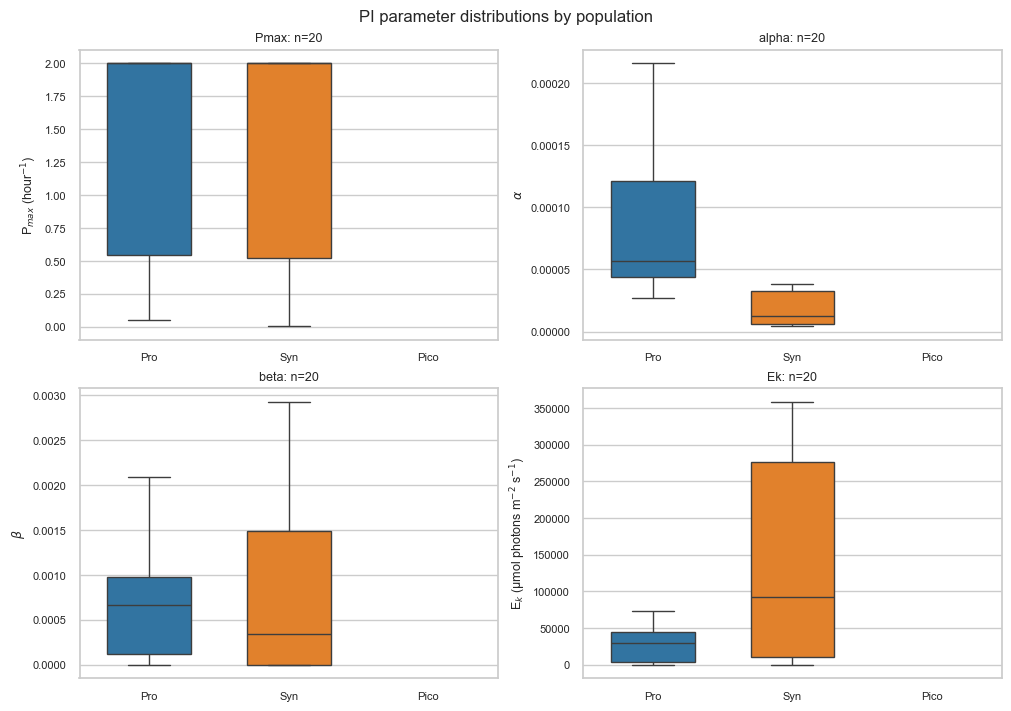

In [441]:
params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax':  'P$_{max}$ (hour$^{-1}$)',
    'alpha': r'$\alpha$',
    'beta':  r'$\beta$',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
}

ylims = {
    'Pmax':  (0, 2.5),
    'alpha': (0, 0.5),
    'beta':  (0, 0.004),
    'Ek':    (0, 10000)
}

sns.set(style='whitegrid')

pops = ['prochloro', 'synecho', 'picoeuk']
palette = {
    'prochloro': 'tab:blue',
    'synecho':   'tab:orange',
    'picoeuk':   'tab:green'
}

fig, axs = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
axs = axs.flatten()
fig.suptitle('PI parameter distributions by population', fontsize=12)

for ax, param in zip(axs, params):
    df_param = (
        diel_pi[['pop', param]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if df_param.empty:
        ax.set_visible(False)
        continue

    sns.boxplot(
        data=df_param,
        x='pop',
        y=param,
        hue='pop',
        order=pops,
        hue_order=pops,
        palette=palette,
        dodge=False,      # prevents duplicate side-by-side boxes
        width=0.6,
        showfliers=False,
        ax=ax
    )

    # remove legend
    if ax.get_legend() is not None:
        ax.get_legend().remove()

    ax.set_xlabel('')
    ax.set_ylabel(param_labels[param], fontsize=9)
    ax.tick_params(labelsize=8)
    ax.set_xticklabels(['Pro', 'Syn', 'Pico'])
    # ax.set_ylim(*ylims[param])

    # optional summary in title
    n_total = len(df_param)
    ax.set_title(f'{param}: n={n_total}', fontsize=9)

In [ ]:
bio_PI_all.to_csv('~/Downloads/bio_pi_all.csv')

In [546]:
import pandas as pd
import numpy as np
from scipy.stats import kruskal, mannwhitneyu
from itertools import combinations

# ── configuration ────────────────────────────────────────────────
params = ['Pmax', 'alpha', 'beta', 'Ek']
group_cols = ['pop', 'biome']

pop_order   = ['prochloro', 'synecho', 'picoeuk']
biome_order = ['Trades', 'Westerlies', 'Coastal']

# ── helpers ──────────────────────────────────────────────────────
def remove_iqr_outliers(df, value_col, group_cols, k=1.5):
    def _trim(g):
        q1, q3 = g[value_col].quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr == 0:
            return g
        return g[(g[value_col] >= q1 - k * iqr) & (g[value_col] <= q3 + k * iqr)]
    return df.groupby(group_cols, group_keys=False).apply(_trim)

def pairwise_mwu(d, param, groupcol, order):
    """Run pairwise Mann-Whitney U tests with Bonferroni correction."""
    pairs = list(combinations(order, 2))
    n_comp = len(pairs)
    alpha_bonf = 0.05 / n_comp

    rows = []
    for a, b in pairs:
        ga = d[d[groupcol] == a][param].dropna().values
        gb = d[d[groupcol] == b][param].dropna().values
        if len(ga) < 3 or len(gb) < 3:
            rows.append({
                'group_1': a, 'group_2': b,
                'n_1': len(ga), 'n_2': len(gb),
                'U': np.nan, 'p_raw': np.nan,
                'p_bonf': np.nan, 'significant': False,
                'median_1': np.median(ga) if len(ga) else np.nan,
                'median_2': np.median(gb) if len(gb) else np.nan,
            })
            continue
        u, p = mannwhitneyu(ga, gb, alternative='two-sided')
        rows.append({
            'group_1': a, 'group_2': b,
            'n_1': len(ga), 'n_2': len(gb),
            'U': round(u, 1), 'p_raw': round(p, 5),
            'p_bonf': round(p * n_comp, 5),  # Bonferroni-adjusted p
            'significant': p < alpha_bonf,
            'median_1': round(np.median(ga), 6),
            'median_2': round(np.median(gb), 6),
        })
    return pd.DataFrame(rows)

# ── main test loop ────────────────────────────────────────────────
results = {}

# deduplicate first
df_u = bio_PI_all.drop_duplicates(subset=['pop', 'cruise', 'cruise_day']).copy()

for param in params:
    print(f"\n{'='*60}")
    print(f"  PARAMETER: {param}")
    print(f"{'='*60}")

    d_raw = df_u[['pop', 'biome', param]].replace([np.inf, -np.inf], np.nan).dropna()
    d = remove_iqr_outliers(d_raw, param, ['pop', 'biome'])

    for groupcol, order in [('pop', pop_order), ('biome', biome_order)]:
        print(f"\n── By {groupcol} ──")

        # Kruskal-Wallis
        groups = [d[d[groupcol] == g][param].dropna().values for g in order]
        groups = [g for g in groups if len(g) >= 3]
        if len(groups) < 2:
            print("  Not enough groups for Kruskal-Wallis.")
            continue

        h, p_kw = kruskal(*groups)
        sig = '***' if p_kw < 0.001 else ('**' if p_kw < 0.01 else ('*' if p_kw < 0.05 else 'ns'))
        print(f"  Kruskal-Wallis: H={h:.3f}, p={p_kw:.5f} {sig}")

        # Pairwise Mann-Whitney (only if KW is significant or borderline)
        pw = pairwise_mwu(d, param, groupcol, order)
        pw.insert(0, 'param', param)
        pw.insert(1, 'groupcol', groupcol)

        # print pairwise table
        print(f"\n  Pairwise (Bonferroni α = {0.05/len(list(combinations(order,2))):.4f}):")
        print(f"  {'Group 1':<15} {'Group 2':<15} {'n1':>4} {'n2':>4} "
              f"{'median_1':>12} {'median_2':>12} {'U':>10} {'p_raw':>10} {'sig':>6}")
        print("  " + "-"*90)
        for _, row in pw.iterrows():
            sig_pw = '***' if row['p_raw'] < 0.001 else ('**' if row['p_raw'] < 0.01 else
                     ('*' if row['p_raw'] < 0.05 else 'ns'))
            bonf_sig = ' ✓' if row['significant'] else ''
            print(f"  {str(row['group_1']):<15} {str(row['group_2']):<15} "
                  f"{int(row['n_1']) if not np.isnan(row['n_1']) else 'NA':>4} "
                  f"{int(row['n_2']) if not np.isnan(row['n_2']) else 'NA':>4} "
                  f"{row['median_1']:>12.6f} {row['median_2']:>12.6f} "
                  f"{row['U']:>10.1f} {row['p_raw']:>10.5f} "
                  f"{sig_pw:>4}{bonf_sig}")

        # store for export
        key = f"{param}_{groupcol}"
        results[key] = pw

print("\n\nDone.")

# ── optional: export all results to CSV ──────────────────────────
all_results = pd.concat(results.values(), ignore_index=True)
# all_results.to_csv('../results/PI_param_stats.csv', index=False)
# print("\nSaved: ../results/PI_param_stats.csv")


  PARAMETER: Pmax

── By pop ──
  Kruskal-Wallis: H=24.091, p=0.00001 ***

  Pairwise (Bonferroni α = 0.0167):
  Group 1         Group 2           n1   n2     median_1     median_2          U      p_raw    sig
  ------------------------------------------------------------------------------------------
  prochloro       synecho           76   48     0.059174     0.041350     2560.0    0.00016  *** ✓
  prochloro       picoeuk           76   51     0.059174     0.071811     1449.0    0.01628    * ✓
  synecho         picoeuk           48   51     0.041350     0.071811      618.0    0.00002  *** ✓

── By biome ──
  Kruskal-Wallis: H=11.642, p=0.00297 **

  Pairwise (Bonferroni α = 0.0167):
  Group 1         Group 2           n1   n2     median_1     median_2          U      p_raw    sig
  ------------------------------------------------------------------------------------------
  Trades          Westerlies       144   27     0.058169     0.046853     2488.0    0.02132    *
  Trades        

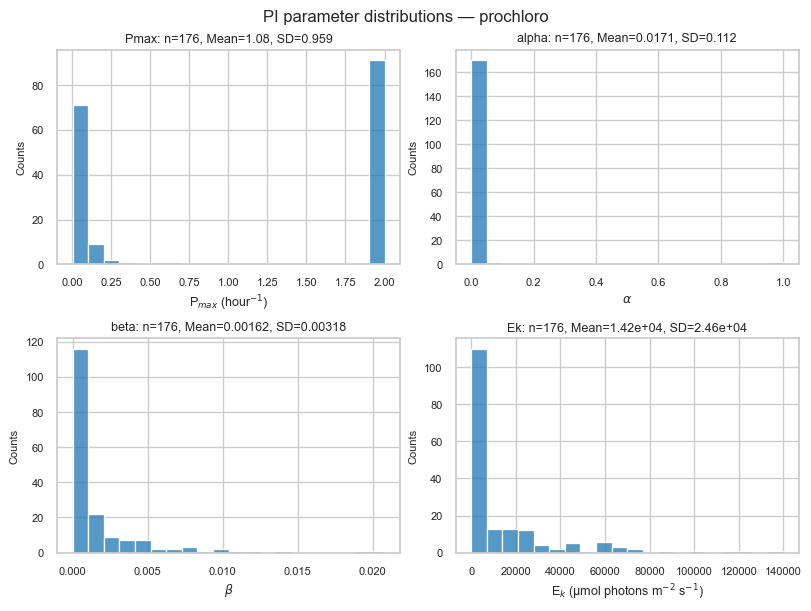

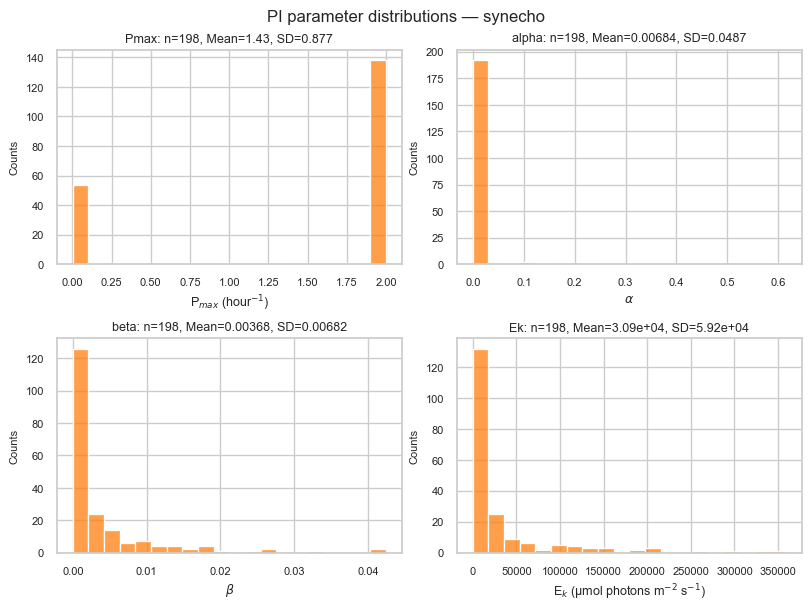

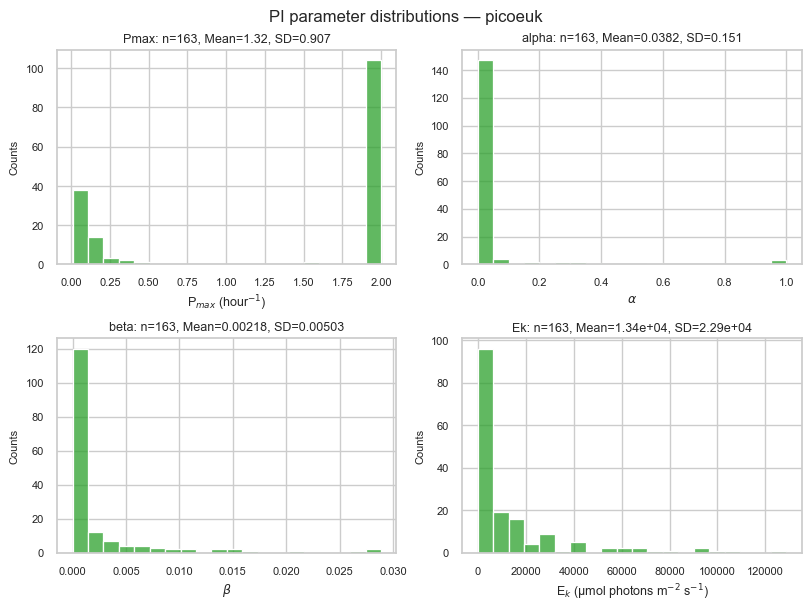

In [399]:
params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax':  'P$_{max}$ (hour$^{-1}$)',
    'alpha': r'$\alpha$',
    'beta':  r'$\beta$',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
}

# define limits for each param
xlims = {
    'Pmax':  (0, 2.5),
    'alpha': (0, 0.5),
    'beta':  (0, 0.004),
    'Ek':    (0, 10000)
}
# ylims = {
#     'Pmax':  (0, None),  # None lets matplotlib choose the upper bound
#     'alpha': (0, None),
#     'beta':  (0, None),
#     'Ek':    (0, None)
# }
sns.set(style='whitegrid')
# loop through and plot distributions
pops = ['prochloro', 'synecho', 'picoeuk']
colors = ['tab:blue', 'tab:orange', 'tab:green']
for pop, c in zip(pops, colors):
    df_pop = PI_params_df_all[PI_params_df_all['pop'] == pop].copy()

    fig, axs = plt.subplots(2, 2, figsize=(8, 6), constrained_layout=True)
    axs = axs.flatten()
    fig.suptitle(f'PI parameter distributions — {pop}', fontsize=12)

    for ax, param in zip(axs, params):
        x = df_pop[param].replace([np.inf, -np.inf], np.nan).dropna()

        if x.empty:
            ax.set_visible(False)
            continue

        sns.histplot(x=x, color = c,
                        edgecolor='white',
                        bins=20, ax=ax)
        ax.set_xlabel(param_labels[param], fontsize=9)
        ax.set_ylabel('Counts', fontsize=8)
        ax.tick_params(labelsize=8)
        # ax.set_xlim(*xlims[param])
        # quick summary in title
        ax.set_title(
            f'{param}: n={len(x)}, Mean={np.nanmean(x):.3g}, SD={np.nanstd(x):.3g}',
            fontsize=9
        )

In [335]:
station_aloha_PI_params = PI_params_df

### Platt curves first second part of day

In [ ]:
def platt_shifted(E, Ps, alpha, beta, P0):
    """
    Platt model with a vertical shift for second-half fitting.
    P0: growth rate intercept at E=0 (carryover from prior light history).
    Ps: incremental Pmax above P0.
    """
    return P0 + Ps * (1 - np.exp(-alpha * E / Ps)) * np.exp(-beta * E / Ps)

def best_platt_fit_shifted(E, P, maxfev=10000):
    """
    Grid search for second-half PI fits where P(0) != 0.
    P0 is estimated from observed low-light points, not freely optimized.
    """
    # Anchor P0: median of points in the lowest 15th percentile of E
    low_mask = E <= np.percentile(E, 15)
    if low_mask.sum() > 0:
        P0_est = np.nanmedian(P[low_mask])
    else:
        P0_est = P[np.argmin(E)]

    # Work in shifted space: fit Platt to (P - P0_est)
    P_shifted = P - P0_est
    P_max_shifted = np.nanmax(P_shifted)

    if P_max_shifted <= 0:
        # No positive response above baseline — unfittable
        return None, None, np.inf, P0_est

    E_peak = E[np.argmax(P_shifted)]

    alpha_min = P_max_shifted / 1500.0
    alpha_max = P_max_shifted / 30.0
    alpha_guesses = np.geomspace(alpha_min, alpha_max, 8).tolist()

    Ps_guesses   = [P_max_shifted * f for f in [0.8, 1.0, 1.3, 1.6]]
    beta_guesses = [0.0] + np.geomspace(1e-6, 1e-3, 3).tolist()

    bounds_lower = [0,    0,    0    ]
    bounds_upper = [P_max_shifted * 3, 1.0, 0.05]

    best_popt, best_pcov, best_rss = None, None, np.inf

    for p0 in product(Ps_guesses, alpha_guesses, beta_guesses):
        if not all(lo <= v <= hi for v, lo, hi in zip(p0, bounds_lower, bounds_upper)):
            continue
        try:
            popt, pcov = curve_fit(
                platt, E, P_shifted,     # fit standard Platt on shifted P
                p0=list(p0),
                bounds=(bounds_lower, bounds_upper),
                maxfev=maxfev,
                method='trf',
                ftol=1e-10, xtol=1e-10,
            )
            rss = np.sum((P_shifted - platt(E, *popt)) ** 2)
            if rss < best_rss:
                best_rss, best_popt, best_pcov = rss, popt, pcov
        except (RuntimeError, ValueError):
            continue

    return best_popt, best_pcov, best_rss, P0_est

KeyboardInterrupt: 

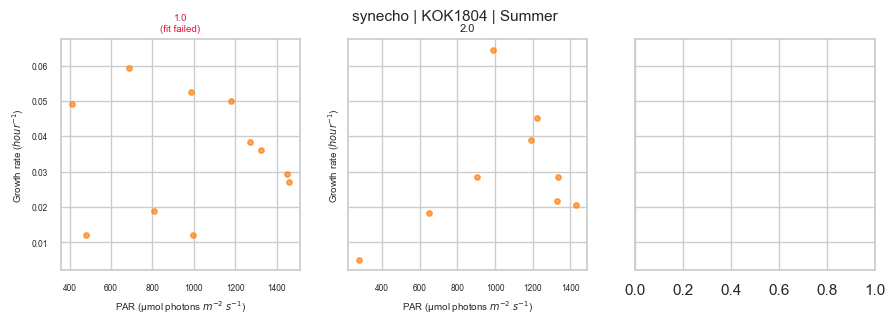

In [ ]:
from scipy.optimize import curve_fit

# exclude bad cruises
all_growth = pd.concat(growth_dfs)
clean_growth = all_growth.loc[~all_growth['cruise'].isin(bad['cruise'].values)]
clean_growth.loc[clean_growth['slope'] < 0, 'slope'] = 0

# save PI params per day and cruise
PI_params = []

pops = ['synecho']
colors = ['tab:orange']
sns.set(style='whitegrid')
for pop, color in zip(pops, colors):
    pop_df = clean_growth.loc[clean_growth['pop'] == pop]

    with PdfPages(f'../figures/{pop}_platt_fit_second_{timeres}.pdf') as pdf:
        for season in season_order:
            season_df = pop_df.loc[pop_df['season'] == season]

            for cruise, cruise_df in season_df.groupby('cruise'):
                days = sorted(cruise_df['cruise_day'].unique())
                n_days = len(days)
                if n_days == 0:
                    continue

                # --- FacetGrid layout ---
                ncols = min(4, n_days)
                nrows = int(np.ceil(n_days / ncols))
                fig, axs = plt.subplots(nrows, ncols,
                                        figsize=(ncols * 3.5, nrows * 3),
                                        sharey=True)
                axs = np.array(axs).flatten()
                fig.suptitle(f'{pop} | {cruise} | {season}', fontsize=11)
                # create a facetgrid layout using matplotlib
                for j, day in enumerate(days):
                    ax = axs[j]
                    day_df = cruise_df.loc[cruise_df['cruise_day'] == day]
                    # redefine halfway point
                    day_df['halfway_hour'] = day_df['halfway_hour'] - 4
                    day_df['day_half'] = np.where(
                        day_df['hour'] < day_df['halfway_hour'],
                        'first',
                        'second'
                    )
                    day_df = day_df.loc[day_df['day_half'] == 'second']
                    # --- Skip days with fewer than 6 points ---
                    if len(day_df) < 6:
                        ax.set_visible(False)
                        continue
                    E = day_df['par_smooth'].values
                    P = day_df['slope'].values

                    # scatter raw data
                    ax.scatter(E, P, s=15, color=color, alpha=0.7, label='data')
                    ax.set_title(str(day), fontsize=8)
                    ax.set_xlabel('PAR (µmol photons $m^{-2}$ $s^{-1}$)', fontsize=7)
                    ax.set_ylabel('Growth rate ($hour^{-1}$)', fontsize=7)
                    ax.tick_params(labelsize=6)

                    # attempt Platt fit
                    if len(E) < 4:
                        ax.set_title(f'{day}\n(too few points)', fontsize=7, color='grey')
                        continue
                    try:
                        # perform grid search over best potential PI params
                        popt, pcov, rss = best_platt_fit_shifted(E, P)
                        # check if fits failed
                        if popt is None:
                            ax.set_title(f'{day}\n(all fits failed)', fontsize=7, color='crimson')
                            continue
                        # get fits
                        Ps_fit, alpha_fit, beta_fit = popt

                        E_range = np.linspace(0, E.max(), 200)
                        ax.plot(E_range, platt_shifted(E_range, *popt),
                                color='k', linestyle='--', lw=1, label='Shifted Platt fit')

                        Ek = Ps_fit / alpha_fit if alpha_fit != 0 else np.nan
                        # ax.set_title(f'{day}\nEk={Ek:.1f}', fontsize=7)

                        PI_params.append({
                            'pop':    pop,
                            'cruise': cruise,
                            'season': season,
                            'date':   day,
                            'Pmax':   Ps_fit,
                            'alpha':  alpha_fit,
                            'beta':   beta_fit,
                            'Ek':     Ek,
                            'mld':    np.mean(day_df['mld'])
                        })

                    except (RuntimeError, ValueError) as e:
                        ax.set_title(f'{day}\n(fit failed)', fontsize=7, color='crimson')

                # hide unused subplots
                for k in range(j + 1, len(axs)):
                    axs[k].set_visible(False)

                plt.tight_layout()
                pdf.savefig(fig, bbox_inches='tight')
                plt.close(fig)

# collect params into a DataFrame
PI_params_df_second = pd.DataFrame(PI_params)

In [ ]:
from scipy.optimize import curve_fit

# half-specific colors and styles
HALF_STYLE = {
    'first':  {'color': 'tab:blue',  'linestyle': '--', 'marker_alpha': 0.7, 'label': 'First half'},
    'second': {'color': 'tab:orange', 'linestyle': ':',  'marker_alpha': 0.5, 'label': 'Second half'},
}

PI_params = []

sns.set(style='whitegrid')
# pops = ['prochloro', 'synecho', 'picoeuk']
# colors = ['tab:blue', 'tab:orange', 'tab:green']
pops = ['prochloro']
colors = ['tab:blue']
for pop, color in zip(pops, colors):
    # update first-half color to match the population color
    HALF_STYLE['first']['color'] = color

    pop_df = clean_growth.loc[clean_growth['pop'] == pop]

    with PdfPages(f'../figures/{pop}_platt_fit_{timeres}.pdf') as pdf:
        for season in season_order:
            season_df = pop_df.loc[pop_df['season'] == season]

            for cruise, cruise_df in season_df.groupby('cruise'):
                days = sorted(cruise_df['cruise_day'].unique())
                n_days = len(days)
                if n_days == 0:
                    continue

                ncols = min(4, n_days)
                nrows = int(np.ceil(n_days / ncols))
                fig, axs = plt.subplots(nrows, ncols,
                                        figsize=(ncols * 3.5, nrows * 3),
                                        sharey=True)
                axs = np.array(axs).flatten()
                fig.suptitle(f'{pop} | {cruise} | {season}', fontsize=11)

                for j, day in enumerate(days):
                    ax = axs[j]
                    day_df = cruise_df.loc[cruise_df['cruise_day'] == day]

                    # track what actually gets plotted for title building
                    title_parts = [str(day)]
                    any_plotted = False

                    for half, style in HALF_STYLE.items():
                        if half == 'second':
                            # grab 4 hours back
                            sub_df = day_df.copy()
                            sub_df['halfway_hour'] = sub_df['halfway_hour'] - 4
                            sub_df['day_half'] = np.where(
                                sub_df['hour'] < sub_df['halfway_hour'],
                                'first',
                                'second'
                            )
                            half_df = sub_df.loc[day_df['day_half'] == half]
                        else:
                            half_df = day_df.loc[day_df['day_half'] == half]
                        if len(half_df) < 6:
                            continue

                        E = half_df['par_smooth'].values
                        P = half_df['slope'].values

                        ax.scatter(E, P, s=15, color=style['color'], alpha=style['marker_alpha'],
                                label=f"{style['label']} (data)")

                        if half == 'first':
                            popt, pcov, rss = best_platt_fit(E, P)        # standard fit
                            if popt is not None:
                                Ps_fit, alpha_fit, beta_fit = popt
                                P0_fit = 0.0
                                fit_fn = lambda E_r, *p: platt(E_r, *p)
                        else:
                            popt, pcov, rss, P0_est = best_platt_fit_shifted(E, P)   # shifted fit
                            if popt is not None:
                                Ps_fit, alpha_fit, beta_fit = popt
                                P0_fit = P0_est
                                # reconstruct the full curve including the offset
                                fit_fn = lambda E_r, *p: P0_est + platt(E_r, *p)

                        if popt is None:
                            title_parts.append(f'{half}: fit failed')
                            continue

                        Ek = Ps_fit / alpha_fit if alpha_fit != 0 else np.nan
                        E_range = np.linspace(0, E.max() * 1.1, 300)
                        ax.plot(E_range, fit_fn(E_range, *popt),
                                color=style['color'], linestyle=style['linestyle'],
                                lw=1.5, label=f"{style['label']} Ek={Ek:.1f}")

                        PI_params.append({
                            'pop': pop, 'cruise': cruise, 'season': season,
                            'date': day, 'day_half': half,
                            'Pmax': Ps_fit, 'alpha': alpha_fit, 'beta': beta_fit,
                            'Ek': Ek, 'P0': P0_fit, 'rss': rss,
                            'mld': np.nanmean(half_df['mld']),
                            'Ek_within_range': Ek <= E.max(),
                        })

                        # except (RuntimeError, ValueError):
                        #     title_parts.append(f'{half}: fit error')

                    if not any_plotted:
                        ax.set_visible(False)
                        continue

                    ax.set_title('\n'.join(title_parts), fontsize=7)
                    ax.set_xlabel('PAR (µmol photons m⁻² s⁻¹)', fontsize=7)
                    ax.set_ylabel('Growth rate (d⁻¹)', fontsize=7)
                    ax.tick_params(labelsize=6)

                    # legend only on first panel to avoid clutter
                    if j == 0:
                        ax.legend(fontsize=5, loc='upper left', framealpha=0.5)

                for k in range(j + 1, len(axs)):
                    axs[k].set_visible(False)

                plt.tight_layout()
                pdf.savefig(fig, bbox_inches='tight')
                plt.close(fig)

PI_params_df = pd.DataFrame(PI_params)

### MLD vs. PI params

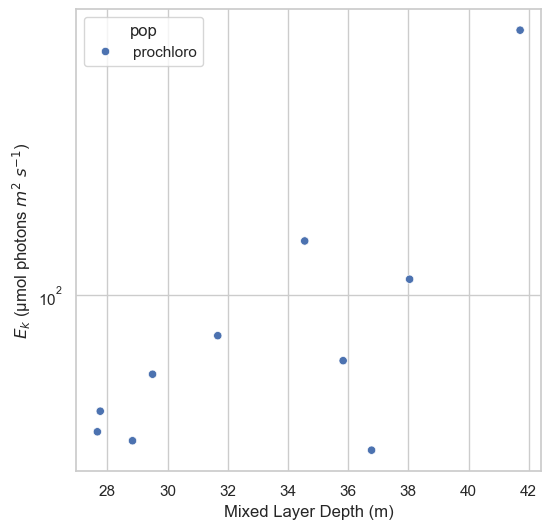

In [ ]:
diel_pi = PI_params_df.loc[(PI_params_df['cruise'] == 'KM1513') & (PI_params_df['pop'] == 'prochloro')]
# plot MLD against different vals
fig, axs = plt.subplots(figsize = (6, 6))
sns.scatterplot(diel_pi, x = 'mld', y = 'Ek', hue = 'pop', ax= axs)
axs.set_xlabel('Mixed Layer Depth (m)')
axs.set_ylabel('$E_k$ (µmol photons $m^{2}$ $s^{-1}$)')
axs.set_yscale('log')

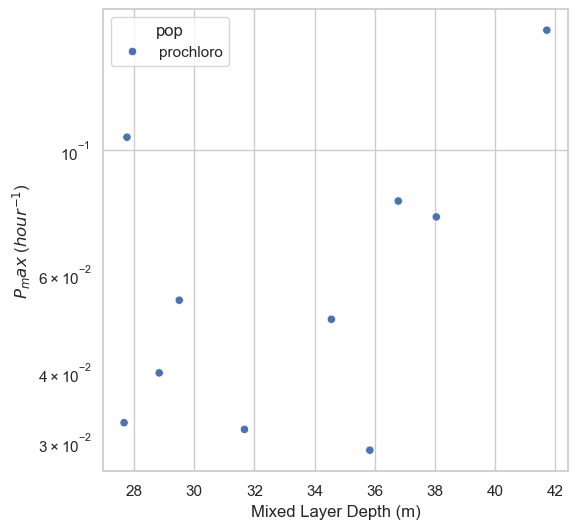

In [ ]:
# plot MLD against different vals
fig, axs = plt.subplots(figsize = (6, 6))
sns.scatterplot(diel_pi, x = 'mld', y = 'Pmax', hue = 'pop', ax= axs)
axs.set_xlabel('Mixed Layer Depth (m)')
axs.set_ylabel('$P_max$ ($hour^{-1}$)')
axs.set_yscale('log')

### Plot PI params distributions for each populaion

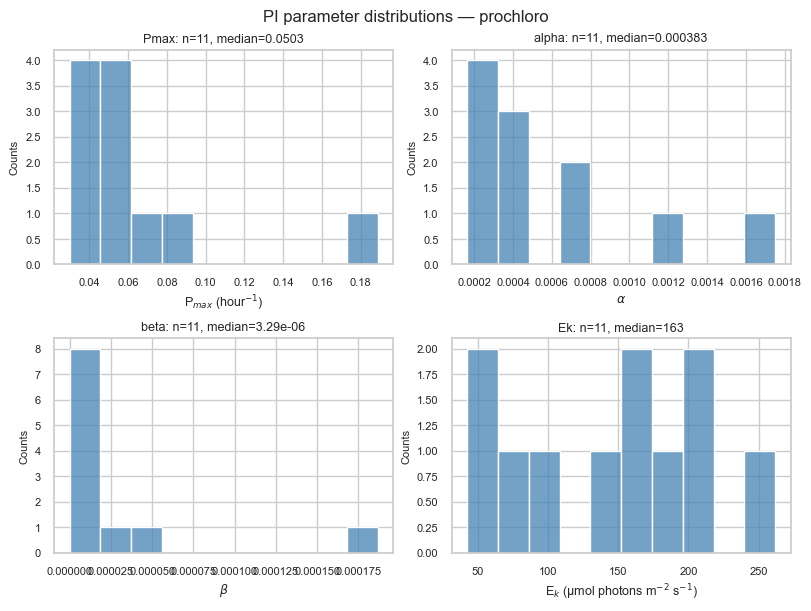

In [ ]:
params = ['Pmax', 'alpha', 'beta', 'Ek']
param_labels = {
    'Pmax':  'P$_{max}$ (hour$^{-1}$)',
    'alpha': r'$\alpha$',
    'beta':  r'$\beta$',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
}

# define limits for each param
xlims = {
    'Pmax':  (0, 100),
    'alpha': (0, 0.05),
    'beta':  (0, 0.2),
    'Ek':    (0, 1e7)
}
# ylims = {
#     'Pmax':  (0, None),  # None lets matplotlib choose the upper bound
#     'alpha': (0, None),
#     'beta':  (0, None),
#     'Ek':    (0, None)
# }
sns.set(style='whitegrid')
# loop through and plot distributions
pops = ['prochloro']
for pop in pops:
    df_pop = diel_pi[diel_pi['pop'] == pop].copy()

    fig, axs = plt.subplots(2, 2, figsize=(8, 6), constrained_layout=True)
    axs = axs.flatten()
    fig.suptitle(f'PI parameter distributions — {pop}', fontsize=12)

    for ax, param in zip(axs, params):
        x = df_pop[param].replace([np.inf, -np.inf], np.nan).dropna()

        if x.empty:
            ax.set_visible(False)
            continue

        sns.histplot(x=x,
                        color='steelblue', edgecolor='white',
                        bins=10, ax=ax)
        ax.set_xlabel(param_labels[param], fontsize=9)
        ax.set_ylabel('Counts', fontsize=8)
        ax.tick_params(labelsize=8)
        # ax.set_xlim(*xlims[param])
        # quick summary in title
        ax.set_title(
            f'{param}: n={len(x)}, median={np.nanmedian(x):.3g}',
            fontsize=9
        )

#### Plot seasonal distributions of PI Parameters

In [ ]:
### helper functions to add significance test
from itertools import combinations
from scipy.stats import kruskal, mannwhitneyu
from statsmodels.stats.multitest import multipletests

def p_to_stars(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    return 'ns'

def add_sig_bar(ax, x1, x2, y, h, text, lw=1):
    ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], c='k', lw=lw)
    ax.text((x1 + x2) / 2, y + h, text, ha='center', va='bottom', fontsize=8)

In [ ]:
params = ['Pmax', 'alpha', 'beta', 'Ek']

param_labels = {
    'Pmax':  'P$_{max}$ (d$^{-1}$)',
    'alpha': r'$\alpha$',
    'beta':  r'$\beta$',
    'Ek':    'E$_k$ (µmol photons m$^{-2}$ s$^{-1}$)',
}

for pop in pops:
    with PdfPages('../figures/PI_parameter_distributions_with_stats.pdf') as pdf:
        all_stats = []
        pop_df = PI_params_df.loc[PI_params_df['pop'] == pop].copy()

        fig, axs = plt.subplots(
            len(params), 1,
            figsize=(8, len(params) * 3.5),
            constrained_layout=True
        )
        fig.suptitle(f'PI Parameter Distributions — {pop}', fontsize=12)

        if len(params) == 1:
            axs = [axs]

        for ax, param in zip(axs, params):
            plot_df = (
                pop_df[['season', param]]
                .replace([np.inf, -np.inf], np.nan)
                .dropna()
                .copy()
            )

            plot_df = plot_df.loc[plot_df['season'].isin(season_order)]
            present_seasons = [s for s in season_order if s in plot_df['season'].unique()]

            if len(present_seasons) == 0:
                ax.set_visible(False)
                continue

            sns.violinplot(
                data=plot_df,
                x='season',
                y=param,
                order=present_seasons,
                palette='Set2',
                inner='quartile',
                ax=ax
            )

            sns.stripplot(
                data=plot_df,
                x='season',
                y=param,
                order=present_seasons,
                color='k',
                size=2.5,
                alpha=0.4,
                jitter=True,
                ax=ax
            )

            ax.set_xlabel('')
            ax.set_ylabel(param_labels[param], fontsize=9)
            ax.tick_params(labelsize=8)

            # n labels
            ymin, ymax = ax.get_ylim()
            yrange = ymax - ymin
            for i, season in enumerate(present_seasons):
                n = (plot_df['season'] == season).sum()
                ax.text(i, ymax, f'n={n}', ha='center', va='bottom',
                        fontsize=7, color='grey')

            # overall Kruskal-Wallis
            season_arrays = [
                plot_df.loc[plot_df['season'] == s, param].values
                for s in present_seasons
            ]
            season_arrays = [arr for arr in season_arrays if len(arr) > 0]

            overall_p = np.nan
            if len(season_arrays) >= 2 and all(len(arr) >= 2 for arr in season_arrays):
                try:
                    _, overall_p = kruskal(*season_arrays)
                except ValueError:
                    overall_p = np.nan

            title = param
            if pd.notnull(overall_p):
                title = f'{param}  |  Kruskal-Wallis p={overall_p:.3g}'
            ax.set_title(title, fontsize=10)

            # pairwise Mann-Whitney tests
            pairs = list(combinations(present_seasons, 2))
            raw_pvals = []
            pair_results = []

            for s1, s2 in pairs:
                x = plot_df.loc[plot_df['season'] == s1, param].values
                y = plot_df.loc[plot_df['season'] == s2, param].values

                if len(x) < 2 or len(y) < 2:
                    pval = np.nan
                else:
                    try:
                        _, pval = mannwhitneyu(x, y, alternative='two-sided')
                    except ValueError:
                        pval = np.nan

                raw_pvals.append(pval)
                pair_results.append((s1, s2, pval))

            # multiple-testing correction
            valid_idx = [i for i, p in enumerate(raw_pvals) if pd.notnull(p)]
            corrected_pvals = [np.nan] * len(raw_pvals)

            if len(valid_idx) > 0:
                valid_raw = [raw_pvals[i] for i in valid_idx]
                _, valid_corr, _, _ = multipletests(valid_raw, method='fdr_bh')
                for idx, corr_p in zip(valid_idx, valid_corr):
                    corrected_pvals[idx] = corr_p

            # annotate significant comparisons only
            ymin, ymax = ax.get_ylim()
            yrange = ymax - ymin
            base_y = ymax + 0.05 * yrange
            h = 0.03 * yrange
            step = 0.08 * yrange

            sig_count = 0
            for i, ((s1, s2, raw_p), corr_p) in enumerate(zip(pair_results, corrected_pvals)):
                all_stats.append({
                    'pop': pop,
                    'parameter': param,
                    'season_1': s1,
                    'season_2': s2,
                    'raw_p': raw_p,
                    'p_corrected': corr_p,
                    'significance': p_to_stars(corr_p) if pd.notnull(corr_p) else np.nan,
                    'overall_kruskal_p': overall_p
                })

                if pd.notnull(corr_p) and corr_p < 0.05:
                    x1 = present_seasons.index(s1)
                    x2 = present_seasons.index(s2)
                    y = base_y + sig_count * step
                    add_sig_bar(ax, x1, x2, y, h, p_to_stars(corr_p))
                    sig_count += 1

            # expand ylim if sig bars were added
            if sig_count > 0:
                ax.set_ylim(ymin, base_y + sig_count * step + 0.1 * yrange)

        pdf.savefig(fig)
        plt.close(fig)

stats_df = pd.DataFrame(all_stats)

### Integrated PAR curves

In [ ]:
# concatenate all growth rate dfs
all_growth = pd.concat(growth_dfs)

for pop, c in zip(pops, colors):
    pop_df = all_growth.loc[all_growth['pop'] == pop]
    with PdfPages(f'../figures/{pop}_growth_int_light_plots.pdf') as pdf:
        # split into seasons
        for season in season_order:
            season_df = pop_df.loc[pop_df['season'] == season]
            # split by cruise
            for cruise, cruise_df in season_df.groupby('cruise'):
                # plot integrated light and growth rate
                g = sns.FacetGrid(cruise_df, col="cruise_day", col_wrap = 5)
                g.map(sns.regplot, 'int_par', 'slope', color = c, lowess=True)
                # remove subplot titles
                g.set_titles("")
                # set cruise title
                g.figure.suptitle(f'{cruise} ({season}): {pop}')
                g.set_axis_labels("Integrated PAR (µE m-2)", "Growth Rate (hour-1)")
                # set axis lims
                g.set(xlim = (-1e2, 8.5e7))
                # save figure
                pdf.savefig(g.figure)
                plt.close()

#### plot other covariates from Diel Cruise
- temperature
- MLD
- integrated PAR
- particulate C, N
- mpm results

#### Read in normalized PAR data
- from MPM model inputs
- Looks like this PAR data has been scaled down with satellite data 

Text(0.5, 1.0, 'KM1513 Daily Hourly PAR')

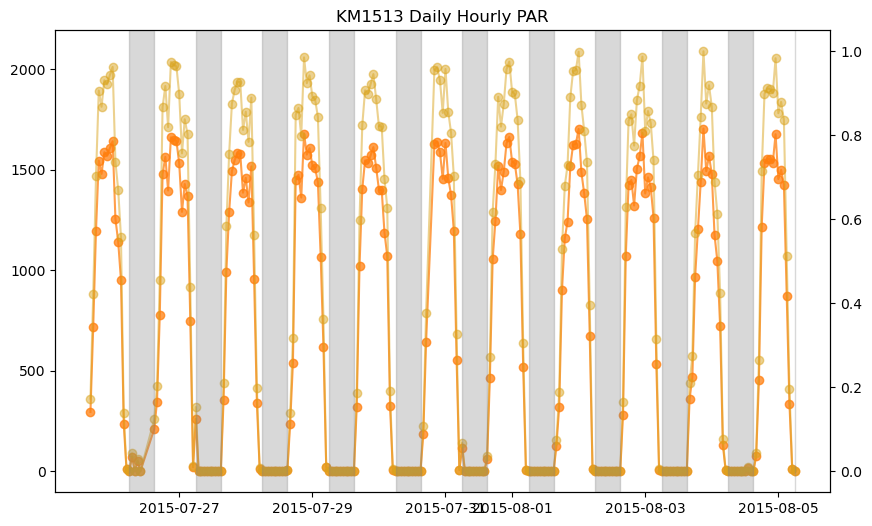

In [ ]:
# read francois cleaned data
hourly_par = pd.read_parquet('../data/SCOPE_6.hourly_par.parquet')
hourly_par.rename(columns = {'date': 'time'}, inplace = True)
# merge with time of day data
diel_cruise = hot_cruise_new.loc[hot_cruise_new['cruise'] == 'KM1513']
hourly_par = hourly_par.merge(diel_cruise[['time', 'time_of_day']].drop_duplicates())

# subset for un normalized par data
uniq_cruise = diel_cruise.drop_duplicates(subset = ['time', 'par']).reset_index()
## fix par such that there are no positive values during the night
# uniq_cruise.loc[(uniq_cruise['par'] > 0) & (uniq_cruise['time_of_day'] == 'night'), 'par'] = 0

# plot daily par and diel cycle only for 1 cruise
fig, axs = plt.subplots(figsize = (10, 6))
# plot normalized PAR
axs.plot(hourly_par['time'], hourly_par['par'], marker = 'o', c = 'tab:orange', alpha = 0.75)
# plot un normalized PAR
axs.plot(uniq_cruise['time'], uniq_cruise['par'], marker = 'o', c = 'goldenrod', alpha = 0.5)
# plot day night cycle
twinax = axs.twinx()
twinax.fill_between(uniq_cruise['time'], 0, 1, where=uniq_cruise['time_of_day'] == 'night',color='gray', alpha=0.3,
                         transform=axs.get_xaxis_transform())
axs.set_title("KM1513 Daily Hourly PAR")

Replot Diel cruise growth curves for Pro

In [ ]:
# merge with df with MLD and diel data
sub_hourly_par = hourly_par[['time', 'time_of_day', 'par']]
sub_hourly_par.rename(columns = {'par': 'norm_par'}, inplace = True)
# subset the diel cruise
cruise = 'KM1513'
pop = 'prochloro'
cruise_df = smooth_mld.loc[(smooth_mld['pop'] == pop) & 
                           (smooth_mld['cruise'] == cruise)].reset_index(drop = True)
cruise_df = cruise_df.merge(sub_hourly_par, how = 'left')
## calculate normalized integrated par
# convert from hour -> seconds
temp_df = cruise_df.copy()
temp_df['norm_hourly_par'] = temp_df['norm_par'] * 3600
cruise_df['int_norm_par'] = temp_df.groupby('cruise_day')['norm_hourly_par'].cumsum()
max_df = cruise_df.groupby(['cruise_day']).max().reset_index()

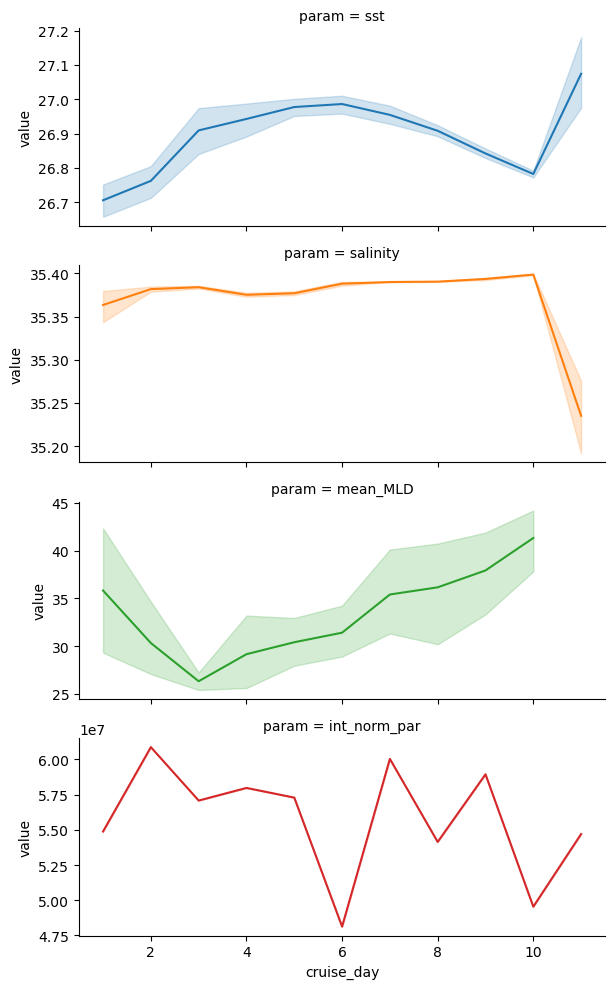

In [ ]:
# subset just diel cruise and necessary cols
diel_cruise = smooth_mld.loc[smooth_mld['cruise'] == 'KM1513']
sub_diel = diel_cruise[['cruise_day', 'pop', 'time', 'time_of_day', 'day_hour']]
sst_salt = diel_cruise[['cruise_day', 'day_hour', 'sst', 'salinity', 'mean_MLD']]
# add integrated par to dataset
sst_salt = sst_salt.merge(max_df[['cruise_day', 'int_norm_par']])
# change from wide to long
sst_long = pd.melt(sst_salt, id_vars = ['cruise_day', 'day_hour'], 
        value_vars = ['sst', 'salinity', 'mean_MLD', 'int_norm_par'],
        var_name = 'param',
        value_name = 'value')
# plot each variable as a facet grid
g = sns.FacetGrid(sst_long, row="param", hue = 'param', 
                  height = 2.5, aspect = 2.5, sharey = False)
g.map(sns.lineplot, 'cruise_day', 'value')

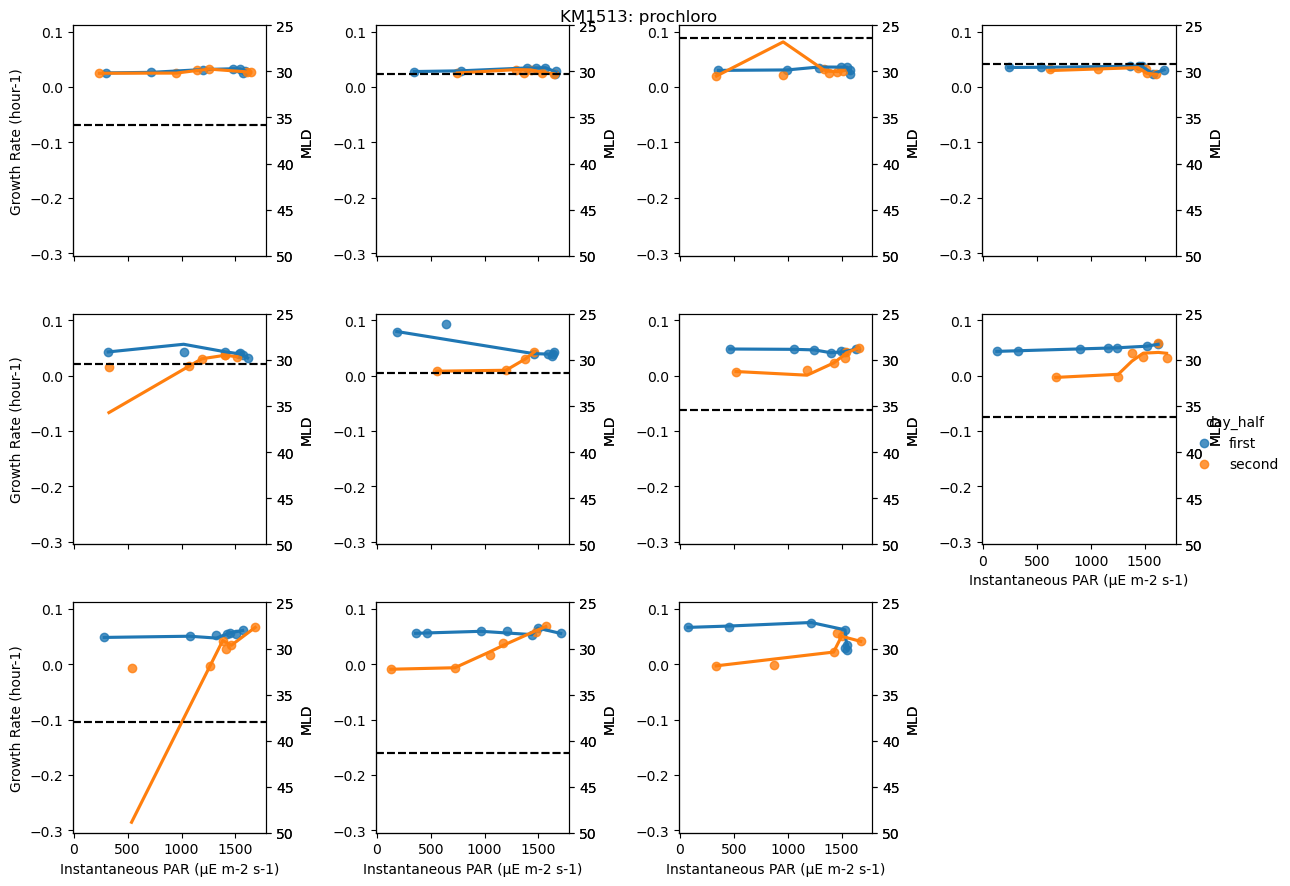

In [ ]:
# calculate growth rate
daily_pe = create_growth_df(cruise_df, id_part1 = id_counter)
# remove all days where no par data
daily_pe = daily_pe.loc[daily_pe['par'].notnull()]
# add a column for cruise and season
daily_pe['cruise'] = cruise
daily_pe['season'] = season
# color code the first and second half of each day
daily_pe['day_half'] = np.where(daily_pe['hour'] <= 6, 'first', 'second')
# add normalized
daily_pe = daily_pe.merge(cruise_df[['cruise_day', 'day_hour', 'norm_par']], 
               right_on=['cruise_day', 'day_hour'],
               left_on = ['cruise_day', 'hour'])
# plot
g = sns.FacetGrid(daily_pe, col="cruise_day", hue = 'day_half', col_wrap = 4)
g.map(sns.regplot, 'norm_par', 'slope', lowess=True)
# plot mean MLD
g.map_dataframe(add_mean_line)
# remove subplot titles
g.set_titles("")
# g.set(xlim = (-100, 2500))
# set cruise title
g.figure.suptitle(f'{cruise}: {pop}')
g.set_axis_labels("Instantaneous PAR (µE m-2 s-1)", "Growth Rate (hour-1)")
g.add_legend()

### Let's look at the PSD over time

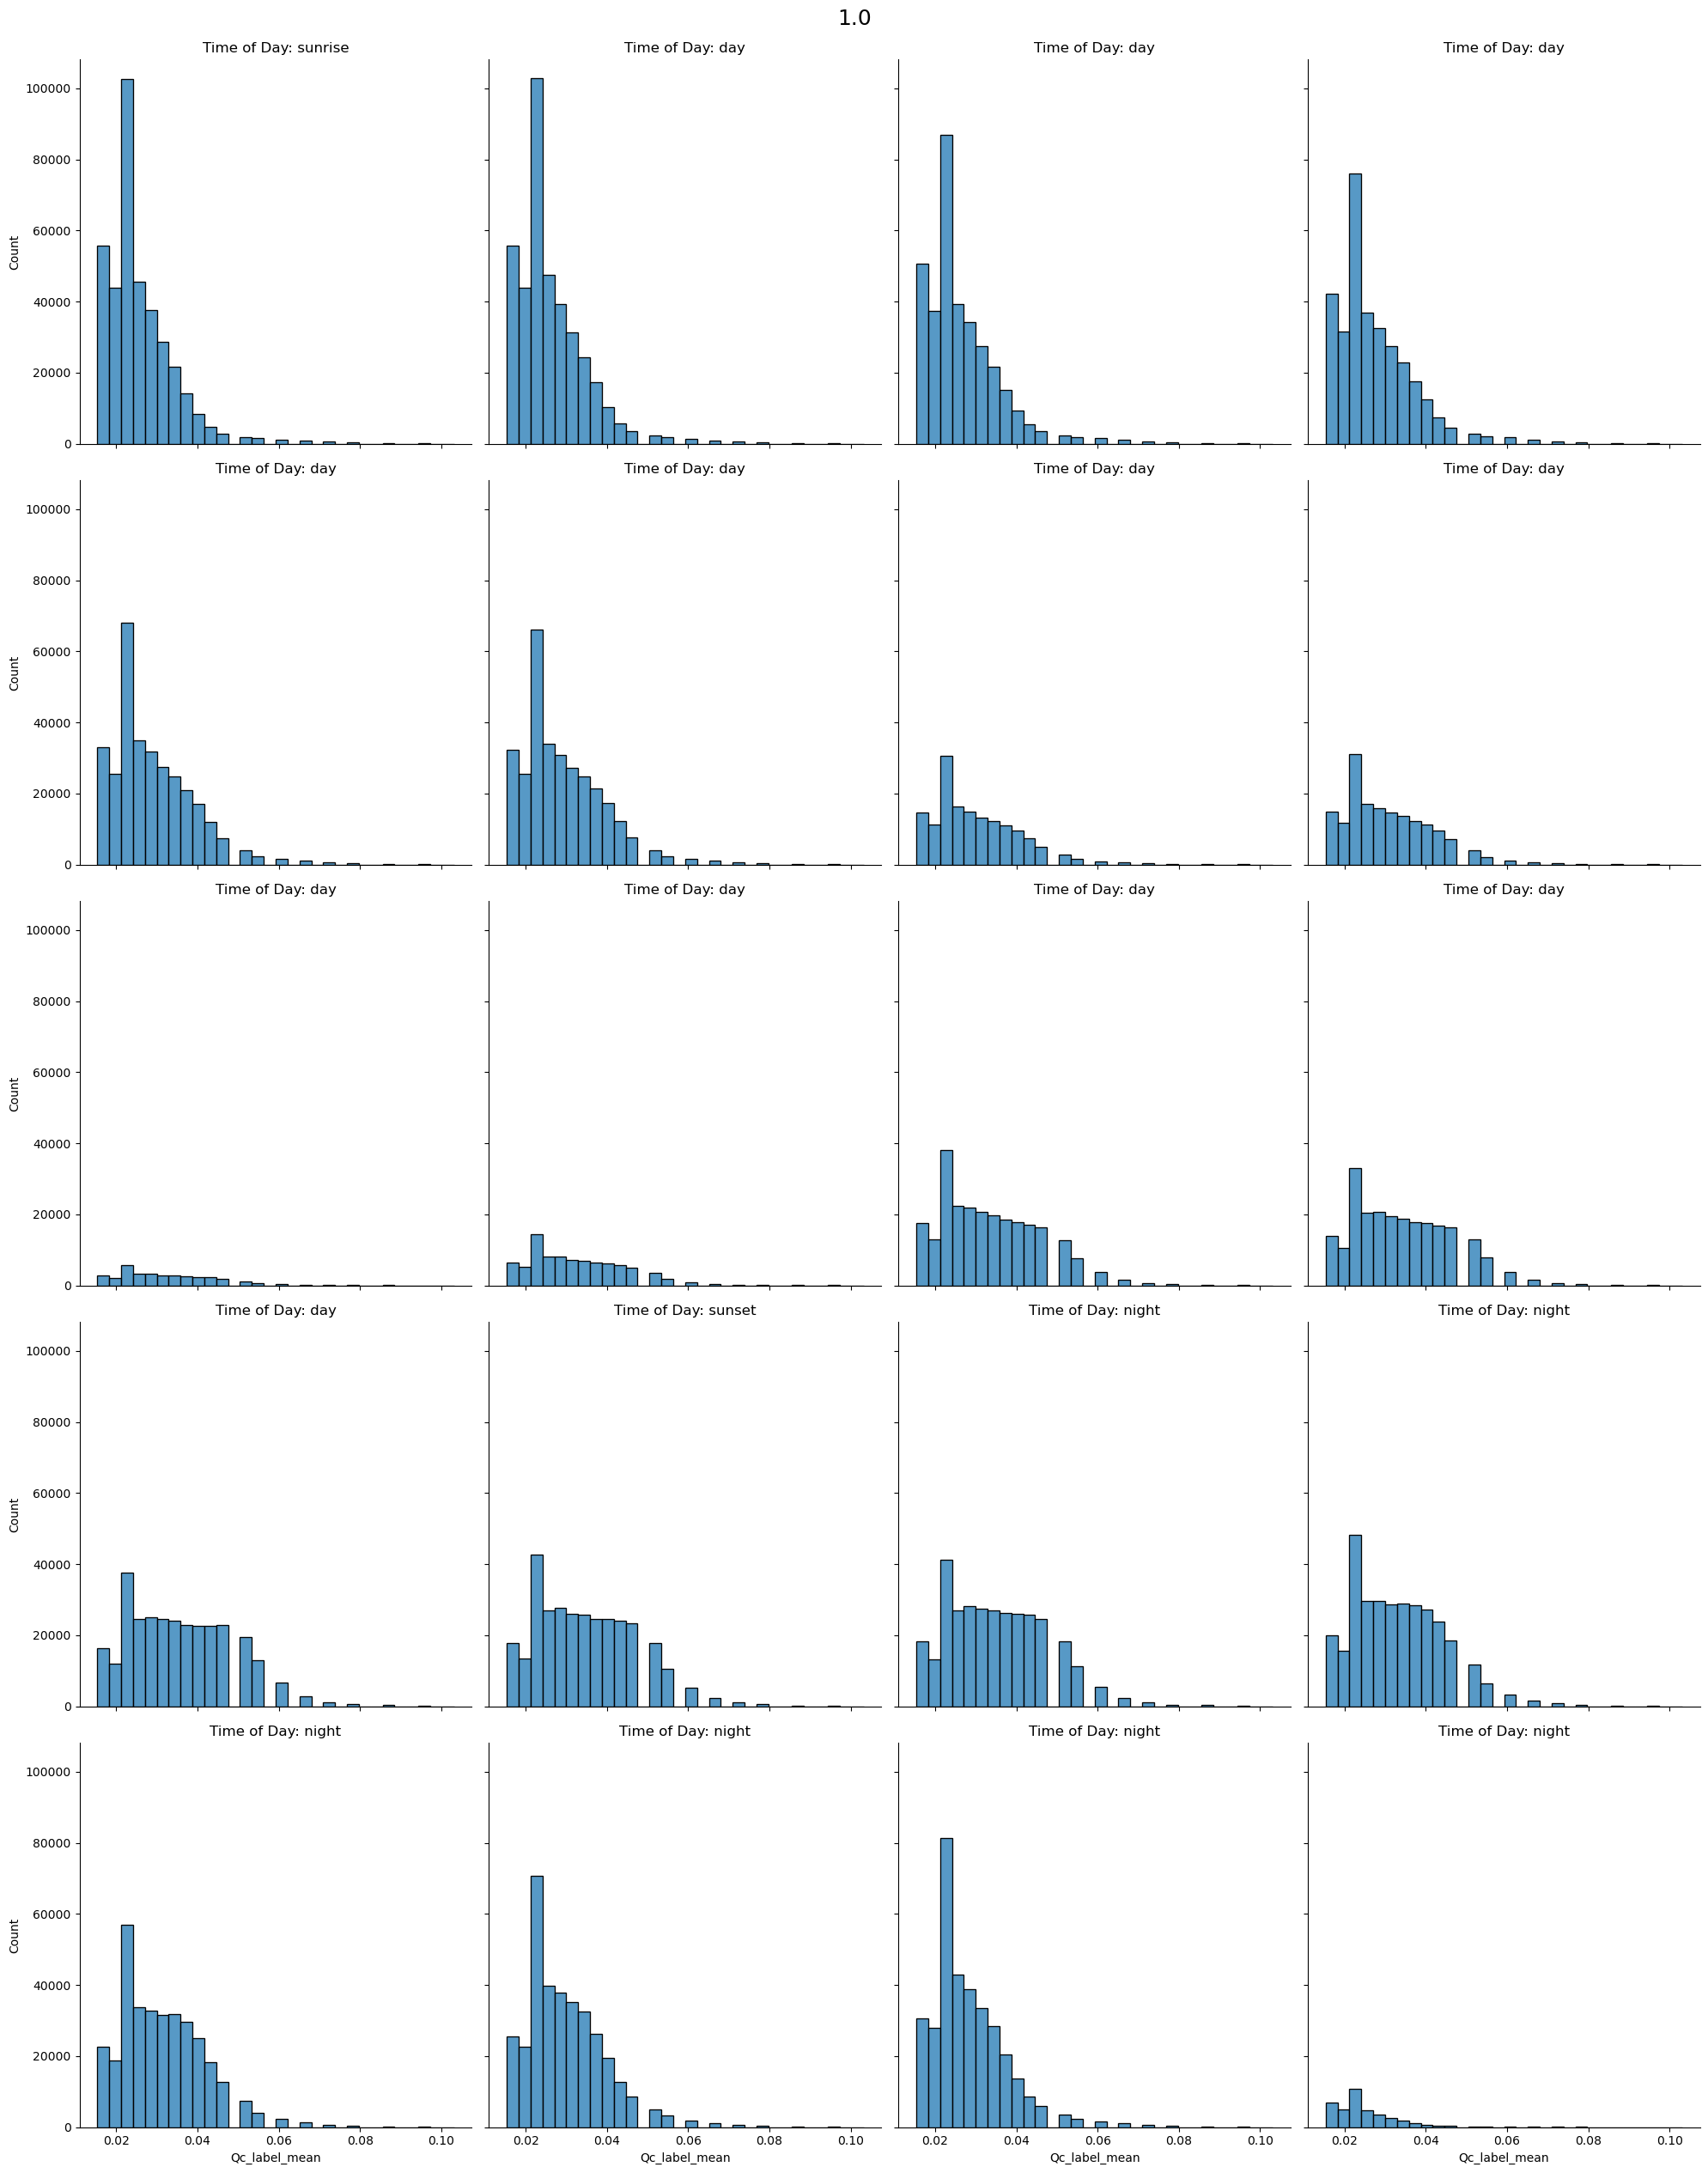

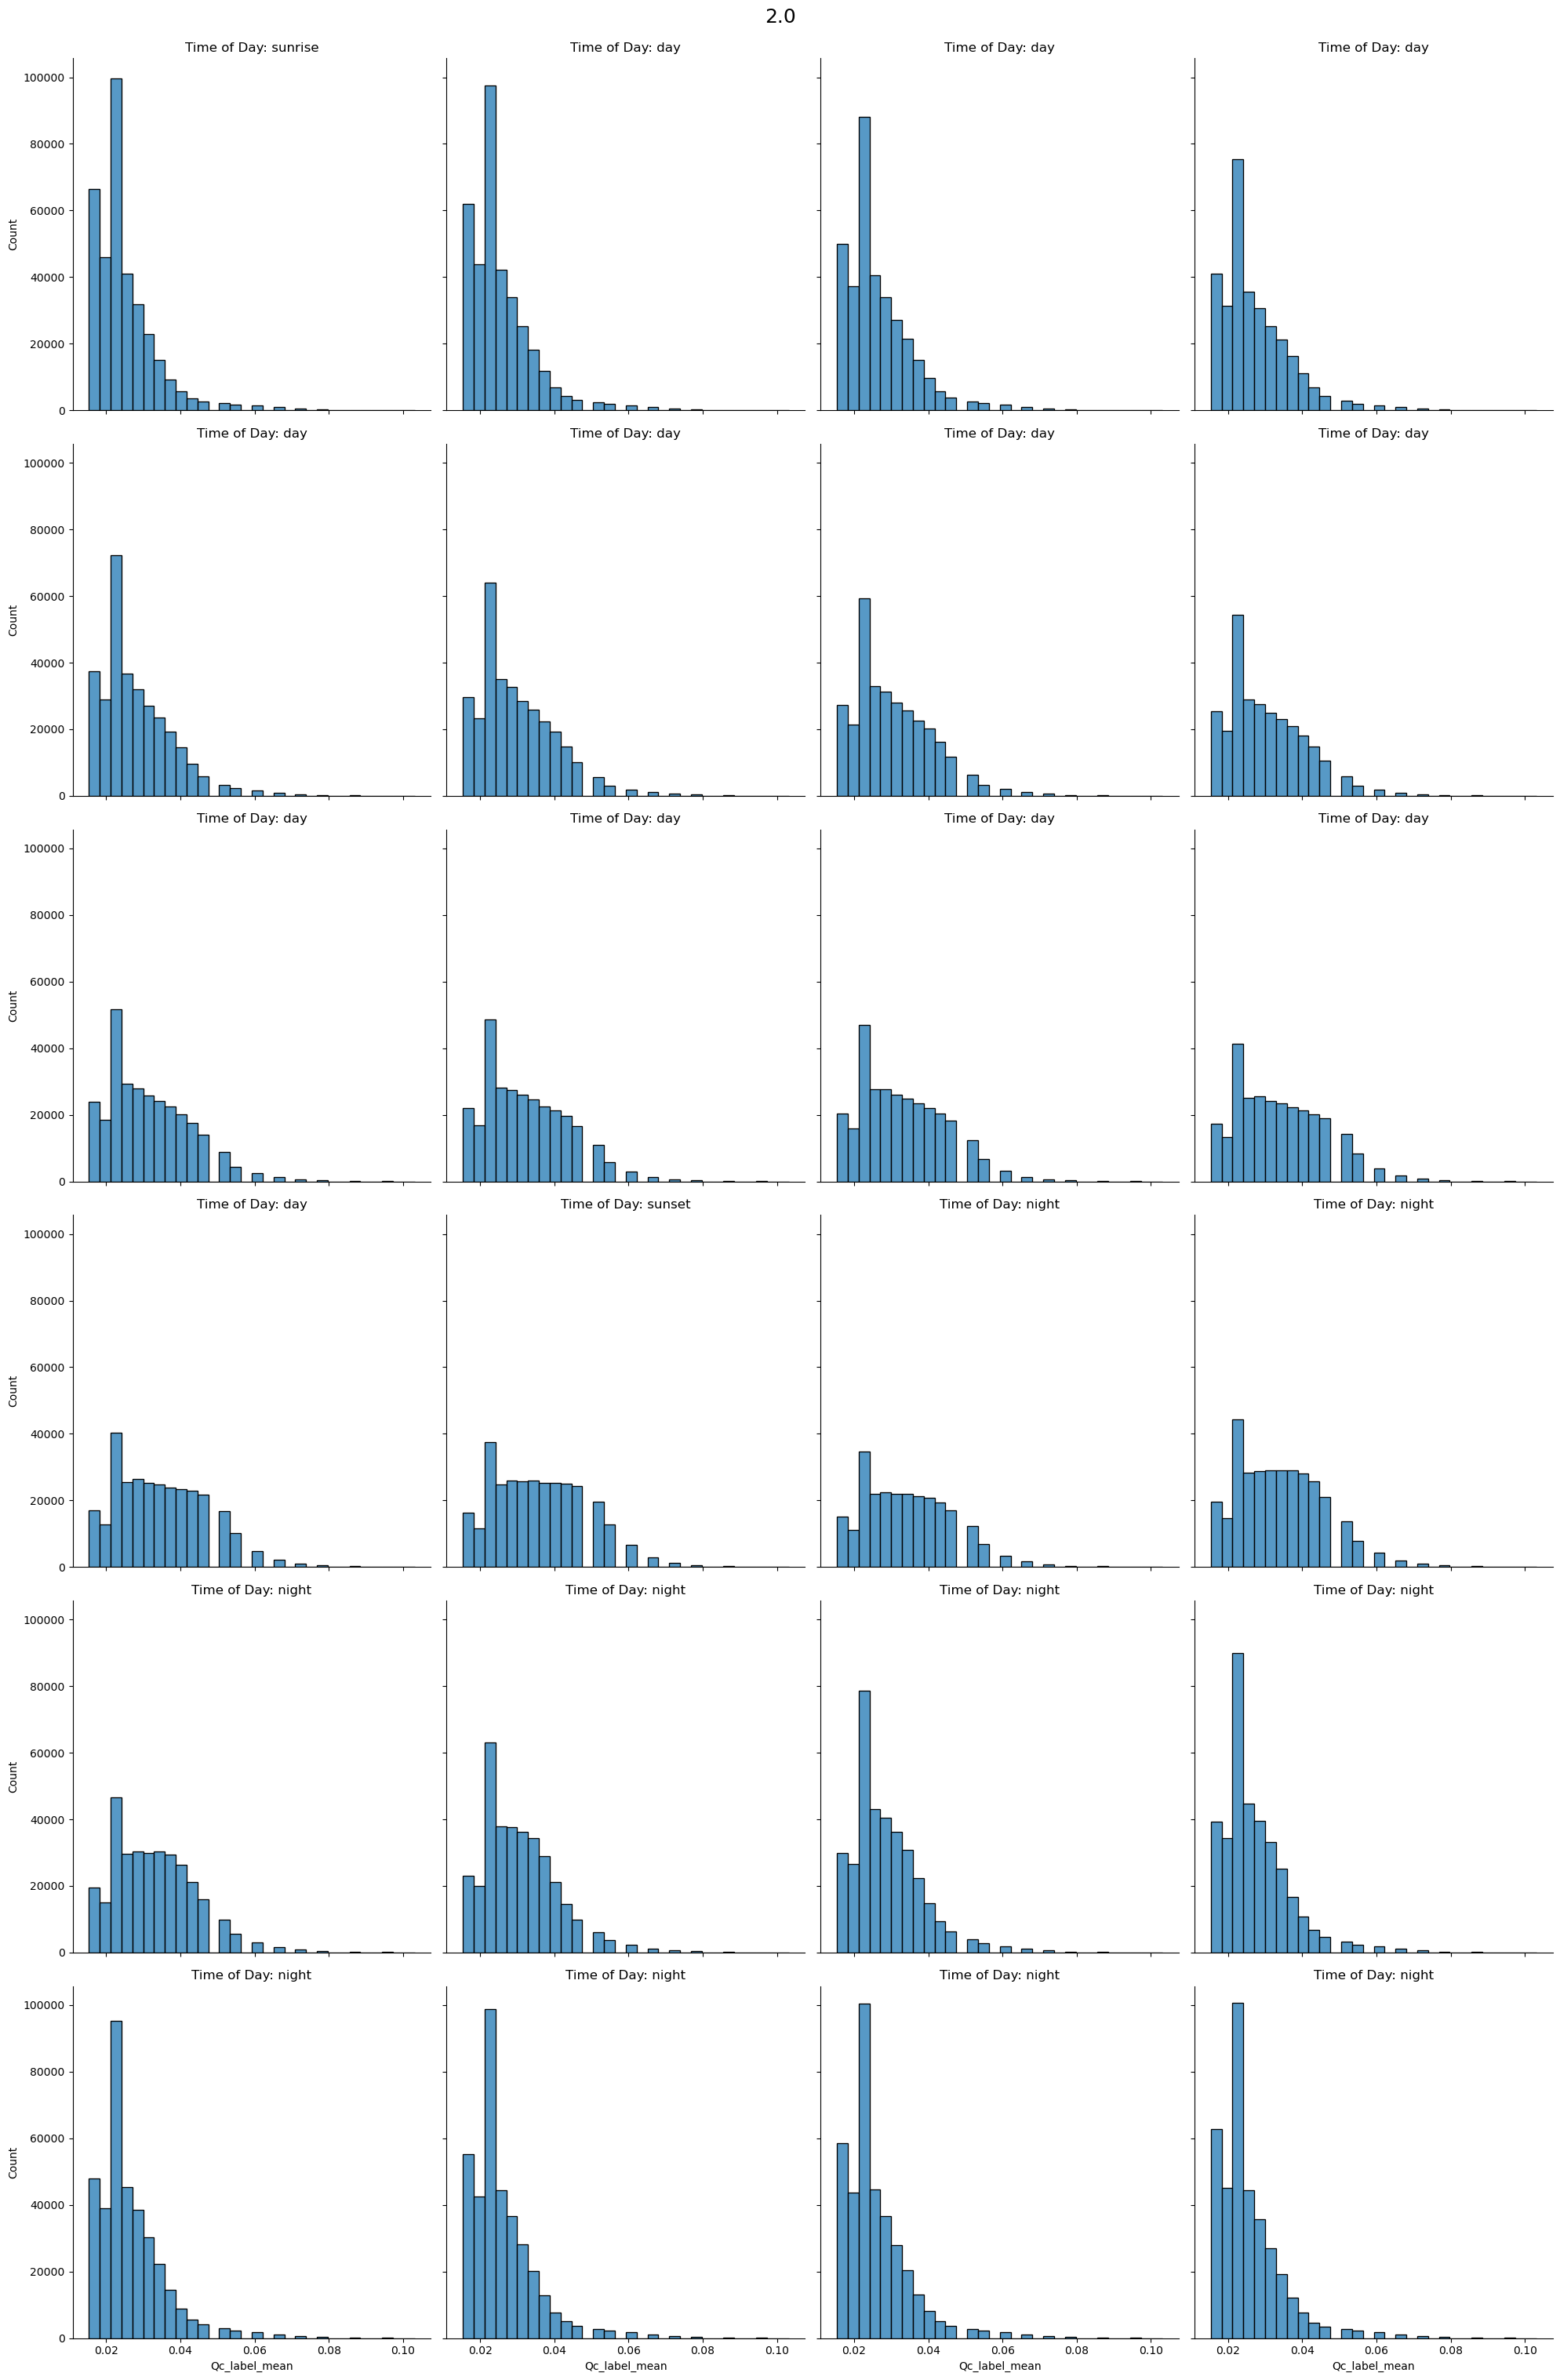

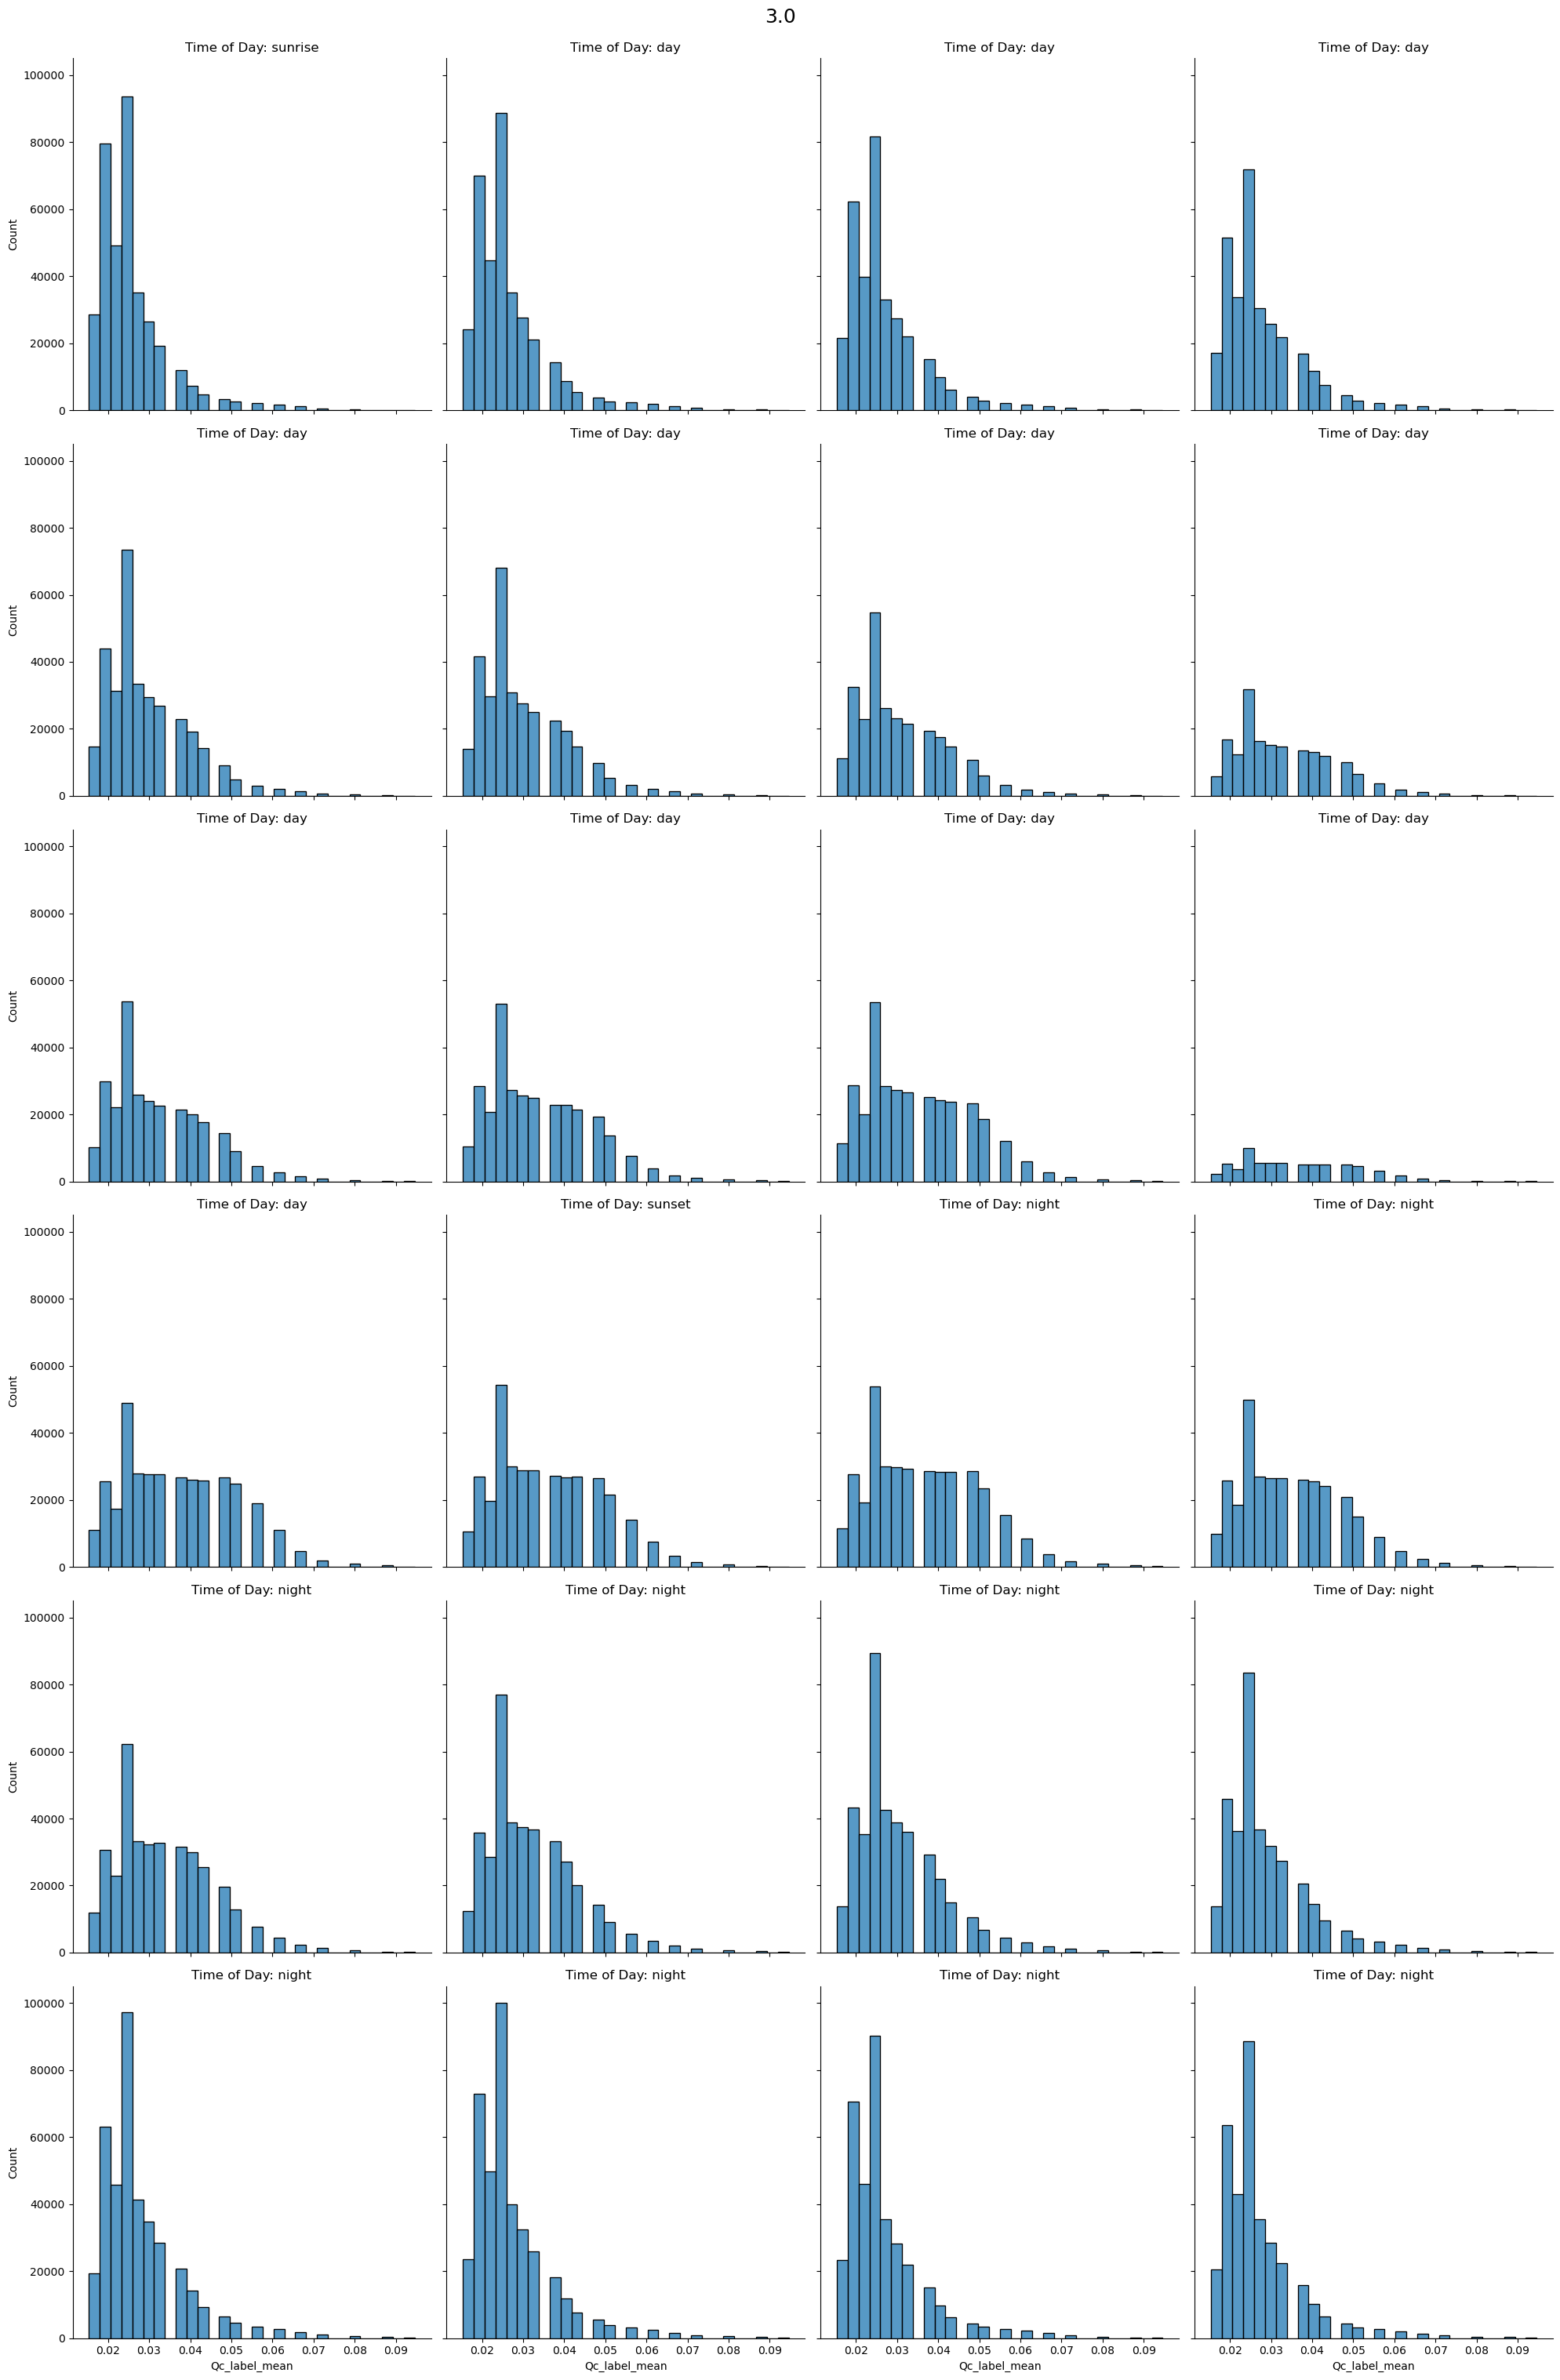

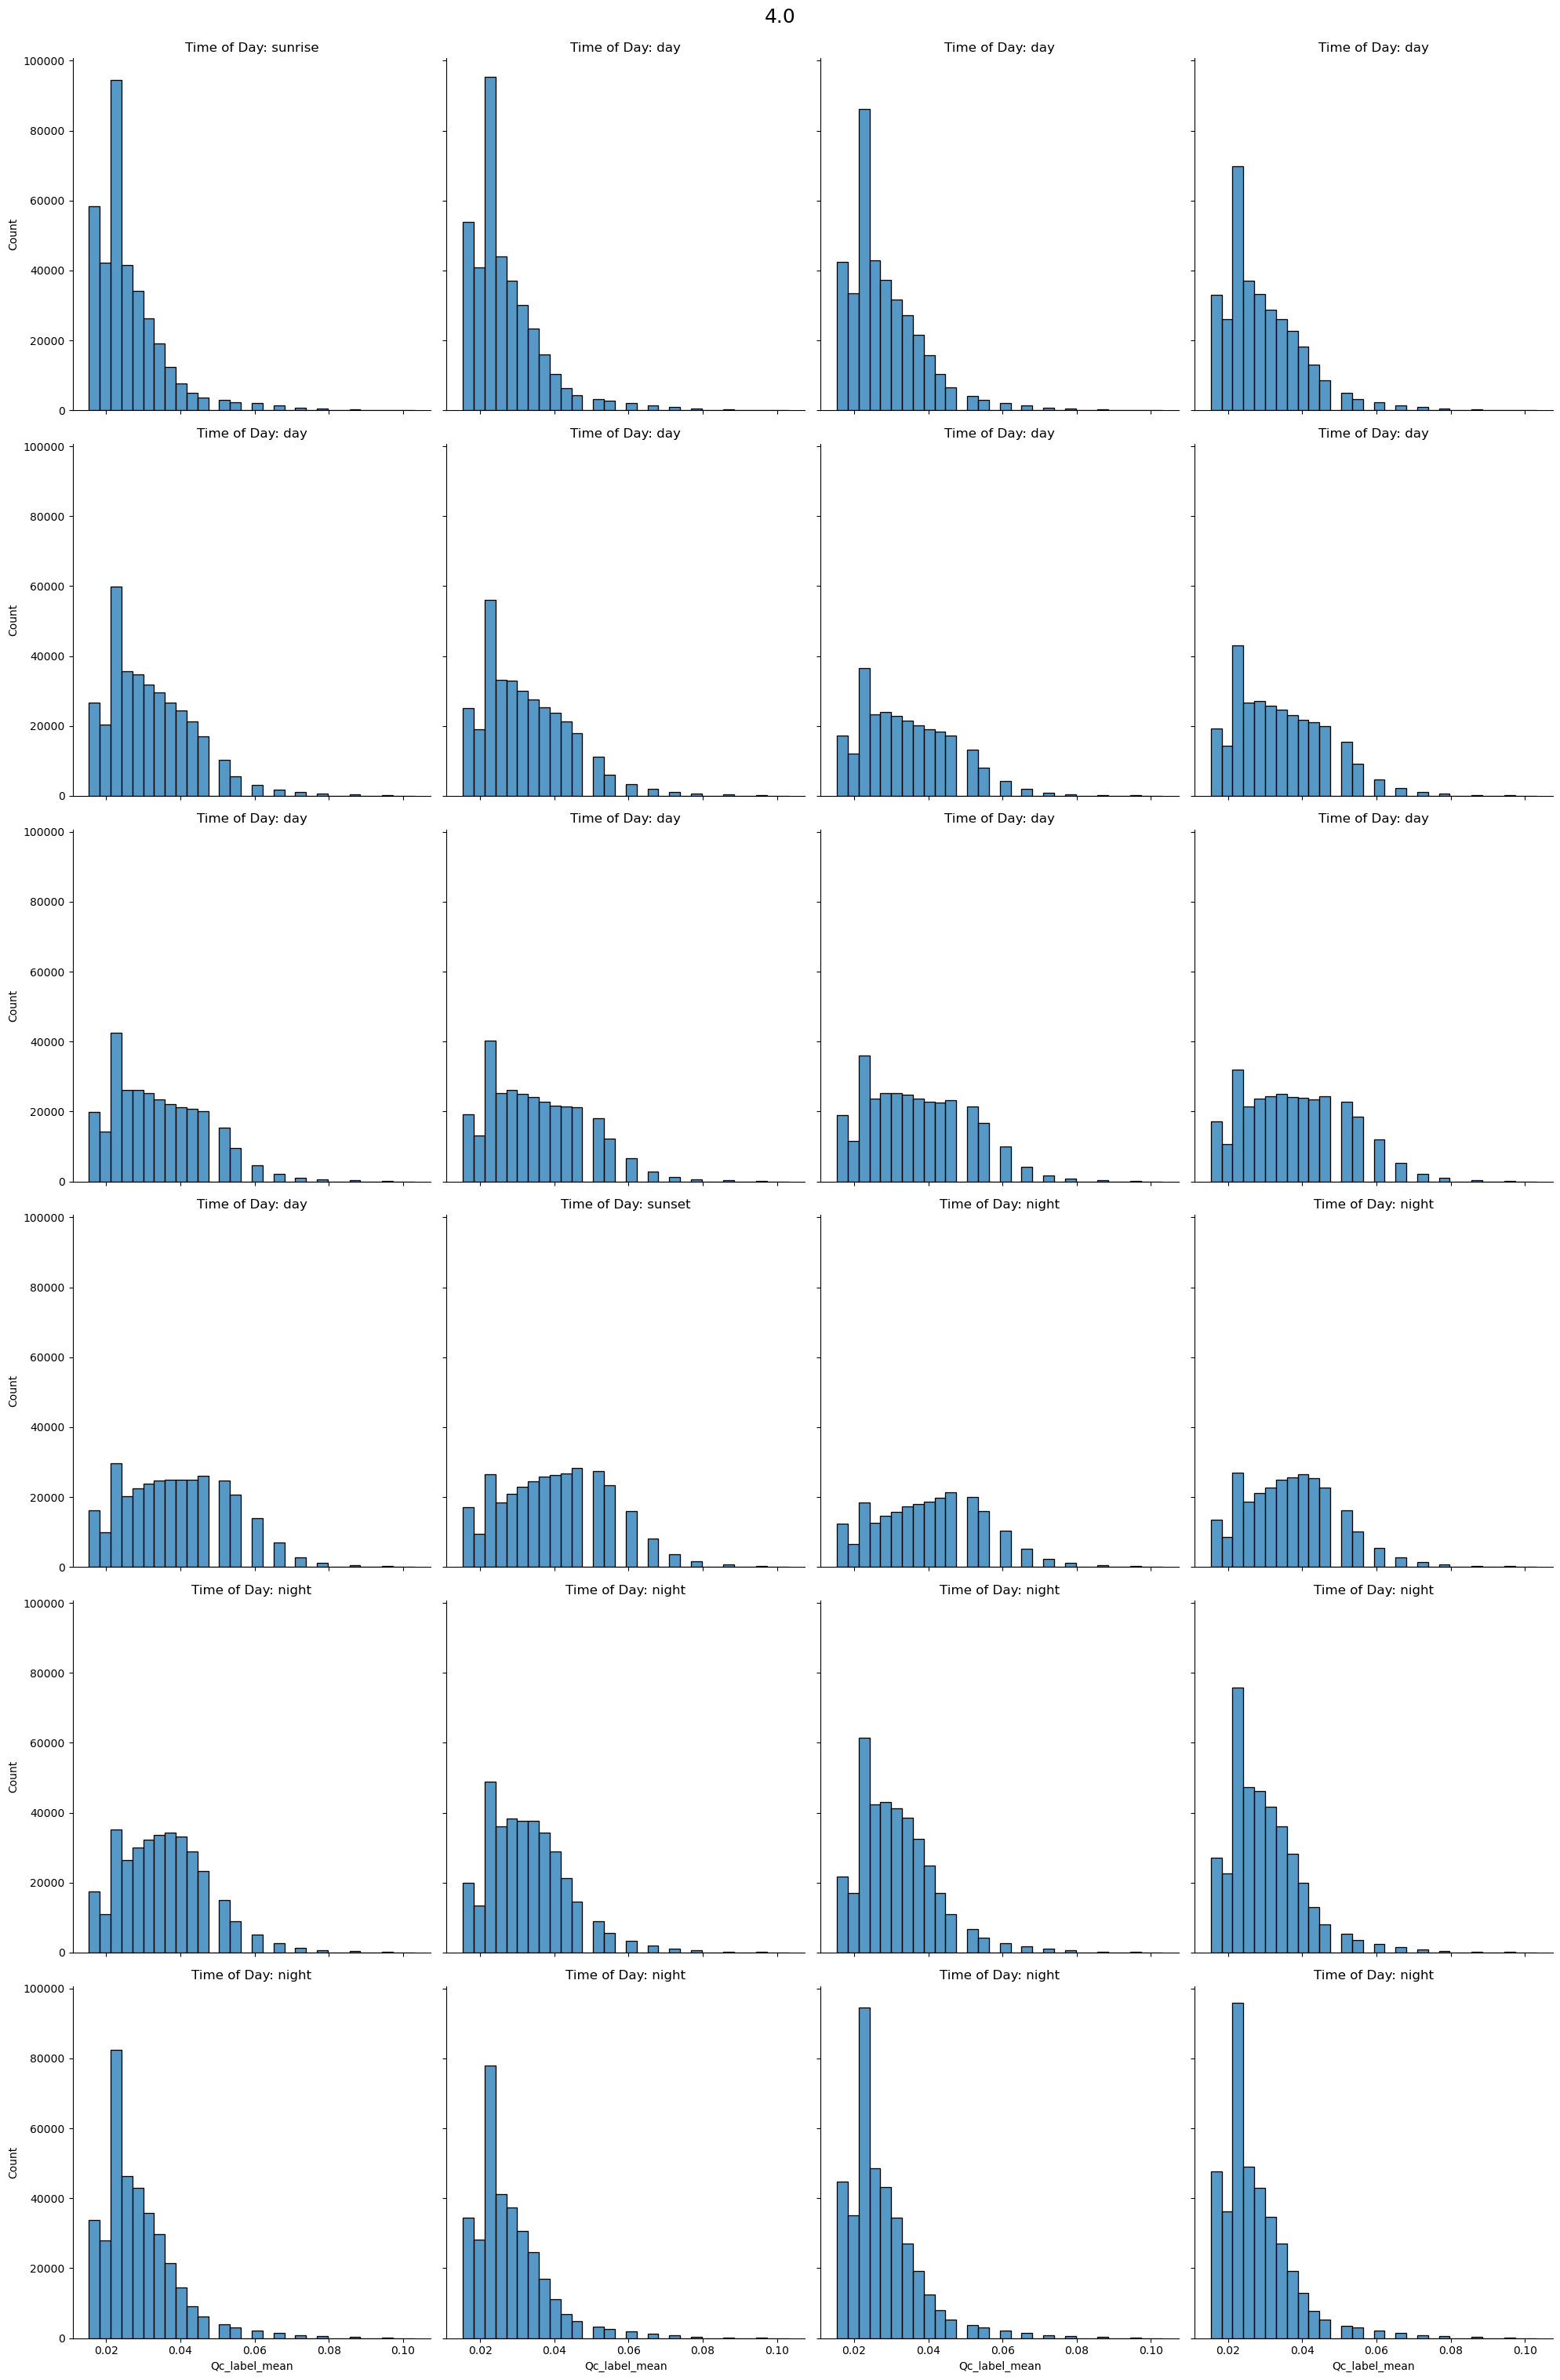

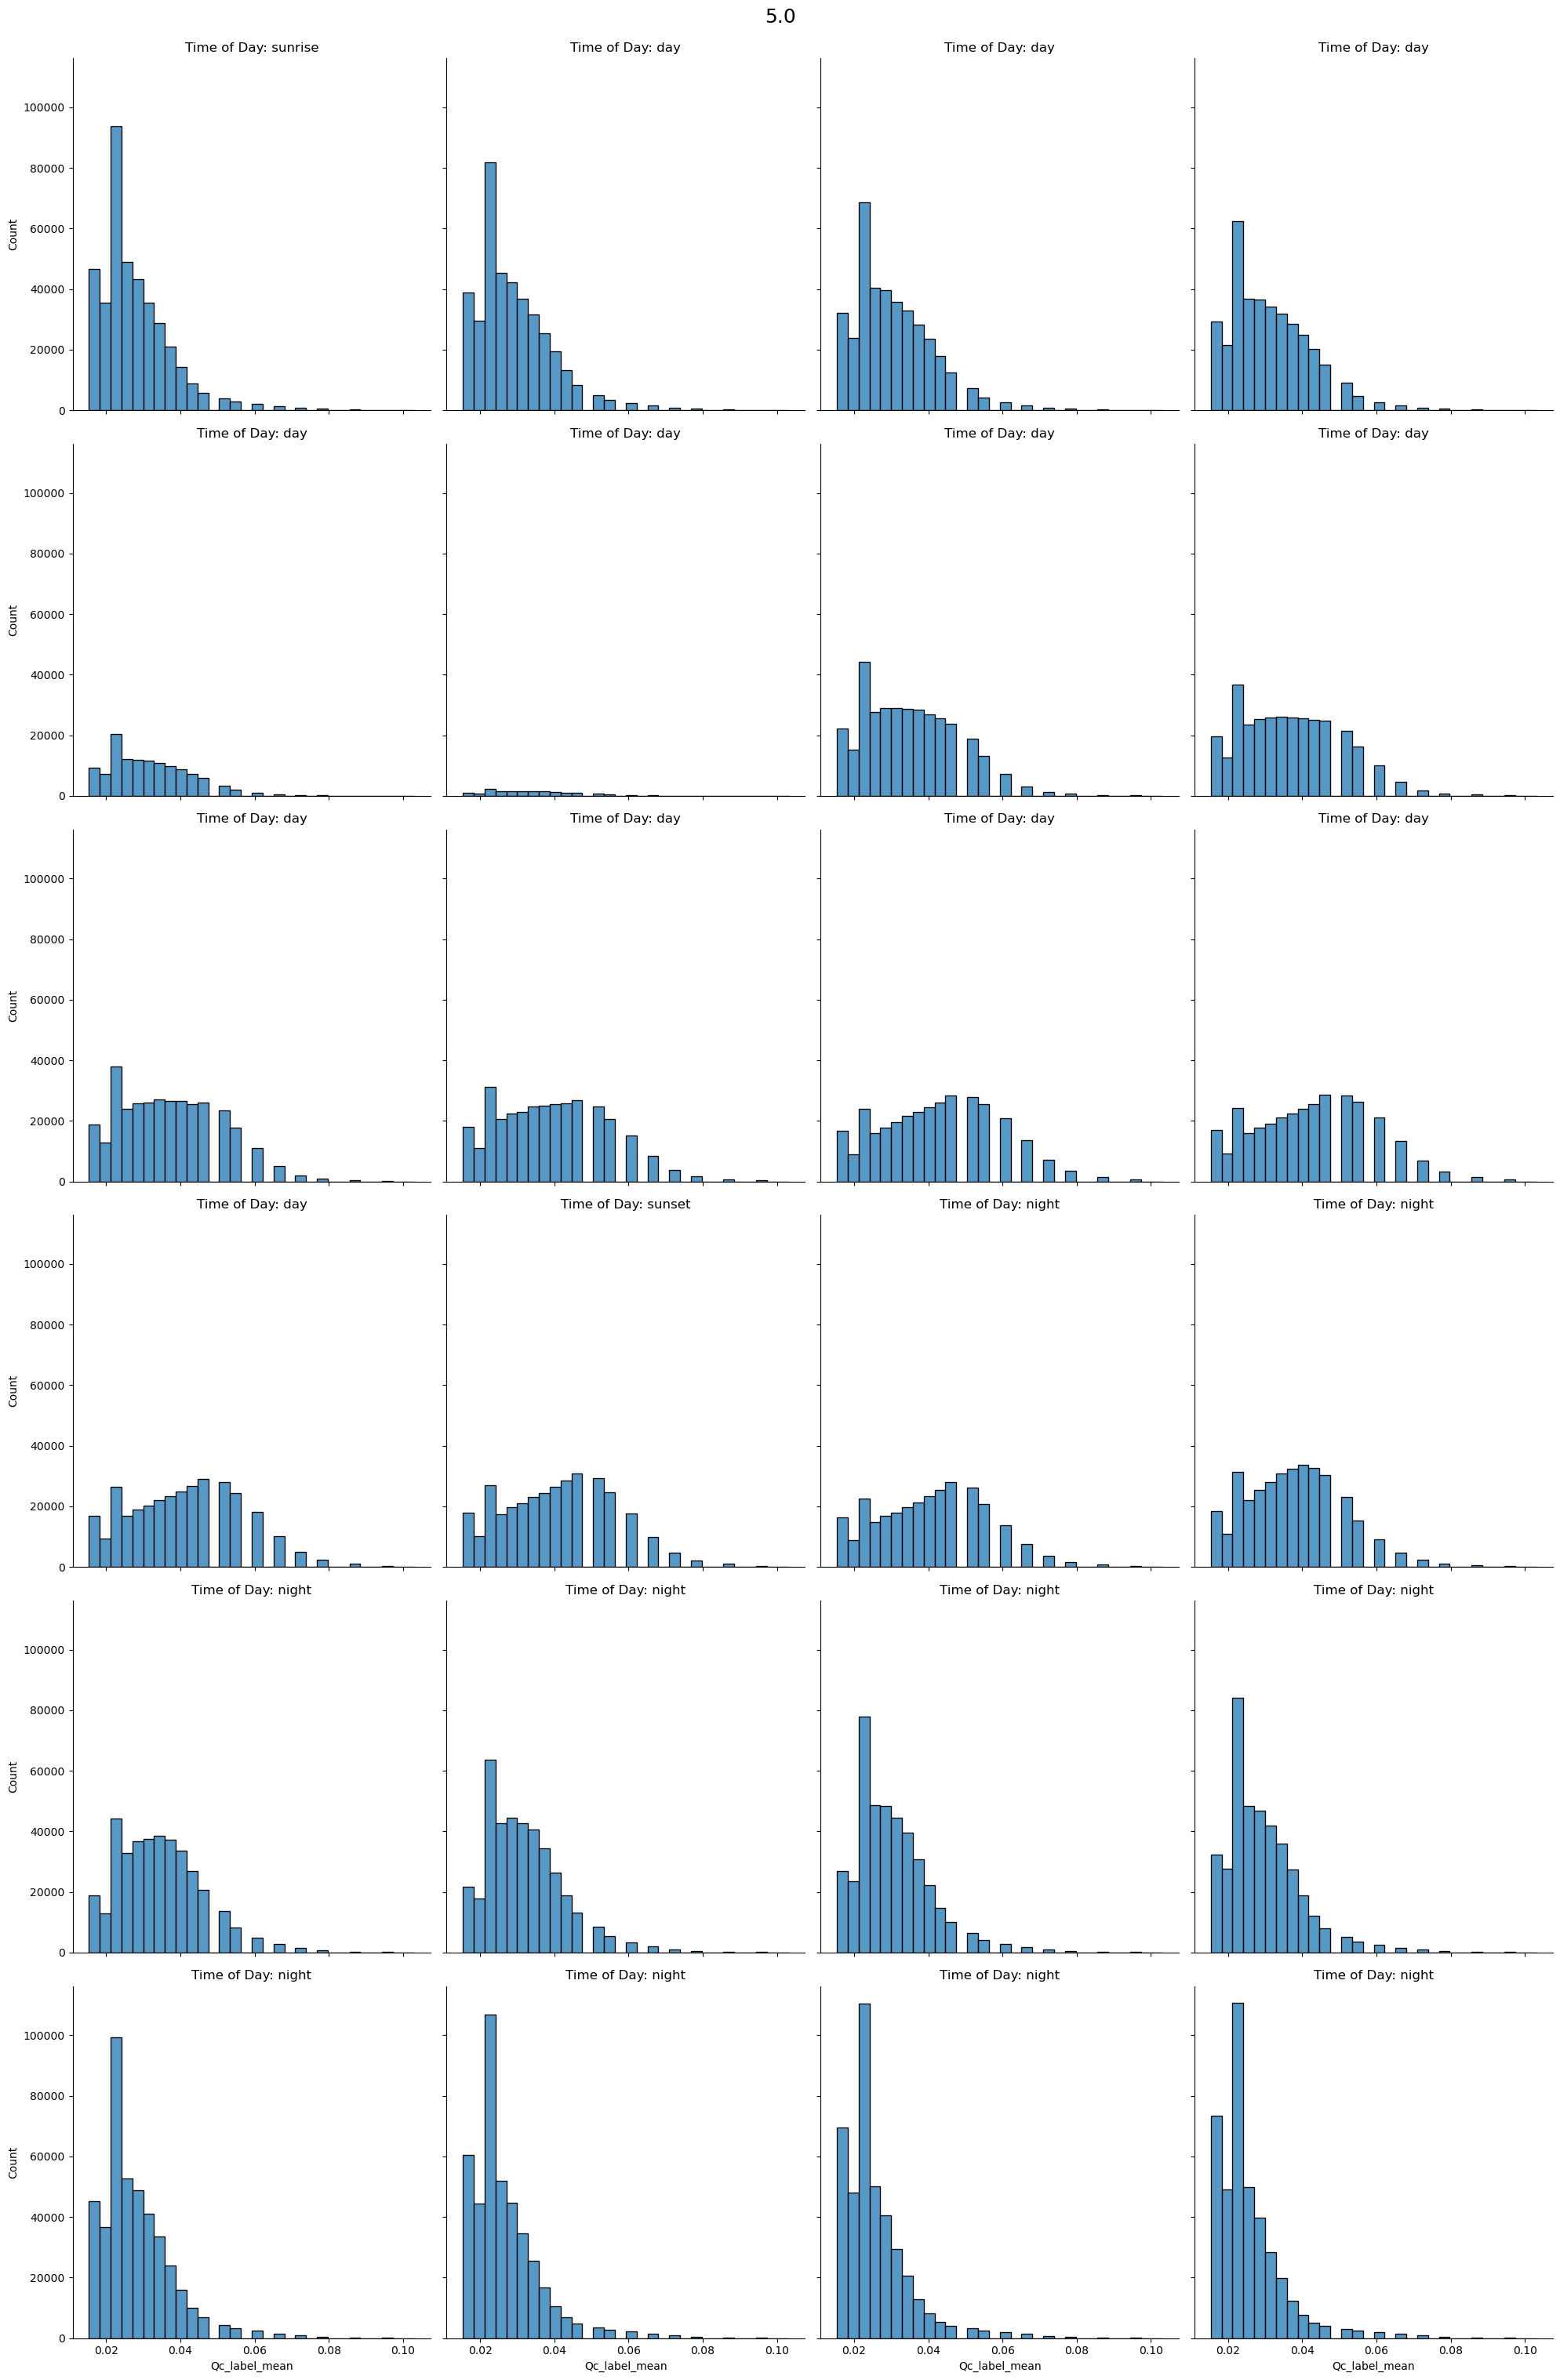

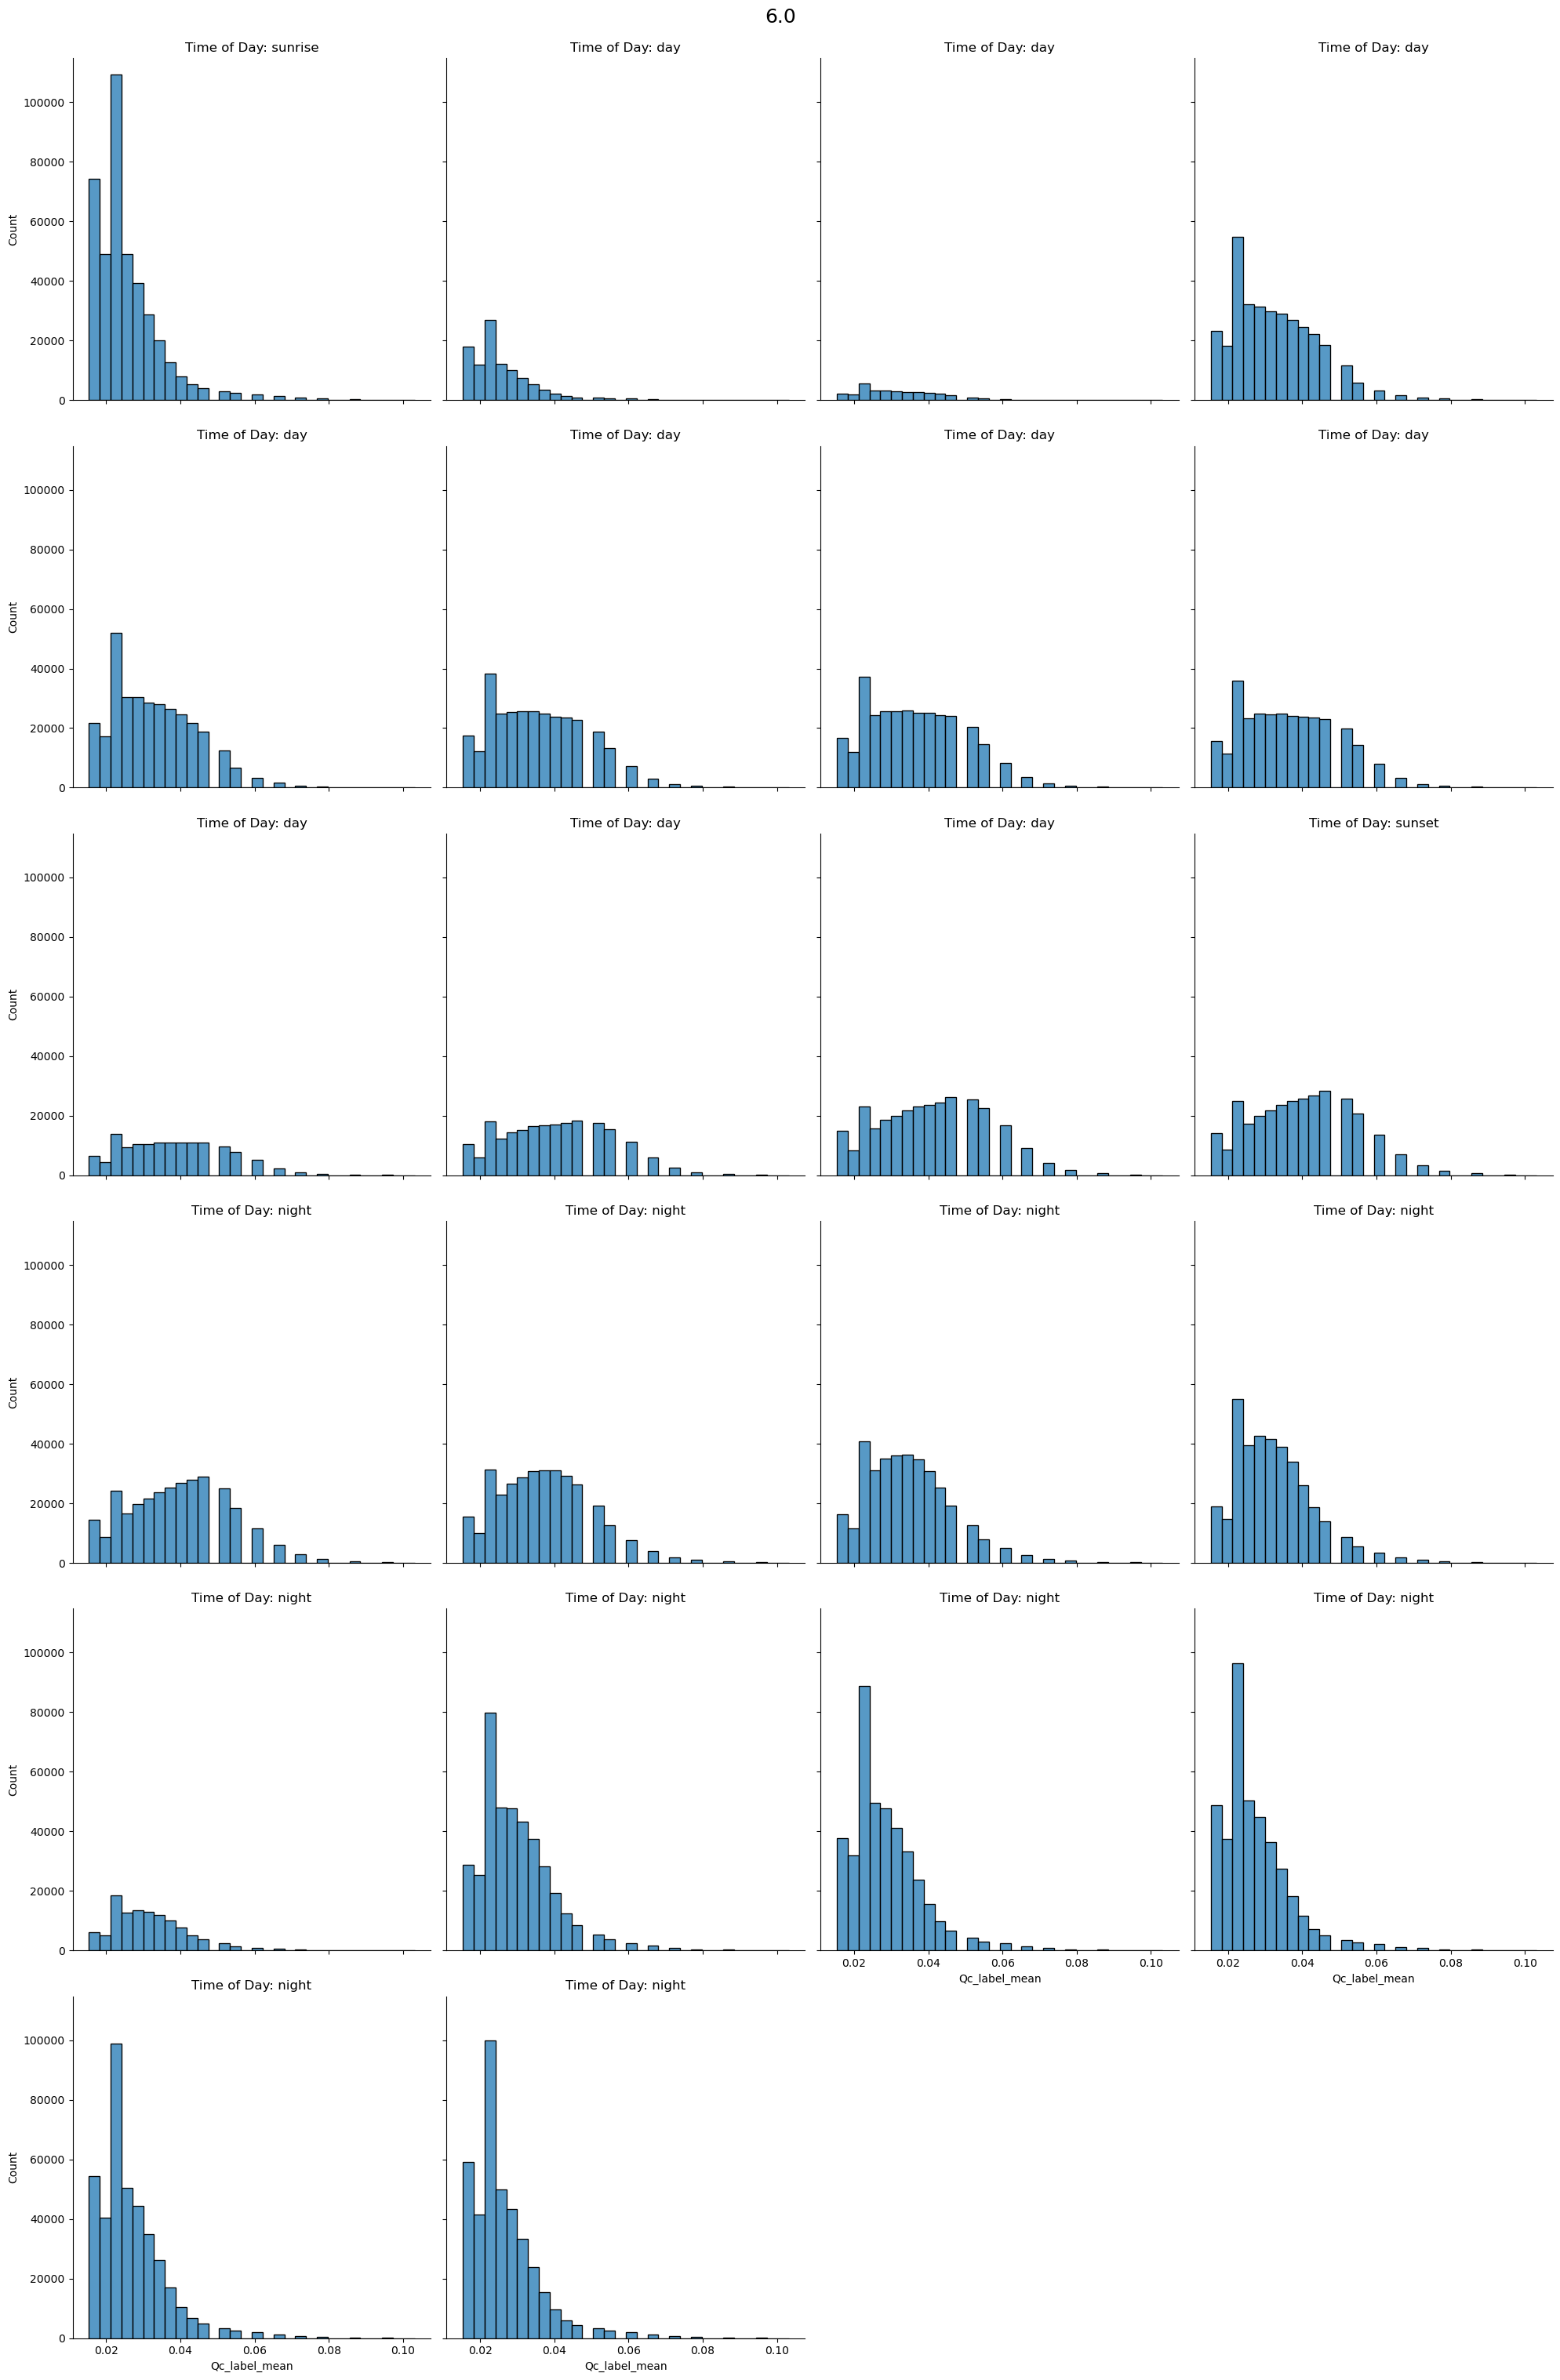

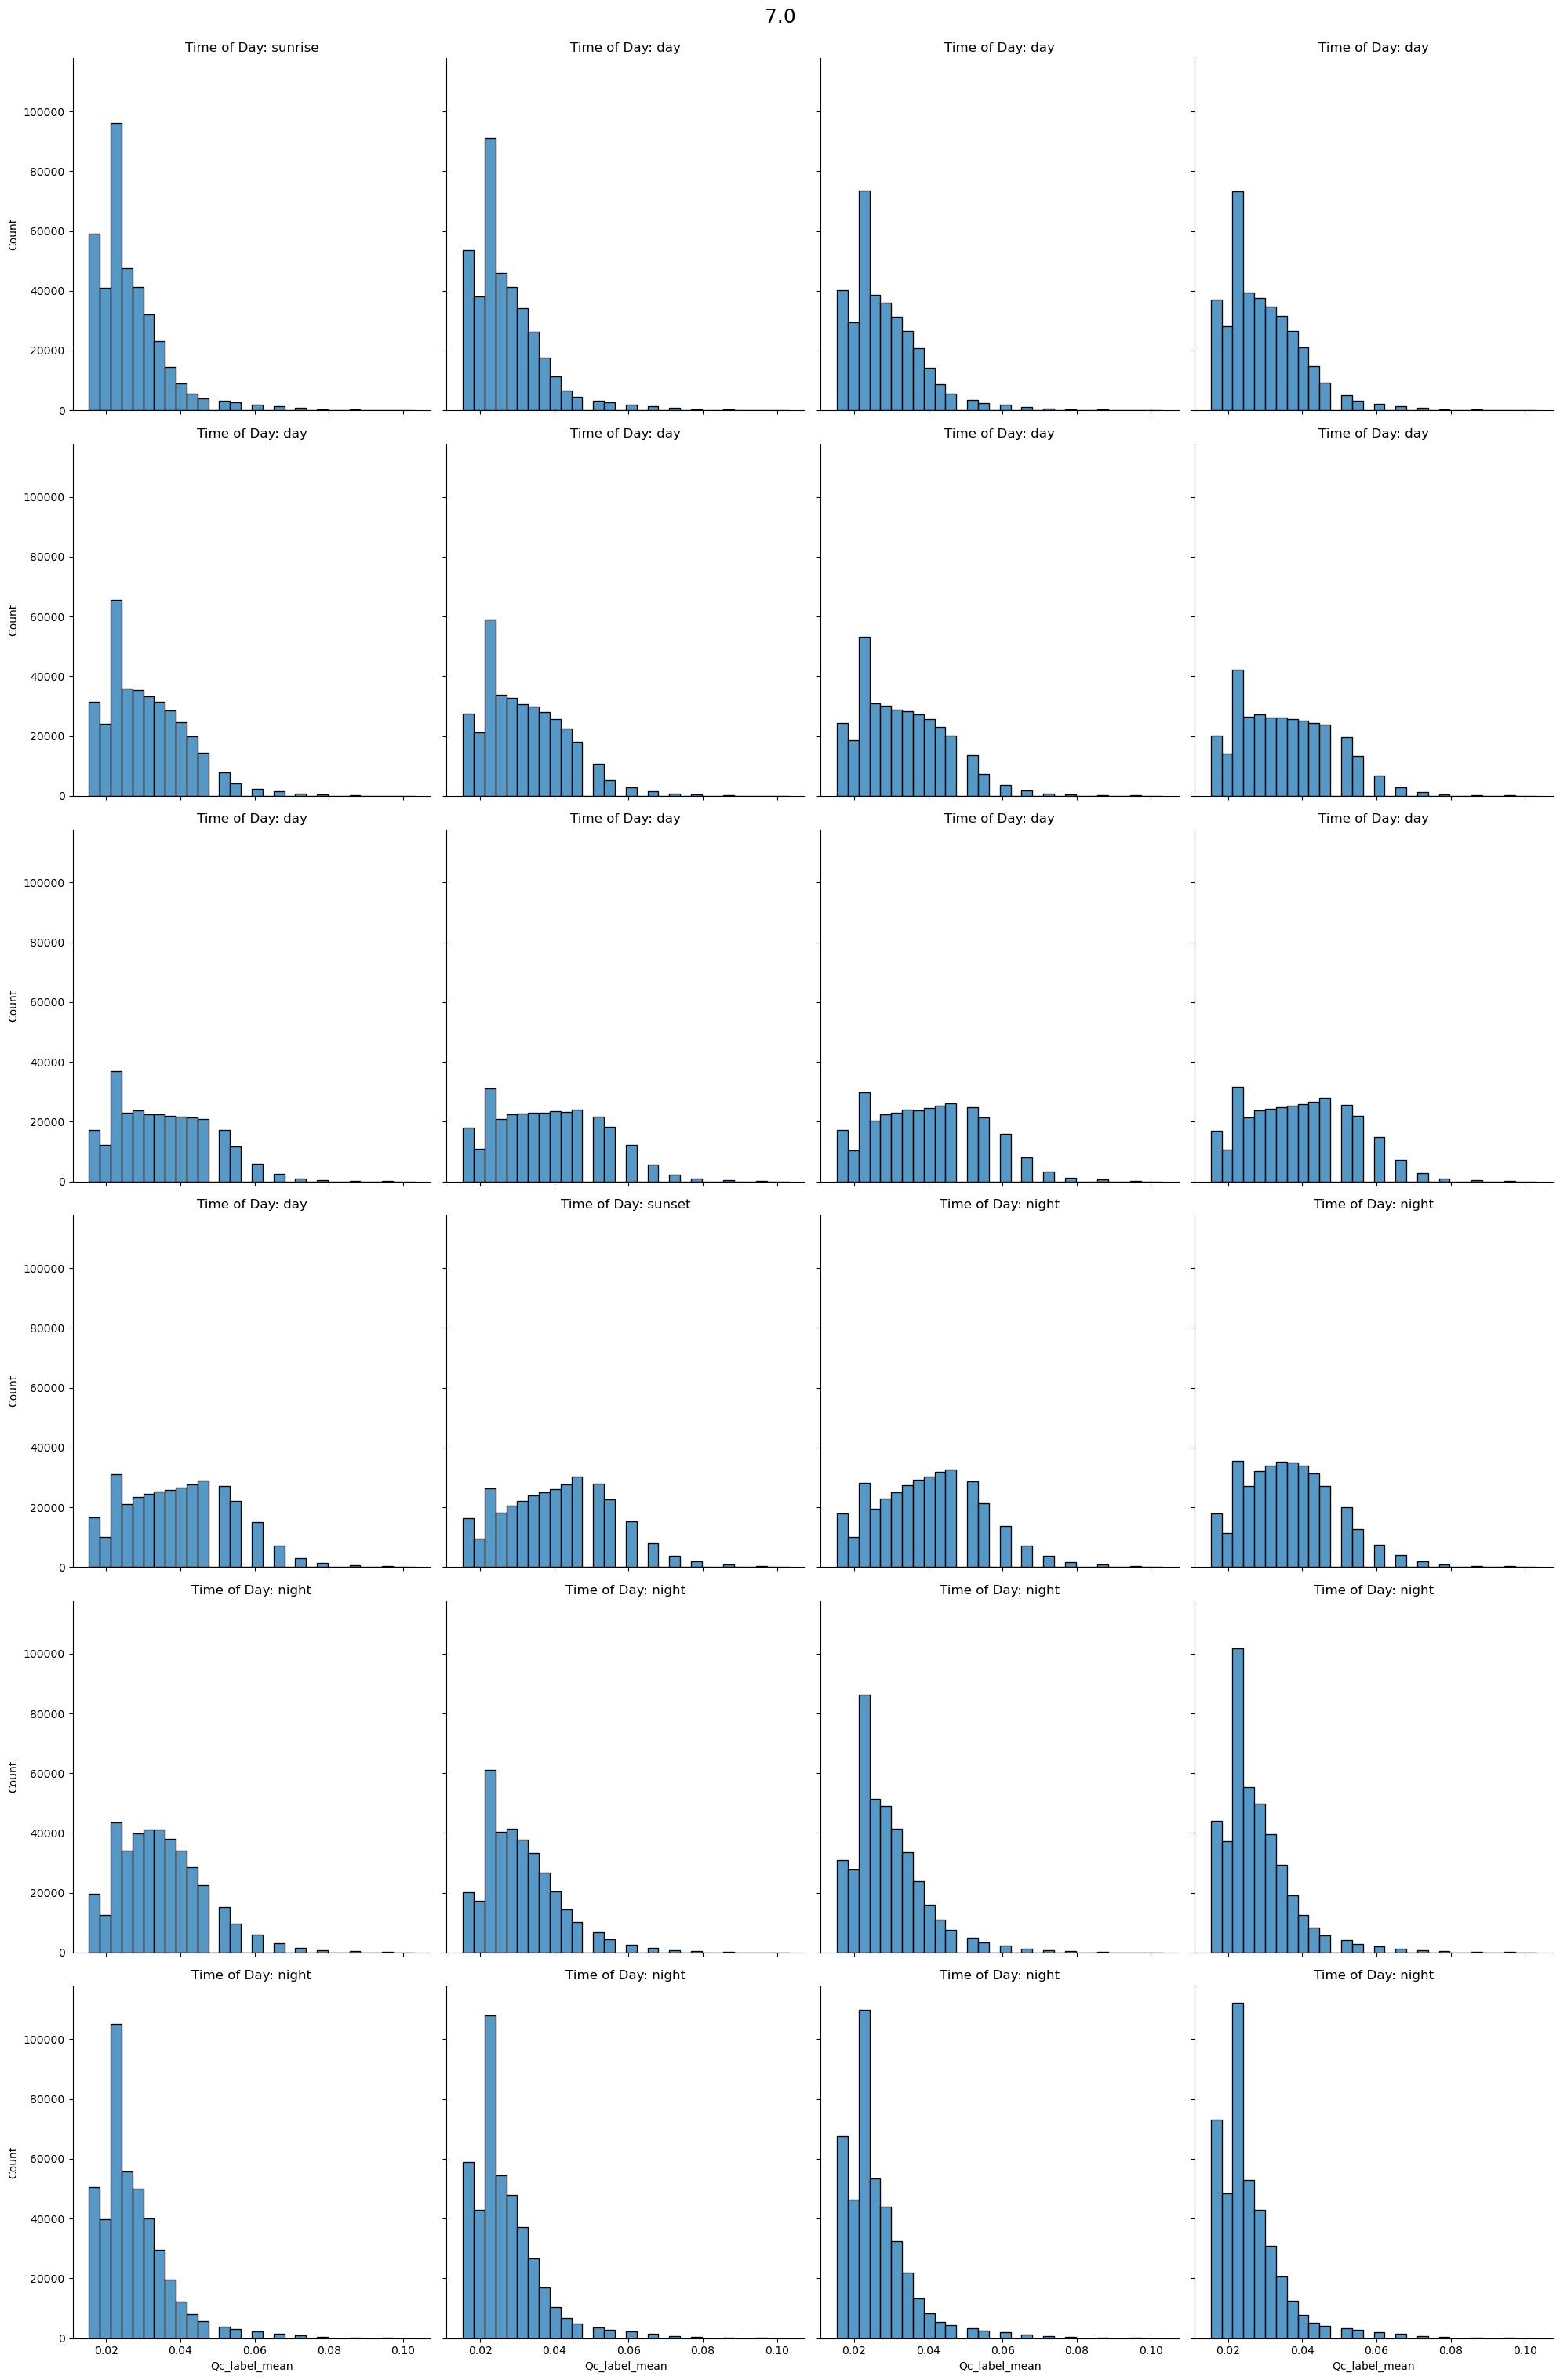

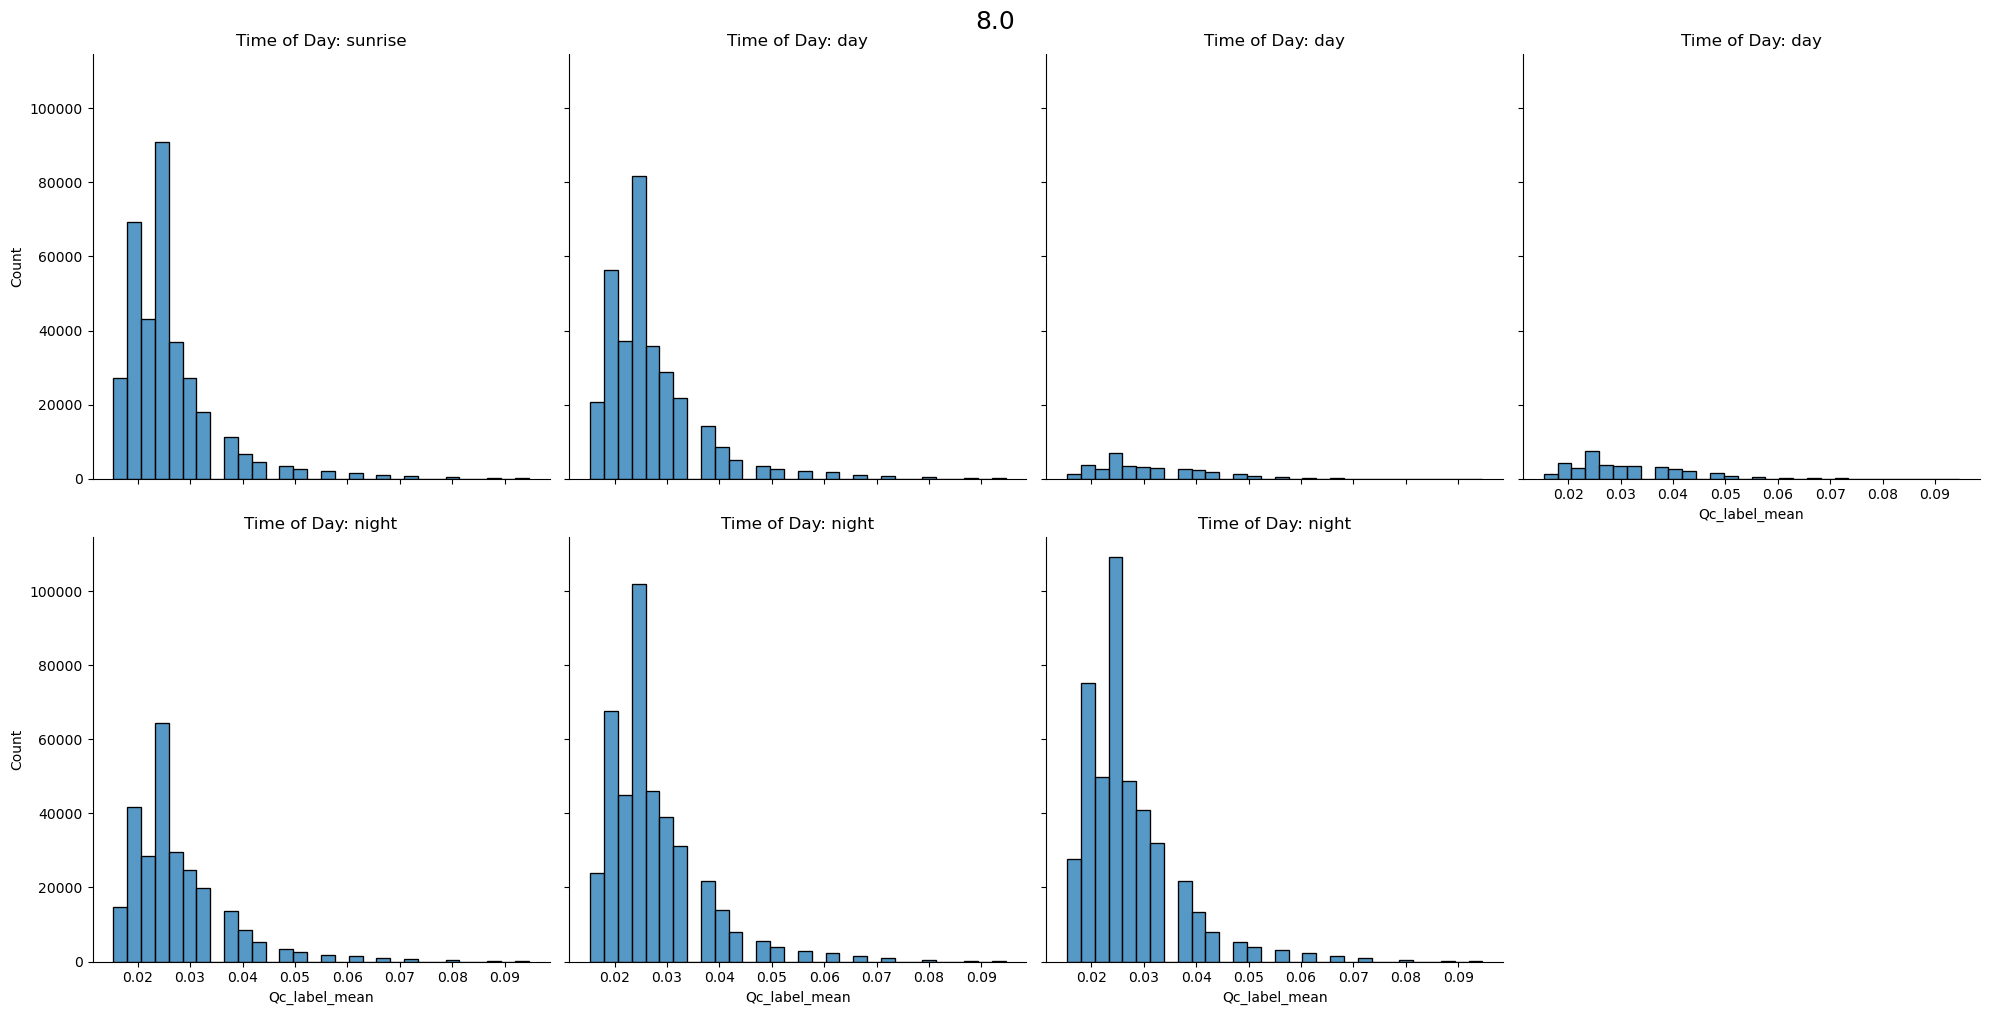

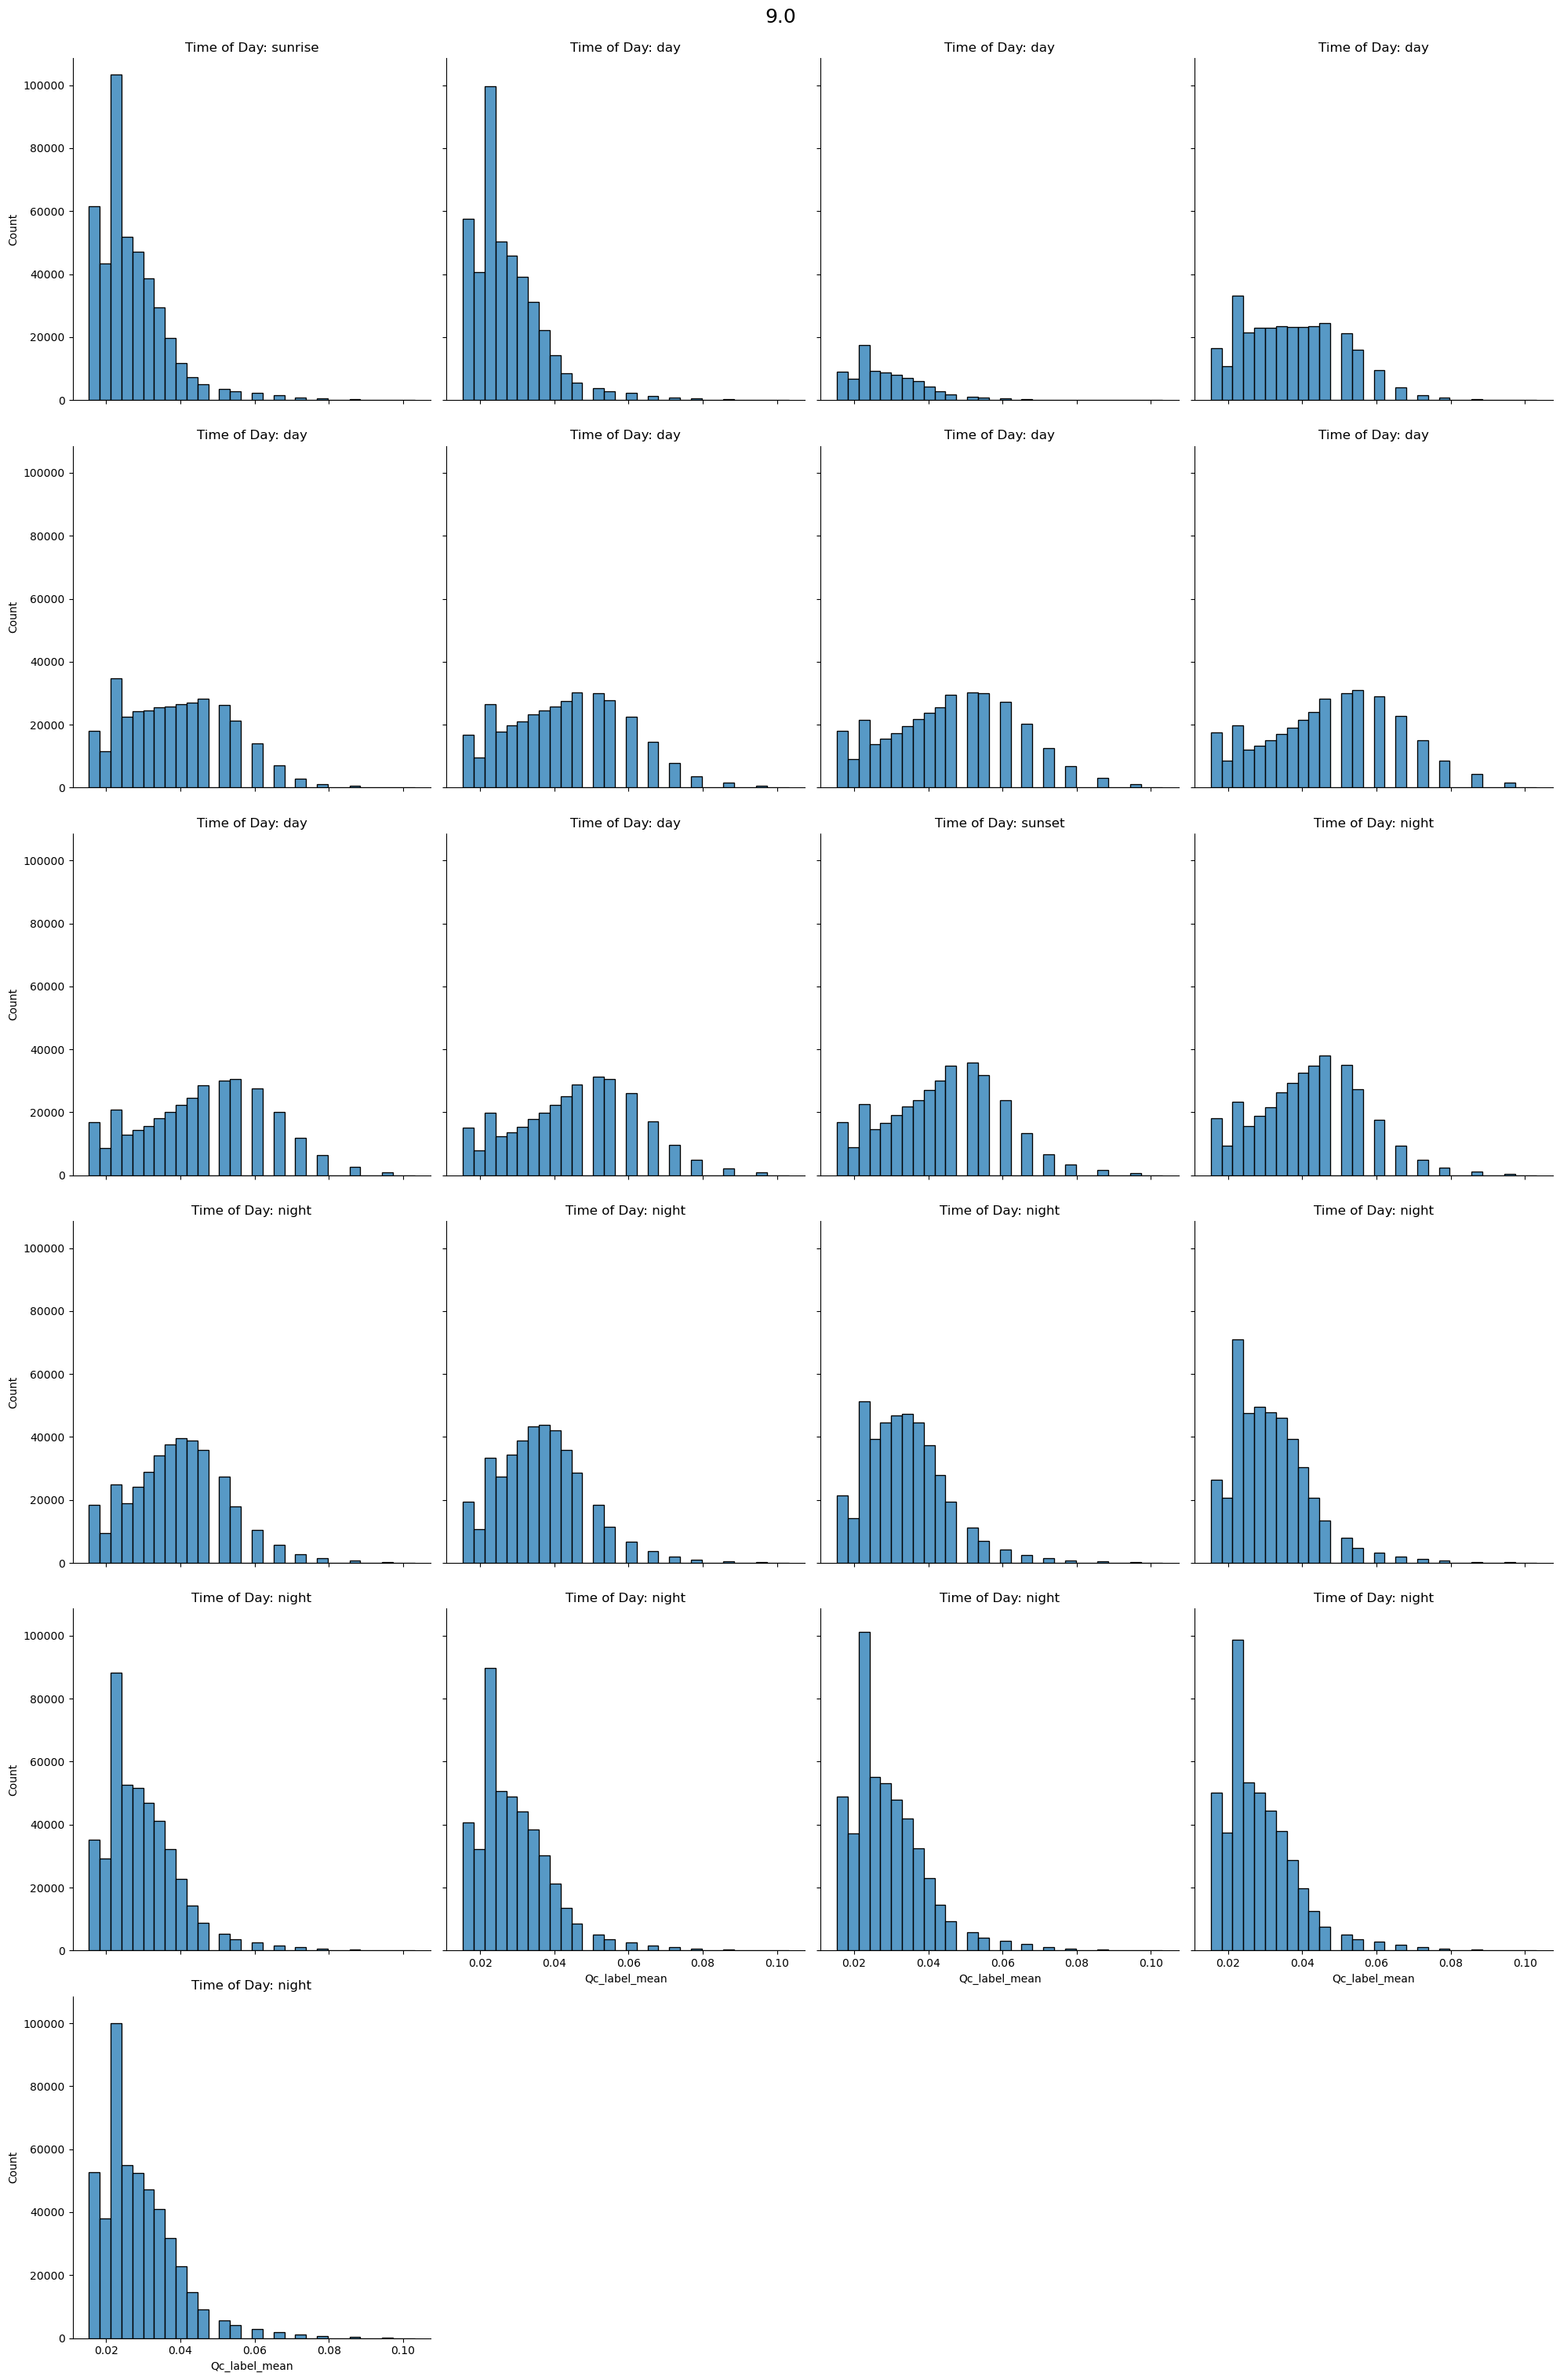

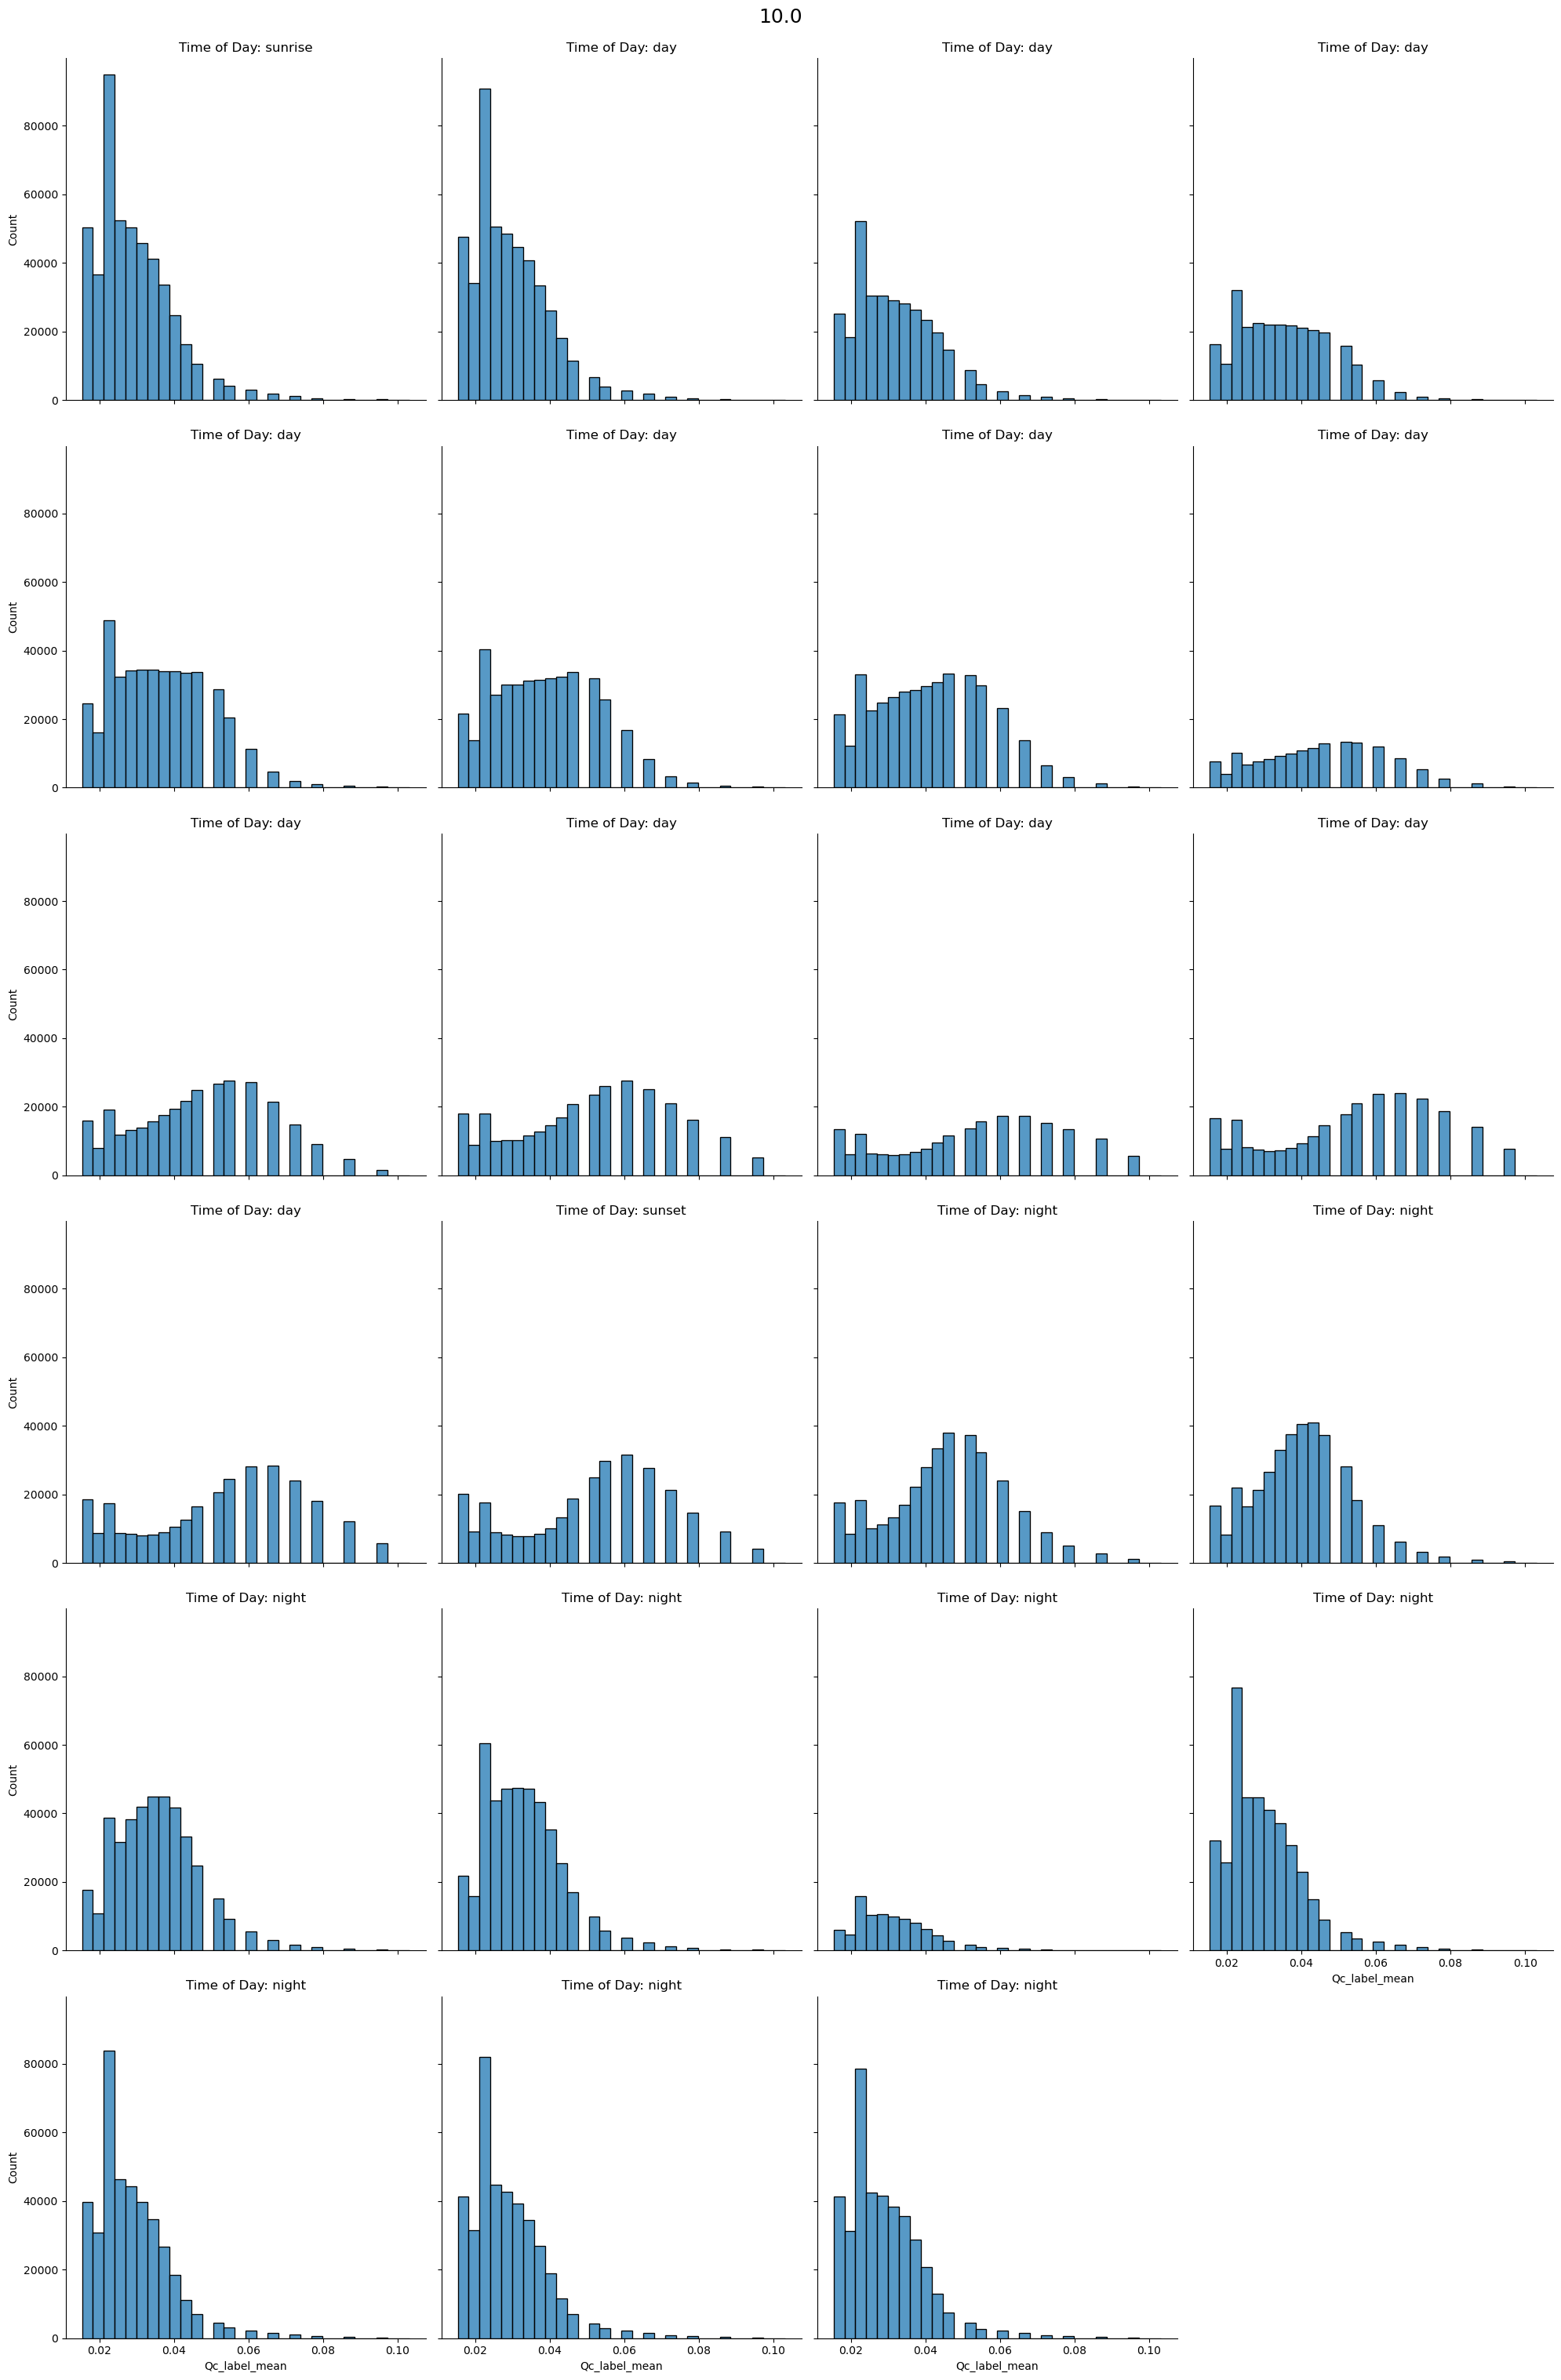

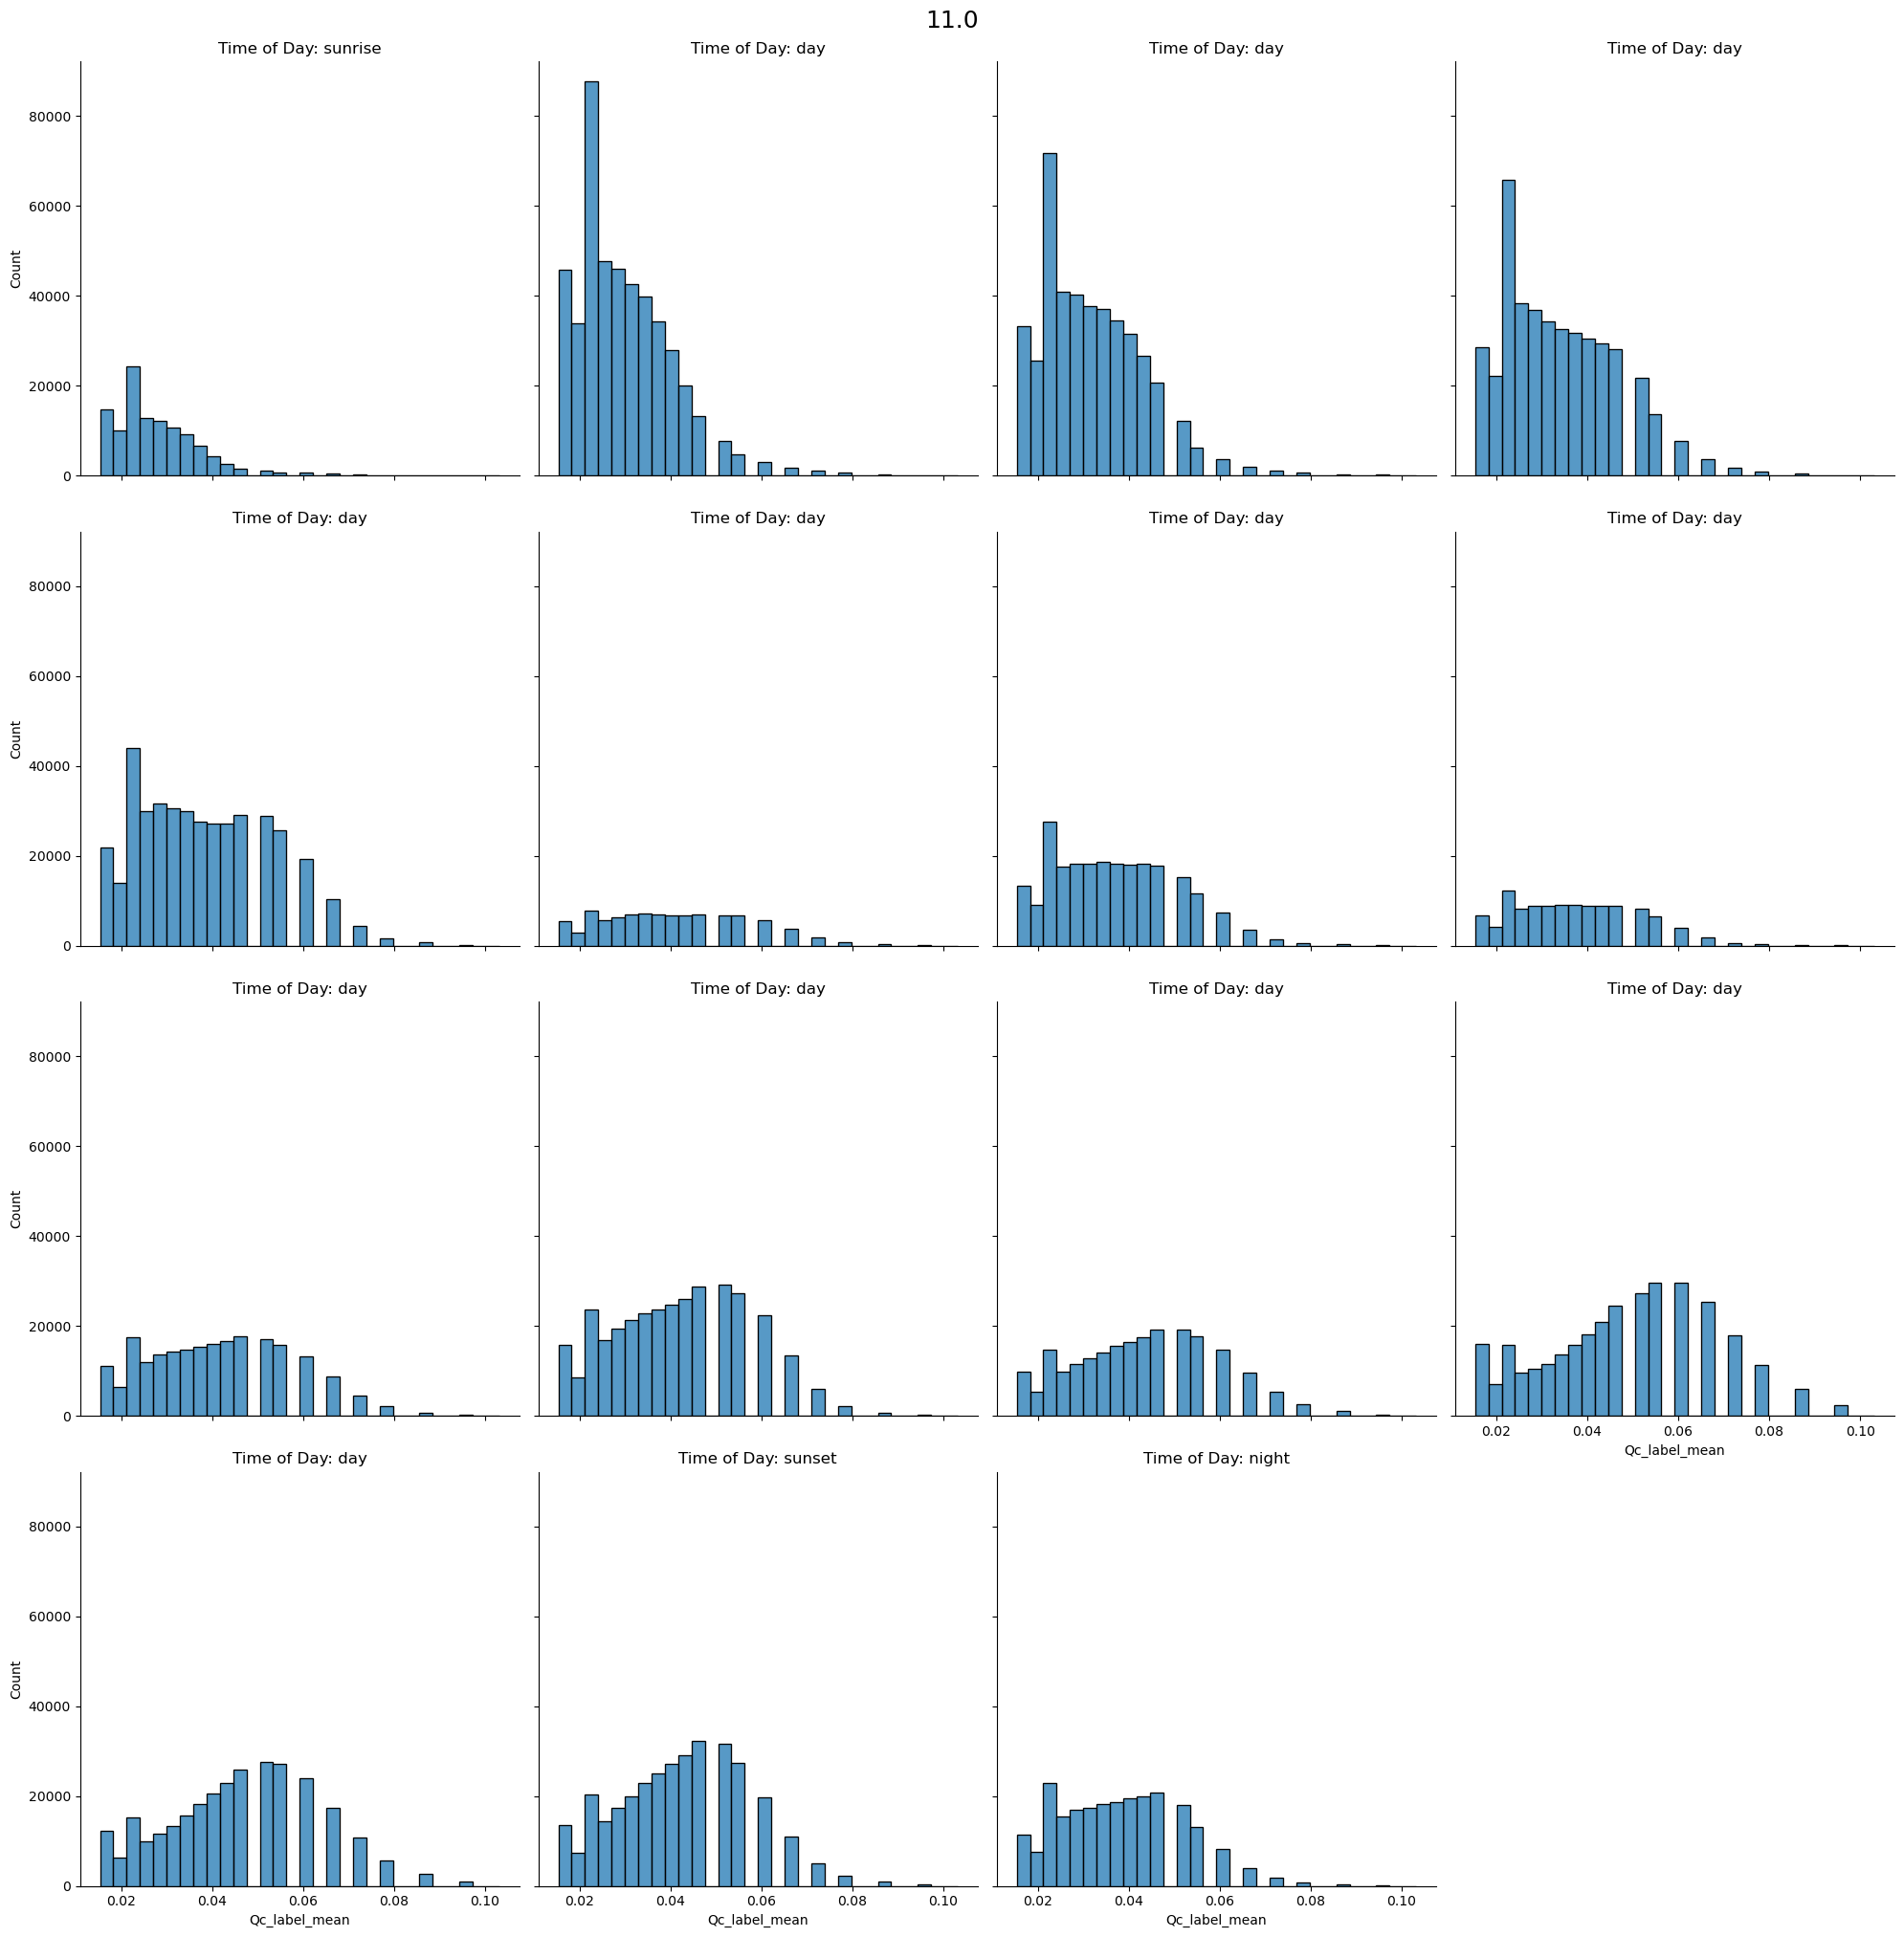

In [ ]:
# read in data
psd_bins = pd.read_parquet('../data/SCOPE_6.grid_bins.parquet')
psd_grid = pd.read_parquet('../data/SCOPE_6.hourly_gridded.parquet')
psd_grid.rename(columns = {'date': 'time'}, inplace = True)

# map to grid
mapped_labels = psd_bins.loc[pd.unique(psd_grid['Qc_coord'])].reset_index()
mapped_labels.rename(columns = {'index': 'Qc_coord', 'date': 'time'}, inplace=True)
labeled_grid = psd_grid.merge(mapped_labels)

# filter out only the pops we need
labeled_grid = labeled_grid.loc[labeled_grid['pop'].isin(pops)].reset_index(drop = True)

# redefine
diel_cruise = hot_cruise_new.loc[hot_cruise_new['cruise'] == 'KM1513']
sub_diel = diel_cruise[['cruise_day', 'pop', 'time', 'time_of_day', 'day_hour']]
# merge with diel data 
diel_grid = labeled_grid.merge(sub_diel)
# use regex to parse the ranges and calculate the mean
low_high = diel_grid['Qc_label'].str.extract(r'([\d.]+)\s*-\s*([\d.]+)').astype(float)
diel_grid['Qc_label_mean'] = low_high.mean(axis=1)

## plot PSD histogram over time 
# define col names
size_col = 'Qc_label_mean'
count_col = 'n'

# save figures into a PDF
pop = 'prochloro'
with PdfPages(f'../figures/km1513_daily_{pop}_PSD.pdf') as pdf:
    for day in diel_grid['cruise_day'].unique():
        # subset and plot
        day_df = diel_grid.loc[(diel_grid['cruise_day'] == day) & (diel_grid['pop'] == pop)]
        # build a mapping from time to time_of_day for this subset
        time_to_tod = (
            day_df[['time', 'time_of_day']]
            .drop_duplicates()
            .set_index('time')['time_of_day']
            .to_dict()
        )
        # type cast time stamps to strings
        time_to_tod = {str(k): v for k, v in time_to_tod.items()}
        # plot
        g = sns.displot(
            day_df, x=size_col, weights=count_col, col = 'time', col_wrap = 4,
            bins = 30, facet_kws=dict(margin_titles=True),
        )
        # set main title
        g.fig.suptitle(f'{day}', y = 1.01, fontsize = 18)
        # use the mapping to show time_of_day in each subplot title
        g.set_titles(col_template='Time of Day = {col_name}')
        for ax in g.axes.flatten():
            # current col_name is the 'time' value
            label = ax.get_title().split(' = ')[-1]  # or use ax.get_title() parsing if needed
            tod = time_to_tod.get(label, label)      # fallback to label if missing
            ax.set_title(f'Time of Day: {tod}')
        # save figure into pdf
        pdf.savefig(g.figure)

#### plot daily mean and median PSD per hour for Qc PSDs
__Does the peak in Qc change throughout the cruise?__
- Yes, it shifts back later in the cruise (Hour ~13-14 to ~11-12)

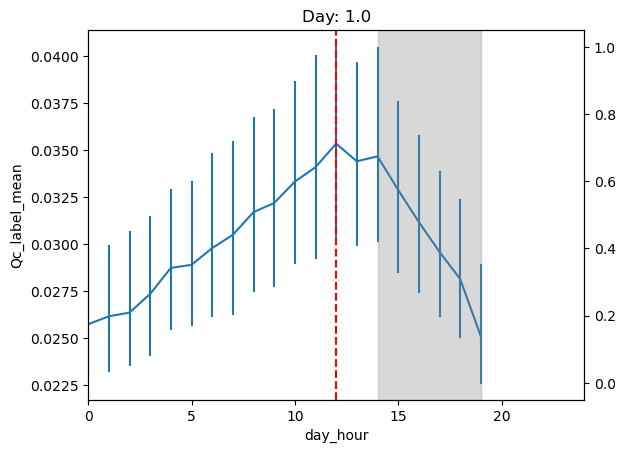

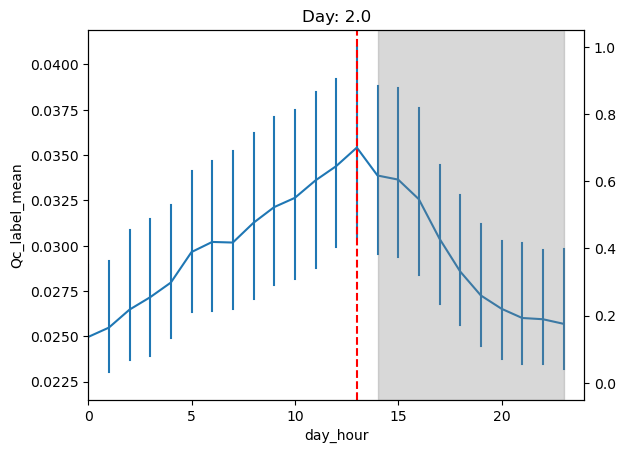

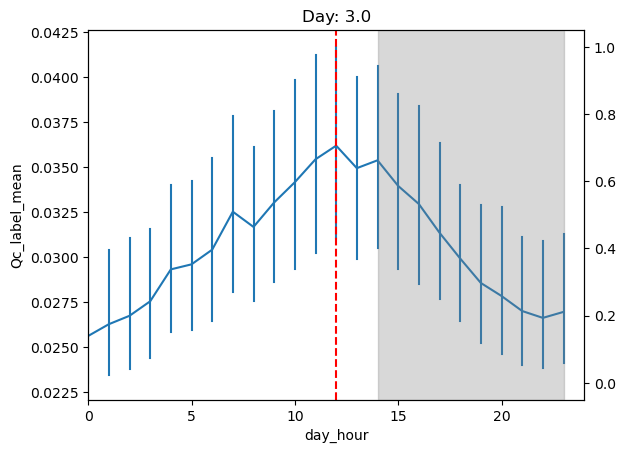

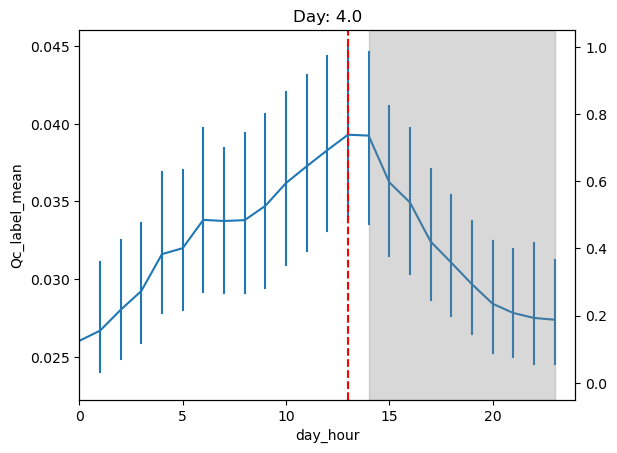

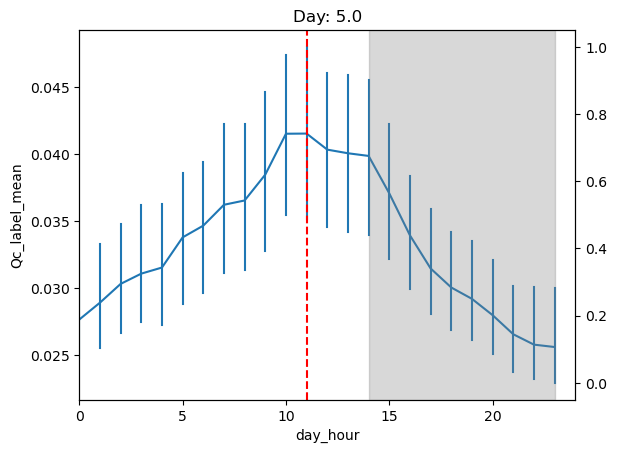

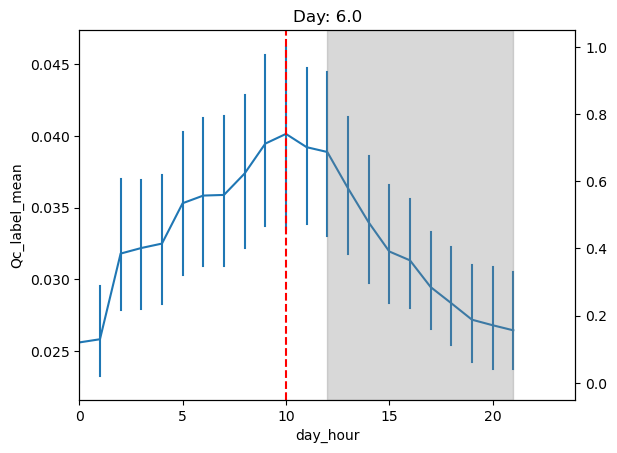

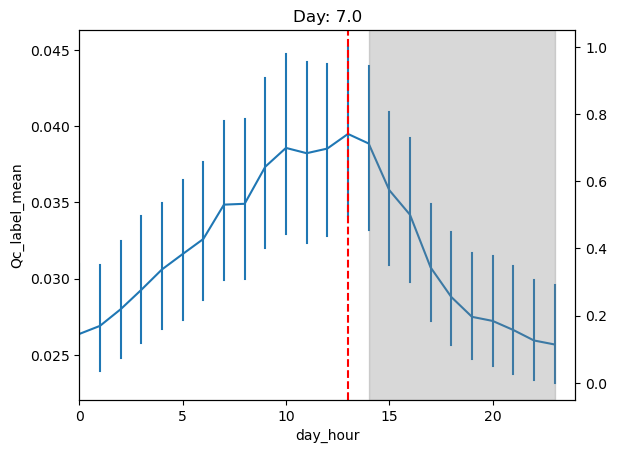

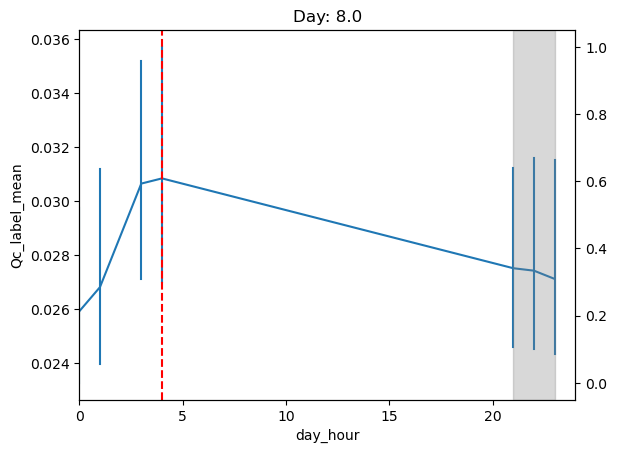

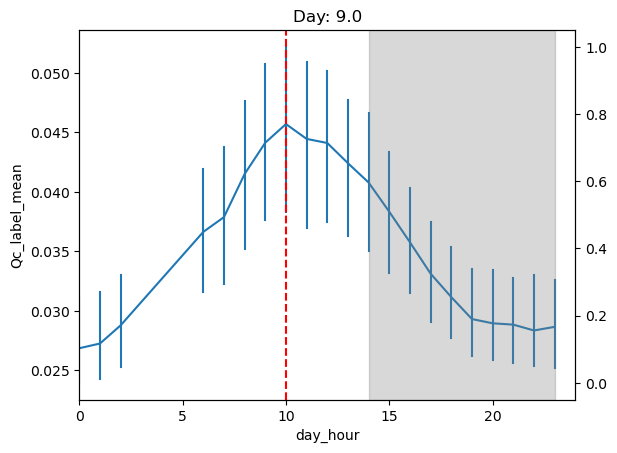

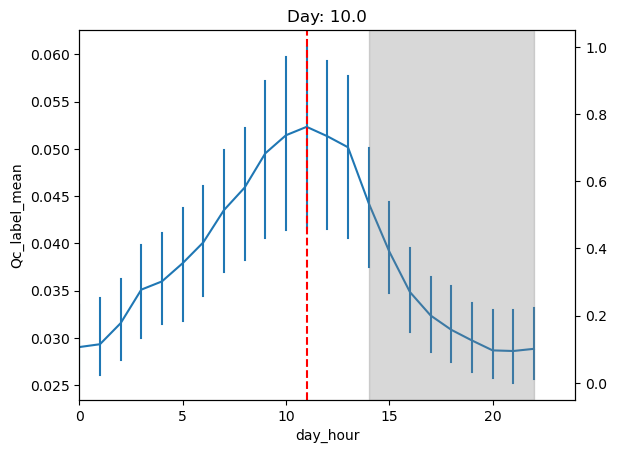

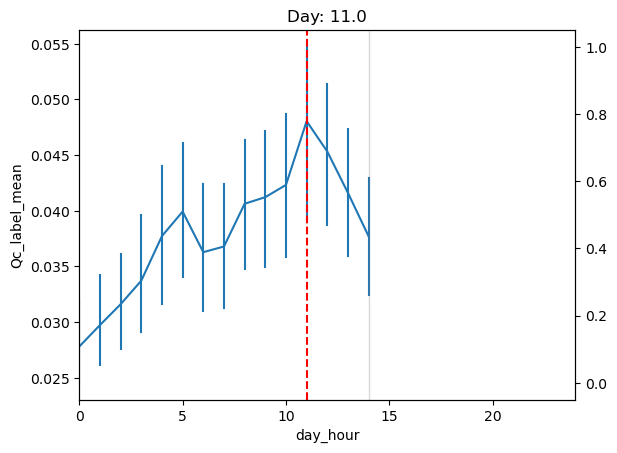

In [ ]:
pop = 'prochloro'
# make 1 plot per day
for day in diel_grid['cruise_day'].unique():
        # subset and plot
        day_df = diel_grid.loc[(diel_grid['cruise_day'] == day) & (diel_grid['pop'] == pop)]
        # build a mapping from time to time_of_day for this subset
        time_to_tod = (
            day_df[['time', 'time_of_day']]
            .drop_duplicates()
            .set_index('time')['time_of_day']
            .to_dict()
        )
        # type cast time stamps to strings
        time_to_tod = {str(k): v for k, v in time_to_tod.items()}
        ## calculate the mean Qc per hour per grid
        day_df['Qc_total'] = day_df['Qc'] * day_df['n']

        # calculate total particle count per hour
        hour_count = day_df.groupby(['day_hour'])[['n', 'Qc_total']].sum().reset_index()
        # calculate mean per hour
        hour_count['mean_Qc'] = hour_count['Qc_total'] / hour_count['n']
        max_hour = hour_count.loc[hour_count['mean_Qc'] == np.max(hour_count['mean_Qc']), 'day_hour'].values[0]

        ## make lineplot of weighted mean
        fig, axs = plt.subplots()
        sns.lineplot(day_df, x = "day_hour", y = "Qc_label_mean", weights = 'n',
                     estimator = "mean", err_style = "bars",  
                     ax = axs, markers= True)
        # show day and night
        twinax = axs.twinx()
        twinax.fill_between(day_df['day_hour'], 0, 1, where=day_df['time_of_day'] == 'night',color='gray', alpha=0.3,
                         transform=axs.get_xaxis_transform())
        # add line to show peak
        axs.axvline(x = max_hour, linestyle = '--', c = 'r')
        # show title
        axs.set_title(f"Day: {day}")
        # set lims
        axs.set_xlim(0, 24)

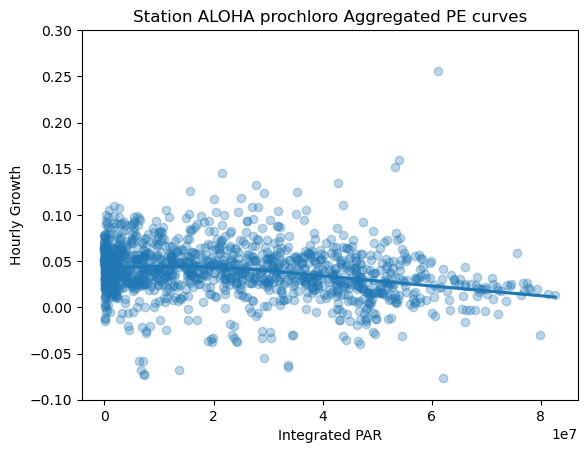

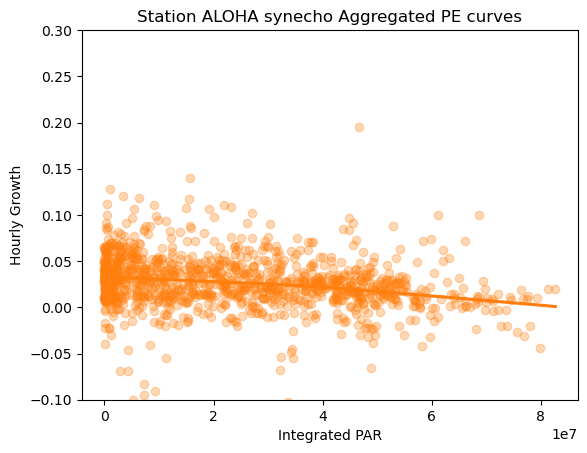

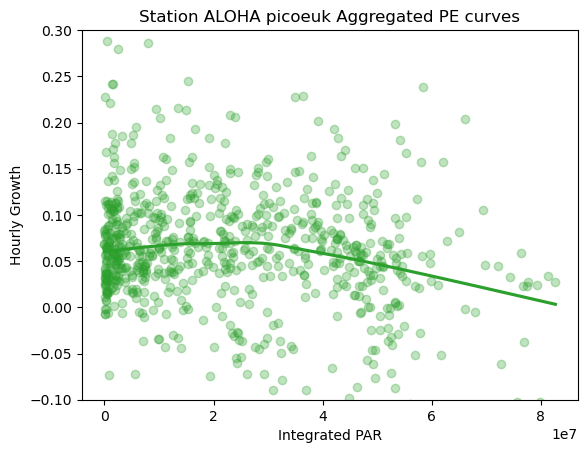

In [ ]:
### Summary plot for all cruises
# concatenate all growth rate dfs
lims = [(-0.1, 0.2), (-0.1, 0.15), (-0.1, 0.3)]
all_growth = pd.concat(growth_dfs)
for pop, c, ylim in zip(pops, colors, lims):
    pop_df = all_growth.loc[all_growth['pop'] == pop]
    g = sns.regplot(data=pop_df, x='int_par', y='slope', lowess=True, color=c, scatter_kws={'alpha': 0.3})
    # set ylims
    plt.ylim((-0.1, 0.3))
    plt.xlabel("Integrated PAR")
    plt.ylabel('Hourly Growth')
    plt.title(f'Station ALOHA {pop} Aggregated PE curves')
    plt.show()

### Show summary plot for all days in the cruise

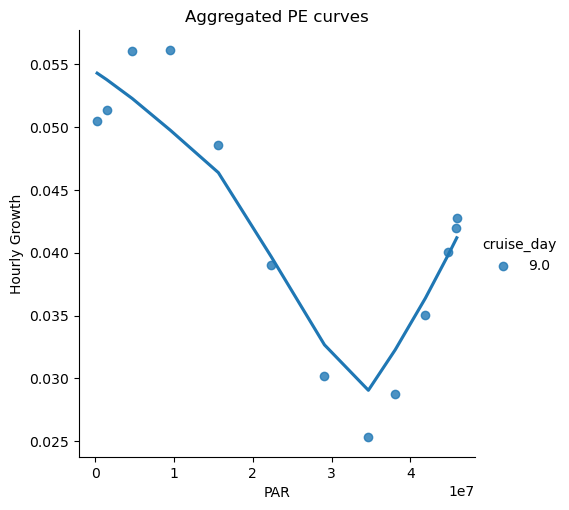

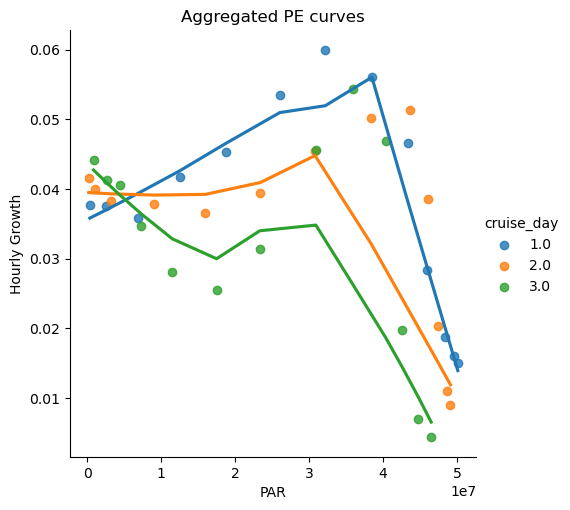

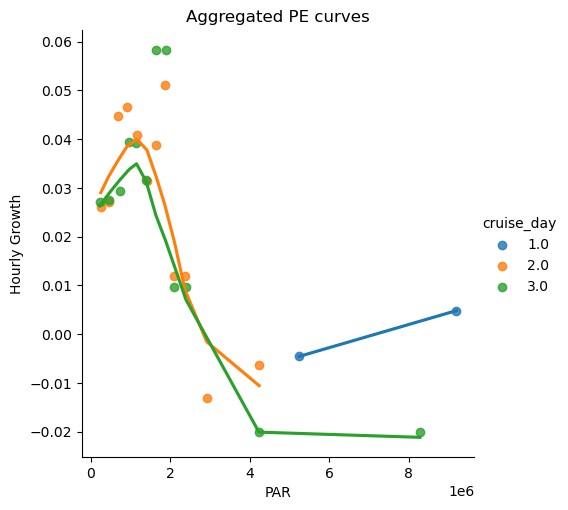

In [ ]:
for df, pop in zip(growth_dfs, pops): 
    g = sns.lmplot(df, x = 'int_par', y = 'slope', hue = 'cruise_day', lowess= True)
    plt.xlabel("PAR")
    plt.ylabel('Hourly Growth')
    plt.title(f'Aggregated PE curves')
    plt.show()

#### Int par and diel component

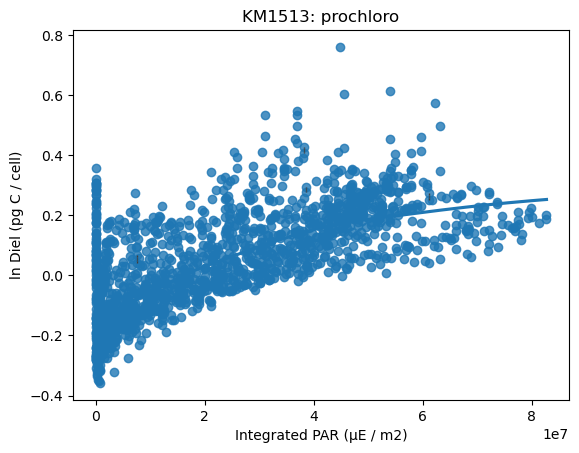

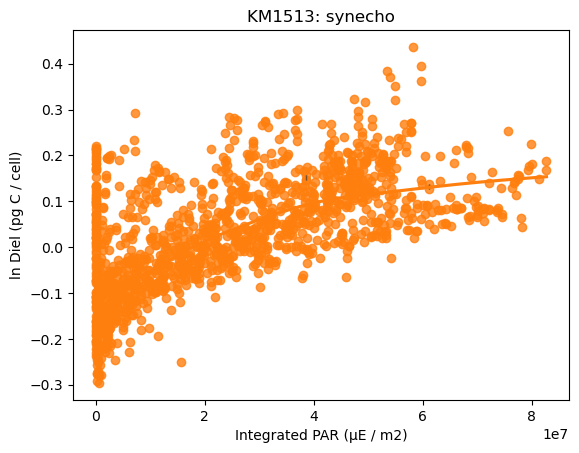

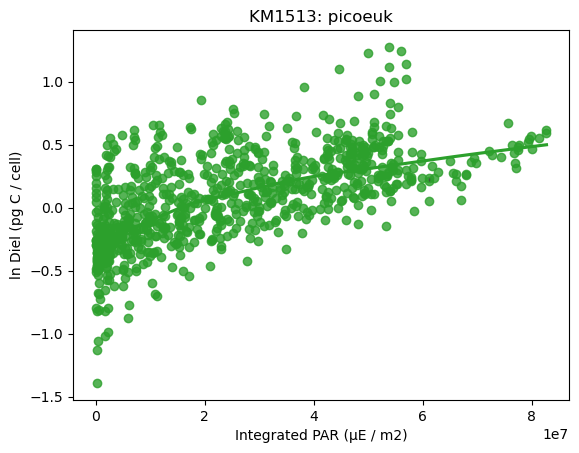

In [ ]:
# merge integrated par 
intpar_hot = smooth_cruise.copy()
## round integrated par (make 14 even bins ~ 14 hours of daylight)
# rounding by bin size
# bin = 5e6
# intpar_hot['round_intpar'] = np.round(intpar_hot['int_par'] / bin) * bin

# rounding by number of bins
nbin = 14
# return intervals as categories
par_bins = pd.cut(intpar_hot['int_par'], nbin)
intpar_hot['bin_start'] = pd.to_numeric(par_bins.apply(lambda x: x.left))
intpar_hot['bin_end'] = pd.to_numeric(par_bins.apply(lambda x: x.right))
intpar_hot['bin_mean'] = (intpar_hot['bin_start'] + intpar_hot['bin_end']) / 2

# loop through each population to make summarized figure of Qc diel 
for pop, c in zip(pops, colors):
    test_cruise = intpar_hot.loc[(intpar_hot['pop'] == pop) & (intpar_hot['time_of_day'] != 'night')]
    # temporarily convert x axis to str format
    test_cruise['bin_mean'] = pd.to_numeric(test_cruise['bin_mean'])
    # create plot object
    fig, axs = plt.subplots()
    # box plot
    sns.boxplot(test_cruise, 
            x = 'int_par', y = 'lowess_diel', showfliers = False, 
            boxprops={'facecolor': c, 'alpha': 0.75}, ax = axs, native_scale=True)
    # figure with lowess
    sns.regplot(test_cruise, 
            x = 'int_par', y = 'lowess_diel', lowess= True, 
            scatter_kws={"color": c}, line_kws={'color': c}, ax = axs)

    # # update to sci notation
    # axs.ticklabel_format(axis='x', style='sci', scilimits=(0, 0))
    
    
    plt.xlabel('Integrated PAR (µE / m2)')
    plt.ylabel('ln Diel (pg C / cell)')
    plt.title(f'KM1513: {pop}')

### Estimate hourly growth rate averaged across the entire cruise
- Calculate growth rate from each hour for all days in cruise
- Compare against integrated PAR

In [ ]:
from scipy import stats 

# calculate each day hour
intpar_hot = intpar_hot.sort_values(by=['pop', 'time'])
# create day_hour 0–23 within each day, ordered by time
intpar_hot['day_hour'] = intpar_hot.groupby(['pop', 'cruise_day']).cumcount()

#### testing ######
intpar_hot = smooth_cruise.copy()
pop = 'prochloro'
# calculate slope between each hour of the day
test_pop = intpar_hot.loc[(intpar_hot['pop'] == pop) & (intpar_hot['time_of_day'] != 'night')]
# set max
sunset_hour = np.max(test_pop['day_hour'])
## loop thru each hour of the day
# save data in a dict
growth_vals = {'hour': [],
               'slope': [],
               'yint': [],
               'par': []}
for hour in test_pop['day_hour'].unique():
    # subset
    start_diel = test_pop.loc[test_pop['day_hour'] == hour, 'lowess_diel'].values
    # set x
    hour_start = np.tile(hour, len(start_diel))
    # check if we are at the end of day
    if hour == sunset_hour:
        break
    else:
        # grab the next hour
        end_diel = test_pop.loc[test_pop['day_hour'] == hour + 1, 'lowess_diel'].values
        # set y
        hour_end = np.tile(hour+1, len(end_diel))
        # calculate slope between start and end
        x = np.concat((hour_start, hour_end))
        y = np.concat((start_diel, end_diel))
        slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
        # save into dict
        growth_vals['hour'].append(np.min(x))
        growth_vals['slope'].append(slope)
        growth_vals['yint'].append(intercept)
        growth_vals['par'].append(np.mean(test_pop.loc[test_pop['day_hour'] == hour + 1, 'par']))

daily_pe = pd.DataFrame(growth_vals)

In [ ]:
# save data in a dict
growth_vals = {'cruise_day': [],
               'hour': [],
               'slope': [],
               'yint': [],
               'par': []}
for day in test_pop['cruise_day'].unique():
    day_df = test_pop.loc[test_pop['cruise_day'] == day]
    for hour in day_df['day_hour'].unique():
        # subset
        start_diel = day_df.loc[day_df['day_hour'] == hour, 'lowess_diel'].values
        # set x
        hour_start = np.tile(hour, len(start_diel))
        # check if we are at the end of day
        if hour == sunset_hour:
            break
        else:
            # grab the next hour
            end_diel = day_df.loc[day_df['day_hour'] == hour + 1, 'lowess_diel'].values
            # set y
            hour_end = np.tile(hour+1, len(end_diel))
            # calculate slope between start and end
            x = np.concat((hour_start, hour_end))
            y = np.concat((start_diel, end_diel))
            slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
            # save into dict
            growth_vals['cruise_day'].append(day)
            growth_vals['hour'].append(np.min(x))
            growth_vals['slope'].append(slope)
            growth_vals['yint'].append(intercept)
            growth_vals['par'].append(np.mean(test_pop.loc[test_pop['day_hour'] == hour + 1, 'par']))

    daily_pe = pd.DataFrame(growth_vals)

Text(0.5, 1.0, 'KM1513: prochloro')

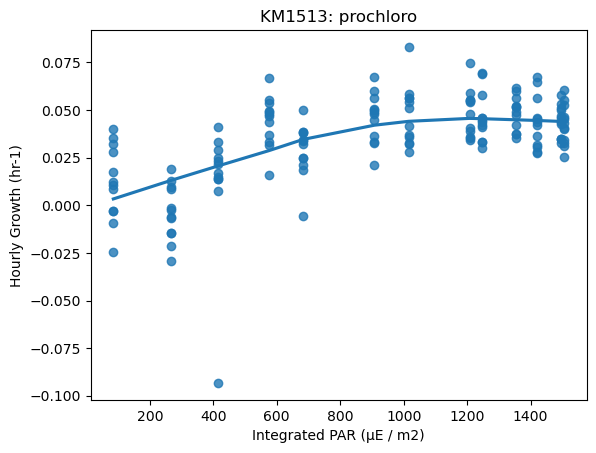

In [ ]:
## Plotting
c = colors[0]
fig, axs = plt.subplots()
sns.regplot(daily_pe, x = 'par', y = 'slope', lowess=True, scatter_kws={"color": c}, line_kws={'color': c})
axs.set_xlabel("Integrated PAR (µE / m2)")
axs.set_ylabel("Hourly Growth (hr-1)")
axs.set_title(f'KM1513: {pop}')

## PE curves
- hourly growth rate

### Adjustments to make
1) Make sure each day starts at par = 0 or rounded to 0, this may require some shifting with sunrise start
2) Recalculate growth rate starting from where par = 0 on each day

KeyError: "['hourly_growth'] not in index"

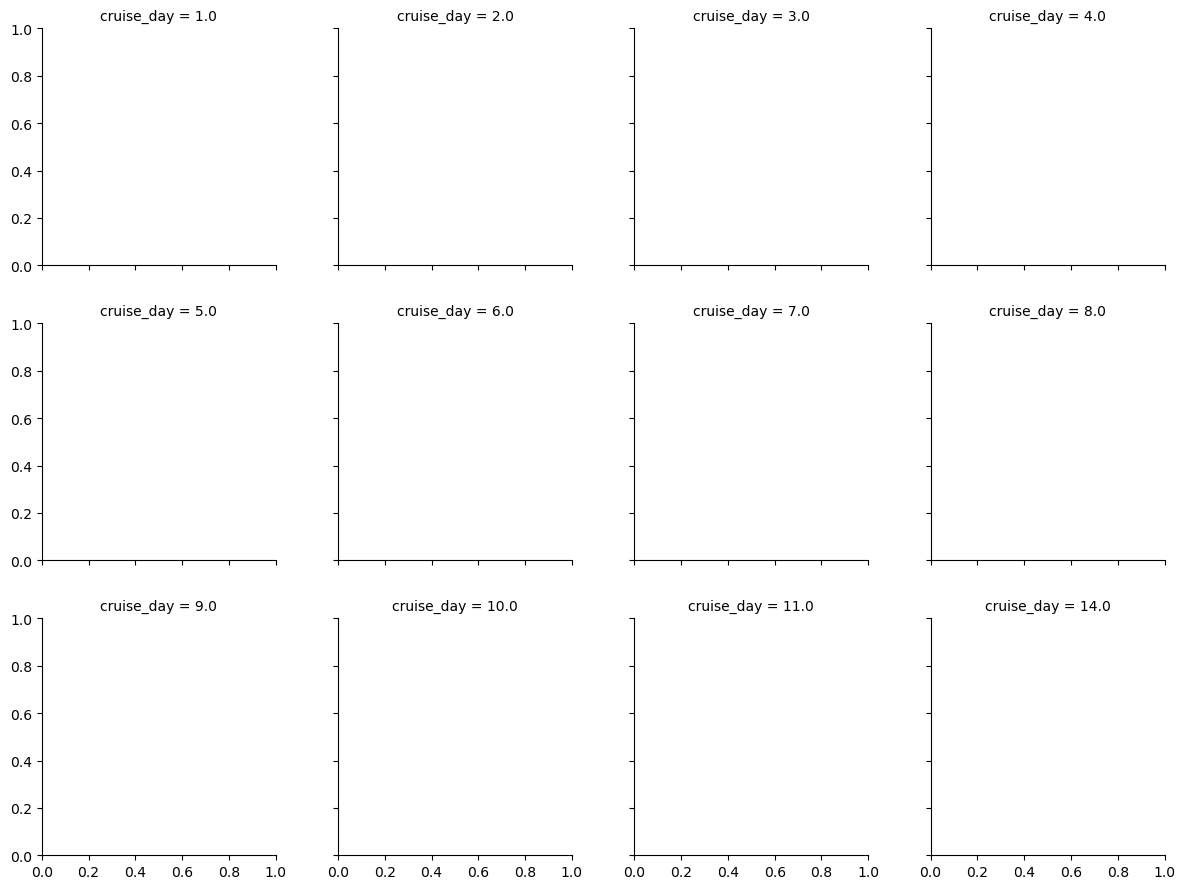

In [ ]:
# plot par vs diel component on each day
# make a loop to plot each cruise
colors = ['tab:blue', 'tab:orange', 'tab:green']
for pop, c in zip(pops, colors):
    # get subdf for each cruise
    cruise_df = smooth_cruise.loc[(smooth_cruise['pop']==pop) & (smooth_cruise['par'] >= 10)]
    # plot
    g = sns.FacetGrid(cruise_df, col="cruise_day", col_wrap = 4)
    g.map(sns.regplot, 'par', 'hourly_growth', color = c, lowess=True)
    # remove subplot titles
    g.set_titles("")
    # set cruise title
    g.figure.suptitle(f'{cruise}: {pop}')
    plt.show()
    # g.savefig(f'figures/growth_checks/synecho/{cruise}_regression.png')

    # now plot an aggregated par plot for the entire cruise
    # fig, axs = plt.subplots(figsize = (8,8))
    # sns.regplot(cruise_df, x = 'par', y = 'hourly_growth', color = c, lowess=True)


## All days PE curves
- look at G3 diel
- look at CTD chl vs. biomass at noon (high light)- do they match? if no, then maybe its the mid day nap
- plot variability of diel component vs PAR- do we see a match with the flattening? 

## Simulation data
- generate a few curves 
- increasingly add noise
- at what point does it become significantly different
- Quantify what noise threshold is my data at and if it fits the relationship that I expect it to

## Fit of function 
- Fit a regression line
- Calculate residuals
- Are my residuals significantly different from a straight line? 
- Shuffle residuals to generate a null distribution